# Estimasi Jumlah Penghuni Ruangan dengan Fuzzy Clustering dan First-Order Sugeno 

Notebook ini mengikuti alur penelitian dari memahami masalah dan data, menyusun fitur sensor, membangun fuzzy system, sampai mengevaluasi hasilnya.

**Fokus penelitian:** mengestimasi jumlah penghuni ruangan (0–3 orang) pada saat pengukuran berdasarkan sensor lingkungan. Fuzzy clustering digunakan untuk membentuk aturan, sedangkan Weighted Least Squares digunakan untuk mengestimasi konsekuen Sugeno.

Ini tidak meramalkan jumlah penghuni beberapa menit ke depan, tapi memperkirakan kondisi saat ini dari pembacaan sensor pada waktu yang sama.

**Alur kerja**
1. Memahami masalah dan dataset.
2. Melihat karakteristik sensor, target, dan waktu pengukuran.
3. Membentuk fitur yang mewakili beberapa titik sensor.
4. Menyiapkan data untuk eksperimen.
5. Membentuk cluster fuzzy dan aturan First-Order Sugeno.
6. Memilih konfigurasi dengan validation set.
7. Menguji model pada test set dan membandingkannya dengan baseline.
8. Membaca aturan, membership, dan parameter yang dipelajari.
9. Menyimpan model untuk pengembangan GUI.

## 1. Masalah, tujuan, dan ruang lingkup penelitian

Mengetahui jumlah penghuni ruangan berguna untuk pengelolaan ruang dan energi. Sistem berbasis kamera dapat menimbulkan persoalan privasi, sedangkan sensor lingkungan non-kamera menyediakan alternatif yang lebih tidak invasif. Studi ini menggunakan temperatur, cahaya, suara, CO₂, dan PIR untuk mengestimasi jumlah penghuni pada saat pengukuran.

**Rumusan masalah utama**

Bagaimana membangun model First-Order Takagi–Sugeno–Kang (TSK) yang antecedent-nya diidentifikasi melalui fuzzy clustering dan consequent-nya diestimasi dari data untuk memperkirakan jumlah penghuni ruangan?

**Pertanyaan pendukung**
1. Bagaimana karakteristik sensor, distribusi target, dan pola waktu pada dataset?
2. Bagaimana Fuzzy C-Means (FCM) dan Gustafson–Kessel (GK) membentuk partisi fuzzy pada ruang input–output?
3. Bagaimana informasi cluster diproyeksikan menjadi antecedent fuzzy yang dapat digunakan ketika target belum diketahui?
4. Bagaimana parameter consequent linear First-Order Sugeno diestimasi dengan Weighted Ridge Least Squares?
5. Bagaimana performa model pada data yang tidak digunakan untuk pelatihan, dibandingkan baseline non-fuzzy?

**Tujuan**
- Membangun sistem estimasi okupansi berbasis First-Order Sugeno.
- Membandingkan FCM dan GK untuk identifikasi struktur aturan.
- Mengestimasi parameter antecedent dan consequent secara data-driven.
- Menganalisis hasil clustering, aktivasi aturan, dan performa prediksi.
- Menyiapkan artefak model untuk implementasi GUI.

**Batasan studi**
- Dataset berasal dari satu ruang eksperimen berukuran 6 m × 4,6 m.
- Target adalah jumlah penghuni 0, 1, 2, atau 3 orang.
- Model mengestimasi okupansi pada waktu pembacaan sensor, bukan memprediksi beberapa menit ke depan.
- Tidak ada klaim bahwa model otomatis berlaku pada ruangan atau gedung lain.
- Aturan dibentuk secara data-driven; tidak diperlukan expert untuk memberi label setiap aturan. Interpretasi aturan tetap harus dibahas secara hati-hati karena cluster bukan otomatis label semantik seperti “rendah” atau “tinggi”.

## 1A. Kesesuaian tugas dan landasan literatur

Instruksi proyek individu mengarahkan untuk studi kasus nyata, latar belakang, rumusan masalah, tujuan, teori fuzzy, pemilihan model fuzzy, fuzzy clustering beserta formulasi dan hasilnya, estimasi parameter, perancangan rule base, simulasi, analisis, implementasi Python, serta minimal tiga referensi ilmiah. Notebook ini disusun agar setiap komponen tersebut ada. Random Forest dan Dummy Mean hanya pembanding tambahan.

| Ketentuan tugas | Bagian notebook |
|---|---|
| Studi kasus, latar belakang, rumusan masalah, tujuan | Bagian 1–2 |
| Dataset dan EDA | Bagian 2–3 |
| Konsep fuzzy, model Sugeno, membership, inferensi | Bagian 7 |
| Fuzzy clustering dan formulasi FCM/GK | Bagian 7–8 |
| Hasil cluster, pusat, membership, visualisasi | Bagian 10 |
| Estimasi parameter antecedent dan consequent | Bagian 7, 9–10 |
| Input-output, rule base, inferensi | Bagian 7, 10 |
| Simulasi dan analisis performa | Bagian 9–10 |
| Implementasi Python dan artefak model | Bagian 11 |
| GUI | Disediakan sebagai aplikasi Streamlit pendamping setelah bundle model dibuat |

### Referensi yang benar-benar relevan dengan rancangan

1. **Luthfi (2007), “Fuzzy C-Means untuk Clustering Data”** — menjelaskan partisi fuzzy, derajat keanggotaan, pusat cluster, objective FCM, dan iterasi pembaruan membership.
2. **Babuška, “Fuzzy and Neural Control”, Chapter 4** — menjelaskan hard/fuzzy partition, FCM, GK, matriks kovarians, serta interpretasi eigenvalue dan eigenvector sebagai bentuk dan orientasi cluster.
3. **Gómez-Skarmeta, Delgado, dan Vila (1999)** — sangat dekat dengan rancangan proyek: fuzzy clustering pada ruang input–output untuk identifikasi aturan TSK dengan consequent fungsional; antecedent dibentuk dari informasi cluster yang diproyeksikan ke ruang input.
4. **Takagi dan Sugeno (1985)** — landasan First-Order TSK, local linear consequent, identifikasi struktur dan parameter dari pasangan input–output.
5. **Singh et al. (2018)** — paper pengantar dataset okupansi dengan sensor non-intrusif CO₂, temperatur, cahaya, suara, dan gerak.

## 2. Mengenal dataset dan susunan sensornya

Dataset yang digunakan adalah **Room Occupancy Estimation** dari UCI Machine Learning Repository. Data berisi 10.129 pengamatan dari eksperimen terkontrol. Sensor mengirim pembacaan dengan interval nominal sekitar 30 detik; ground truth jumlah penghuni dicatat secara manual.

Satu baris mewakili satu waktu pengukuran, bukan satu orang atau satu sesi independen.

| Node sensor | Pengukuran |
|---|---|
| S1 | Temperatur, cahaya, suara |
| S2 | Temperatur, cahaya, suara |
| S3 | Temperatur, cahaya, suara |
| S4 | Temperatur, cahaya, suara |
| S5 | CO₂ dan CO₂ slope |
| S6 | PIR |
| S7 | PIR |

Jadi, empat kolom temperatur, empat kolom cahaya, dan empat kolom suara memang berasal dari empat titik sensor berbeda. Nilainya tidak harus sama karena posisi dan kondisi lokal di sekitar sensor dapat berbeda.

Informasi ini dipertahakan saat membentuk fitur: selain rata-rata empat sensor, juga menghitung simpangan bakunya untuk melihat seberapa berbeda pembacaan antar-titik.

**Sumber dataset:** Singh, A. & Chaudhari (2018), UCI Machine Learning Repository, DOI: [10.24432/C5P605](https://doi.org/10.24432/C5P605).

UCI mendeskripsikan data sebagai multivariate time-series dengan 10.129 observasi, tujuh node sensor, interval nominal 30 detik, dan target ground truth 0–3 orang yang dicatat manual. Metadata UCI juga menyebutkan tidak ada missing values pada file rujukan. EDA tetap memeriksa missing values untuk memastikan file yang dipakai sesuai sumber dan tidak berubah.

In [1]:
%pip -q install numpy pandas matplotlib seaborn scikit-learn joblib requests

Note: you may need to restart the kernel to use updated packages.


In [2]:
# 1. Import library dan konfigurasi
import io
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import joblib
from IPython.display import display

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, accuracy_score,
    f1_score, balanced_accuracy_score, confusion_matrix,
    classification_report, adjusted_rand_score
)
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Working directory:", Path.cwd())

Pandas: 2.3.3
NumPy: 2.1.3
Working directory: /kaggle/working


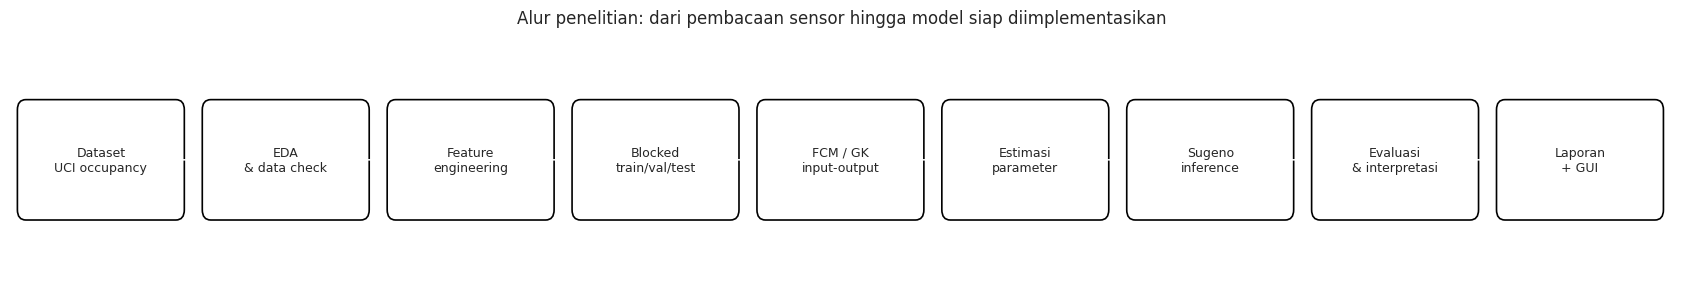

In [ ]:
# Visualisasi alur penelitian
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

pipeline_steps = [
    "Dataset\nUCI occupancy", "EDA\n& data check", "Feature\nengineering",
    "Blocked\ntrain/val/test", "FCM / GK\ninput-output", "Estimasi\nparameter",
    "Sugeno\ninference", "Evaluasi\n& interpretasi", "Laporan\n+ GUI"
]
fig, ax = plt.subplots(figsize=(17, 3.2))
ax.set_xlim(0, len(pipeline_steps) * 1.75)
ax.set_ylim(0, 2)
ax.axis("off")
for i, label in enumerate(pipeline_steps):
    x = 0.15 + i * 1.75
    patch = FancyBboxPatch(
        (x, 0.65), 1.42, 0.78,
        boxstyle="round,pad=0.08,rounding_size=0.08",
        edgecolor="black", facecolor="white", linewidth=1.2
    )
    ax.add_patch(patch)
    ax.text(x + 0.71, 1.04, label, ha="center", va="center", fontsize=9)
    if i < len(pipeline_steps) - 1:
        ax.add_patch(FancyArrowPatch(
            (x + 1.45, 1.04), (x + 1.69, 1.04),
            arrowstyle="->", mutation_scale=12, linewidth=1.1
        ))
ax.set_title("Alur penelitian: dari pembacaan sensor hingga model siap diimplementasikan", pad=10)
plt.tight_layout()
plt.show()

In [ ]:
# 2. Memuat dataset

LOCAL_CANDIDATES = [
    Path("Occupancy_Estimation.csv"),
    Path("./data/Occupancy_Estimation.csv"),
    Path("/content/Occupancy_Estimation.csv"),
]

def load_occupancy_dataset():
    for file_path in LOCAL_CANDIDATES:
        if file_path.exists():
            print(f"Memuat dataset lokal: {file_path.resolve()}")
            return pd.read_csv(file_path)

    urls = [
        "https://archive.ics.uci.edu/static/public/864/room+occupancy+estimation.zip",
        "https://cdn.uci-ics-mlr-prod.aws.uci.edu/864/room%2Boccupancy%2Bestimation.zip",
    ]
    last_error = None

    for url in urls:
        try:
            print("Mengunduh dataset dari UCI...")
            response = requests.get(url, timeout=60)
            response.raise_for_status()

            with zipfile.ZipFile(io.BytesIO(response.content)) as zf:
                csv_files = [
                    name for name in zf.namelist()
                    if Path(name).name.lower() == "occupancy_estimation.csv"
                ]
                if not csv_files:
                    raise FileNotFoundError("CSV tidak ditemukan di dalam ZIP UCI.")
                with zf.open(csv_files[0]) as f:
                    data = pd.read_csv(f)

            data.to_csv("Occupancy_Estimation.csv", index=False)
            print("Dataset tersimpan sebagai Occupancy_Estimation.csv")
            return data

        except Exception as exc:
            last_error = exc
            print(f"Percobaan unduh gagal: {type(exc).__name__}: {exc}")

    raise RuntimeError(
        "Dataset belum berhasil dimuat. Unduh Occupancy_Estimation.csv"
        f"Error terakhir: {last_error}"
    )

df = load_occupancy_dataset()
df.columns = [str(col).strip() for col in df.columns]
print("Ukuran dataset:", df.shape)
display(df.head())

Mengunduh dataset dari UCI...
Dataset tersimpan sebagai Occupancy_Estimation.csv
Ukuran dataset: (10129, 19)


,Date,Time,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,Room_Occupancy_Count
0,2017/12/22,10:49:41,24.94,24.75,24.56,25.38,121,34,53,40,0.08,0.19,0.06,0.06,390,0.769231,0,0,1
1,2017/12/22,10:50:12,24.94,24.75,24.56,25.44,121,33,53,40,0.93,0.05,0.06,0.06,390,0.646154,0,0,1
2,2017/12/22,10:50:42,25.00,24.75,24.50,25.44,121,34,53,40,0.43,0.11,0.08,0.06,390,0.519231,0,0,1
3,2017/12/22,10:51:13,25.00,24.75,24.56,25.44,121,34,53,40,0.41,0.10,0.10,0.09,390,0.388462,0,0,1
4,2017/12/22,10:51:44,25.00,24.75,24.56,25.44,121,34,54,40,0.18,0.06,0.06,0.06,390,0.253846,0,0,1


In [5]:
# 3. Menyiapkan kolom dan waktu pengukuran

TARGET = "Room_Occupancy_Count"

sensor_columns = (
    [f"S{i}_Temp" for i in range(1, 5)]
    + [f"S{i}_Light" for i in range(1, 5)]
    + [f"S{i}_Sound" for i in range(1, 5)]
    + ["S5_CO2", "S5_CO2_Slope", "S6_PIR", "S7_PIR"]
)
required_columns = ["Date", "Time", TARGET] + sensor_columns

missing_columns = sorted(set(required_columns) - set(df.columns))
if missing_columns:
    raise ValueError(f"Kolom yang dibutuhkan tidak ditemukan: {missing_columns}")

for col in sensor_columns + [TARGET]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

timestamp_text = (
    df["Date"].astype(str).str.strip()
    + " "
    + df["Time"].astype(str).str.strip()
)
df["timestamp"] = pd.to_datetime(timestamp_text, errors="coerce")

if df["timestamp"].isna().any():
    raise ValueError("Ada timestamp yang gagal dibaca. Periksa kolom Date dan Time.")

df = df.sort_values("timestamp", kind="stable").reset_index(drop=True)

missing_target = int(df[TARGET].isna().sum())
if missing_target:
    print(f"Menghapus {missing_target} baris tanpa target.")
    df = df.dropna(subset=[TARGET]).reset_index(drop=True)

df[TARGET] = df[TARGET].astype(int)
allowed_classes = {0, 1, 2, 3}
observed_classes = set(df[TARGET].unique())

if not observed_classes.issubset(allowed_classes):
    raise ValueError(f"Nilai target di luar rentang 0–3: {sorted(observed_classes)}")

print("Jumlah observasi:", len(df))
print("Periode data:", df["timestamp"].min(), "sampai", df["timestamp"].max())
print("Kelas target:", sorted(observed_classes))
display(df[["Date", "Time", "timestamp", TARGET]].head())

Jumlah observasi: 10129
Periode data: 2017-12-22 10:49:41 sampai 2018-01-11 09:00:09
Kelas target: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


,Date,Time,timestamp,Room_Occupancy_Count
0,2017/12/22,10:49:41,2017-12-22 10:49:41,1
1,2017/12/22,10:50:12,2017-12-22 10:50:12,1
2,2017/12/22,10:50:42,2017-12-22 10:50:42,1
3,2017/12/22,10:51:13,2017-12-22 10:51:13,1
4,2017/12/22,10:51:44,2017-12-22 10:51:44,1


## 3. Melihat pola data

Sebelum menentukan membership function dan rule base, lihat bagaimana data tersebar. Bagian ini membantu menjawab pertanyaan target mana yang paling sering muncul, sensor mana yang punya rentang lebar, apakah ada nilai kosong, dan bagaimana pola pengukurannya sepanjang waktu.

Disclaimer:
- Distribusi yang tidak normal bukan otomatis masalah untuk FCM atau GK.
- Outlier yang terdeteksi belum tentu kesalahan sensor.
- Korelasi negatif sama pentingnya dengan korelasi positif.
- Baris yang berdekatan dalam waktu cenderung saling berkaitan.

**Catatan pembentukan sesi:** dataset tidak menyediakan label sesi eksperimen khusus. Karena itu, `session_id` di notebook ini adalah segmentasi operasional berdasarkan jeda timestamp lebih dari enam jam, bukan metadata sesi resmi dari UCI. Ambang ini dipakai untuk memudahkan pembacaan pola temporal dan tidak menjadi fitur prediktor.

In [6]:
# 4. Ringkasan kondisi data

print("Ukuran data:", df.shape)
print("\nTipe data:")
display(df.dtypes.to_frame("dtype"))

print("\nNilai kosong:")
display(df[required_columns].isna().sum().to_frame("missing_count"))

print("\nDuplikasi:")
print("Duplikasi seluruh baris:", int(df.duplicated().sum()))
print("Timestamp duplikat:", int(df["timestamp"].duplicated().sum()))

print("\nRingkasan numerik:")
display(df[sensor_columns + [TARGET]].describe().T)

Ukuran data: (10129, 20)

Tipe data:


,dtype
Date,object
Time,object
S1_Temp,float64
S2_Temp,float64
S3_Temp,float64
S4_Temp,float64
S1_Light,int64
S2_Light,int64
S3_Light,int64
S4_Light,int64



Nilai kosong:


,missing_count
Date,0
Time,0
Room_Occupancy_Count,0
S1_Temp,0
S2_Temp,0
S3_Temp,0
S4_Temp,0
S1_Light,0
S2_Light,0
S3_Light,0



Duplikasi:
Duplikasi seluruh baris: 0
Timestamp duplikat: 0

Ringkasan numerik:


,count,mean,std,min,25%,50%,75%,max
S1_Temp,10129.0,25.454012,0.351351,24.940000,25.190000,25.38,25.63,26.380000
S2_Temp,10129.0,25.546059,0.586325,24.750000,25.190000,25.38,25.63,29.000000
S3_Temp,10129.0,25.056621,0.427283,24.440000,24.690000,24.94,25.38,26.190000
S4_Temp,10129.0,25.754125,0.356434,24.940000,25.440000,25.75,26.00,26.560000
S1_Light,10129.0,25.445059,51.011264,0.000000,0.000000,0.00,12.00,165.000000
S2_Light,10129.0,26.016290,67.304170,0.000000,0.000000,0.00,14.00,258.000000
S3_Light,10129.0,34.248494,58.400744,0.000000,0.000000,0.00,50.00,280.000000
S4_Light,10129.0,13.220259,19.602219,0.000000,0.000000,0.00,22.00,74.000000
S1_Sound,10129.0,0.168178,0.316709,0.060000,0.070000,0.08,0.08,3.880000
S2_Sound,10129.0,0.120066,0.266503,0.040000,0.050000,0.05,0.06,3.440000


Interval pengukuran yang paling sering:


,jumlah
timestamp,
0 days 00:00:31,6373
0 days 00:00:30,3614
0 days 00:01:01,131
0 days 00:02:34,2
0 days 00:01:02,2
0 days 00:01:32,1
0 days 00:25:32,1
0 days 00:03:35,1
0 days 00:03:04,1



Ringkasan interval:


,detik
count,1.012800e+04
mean,1.699672e+02
std,1.312961e+04
min,3.000000e+01
25%,3.000000e+01
50%,3.100000e+01
75%,3.100000e+01
max,1.318547e+06


,session_id,jumlah_baris,mulai,selesai,durasi_jam,kelas_target
0,0,5305,2017-12-22 10:49:41,2017-12-24 09:10:50,46.352500,"[0, 1, 2, 3]"
1,1,2779,2017-12-25 09:11:42,2017-12-26 09:10:01,23.971944,[0]
2,2,2045,2018-01-10 15:25:48,2018-01-11 09:00:09,17.572500,"[0, 2, 3]"


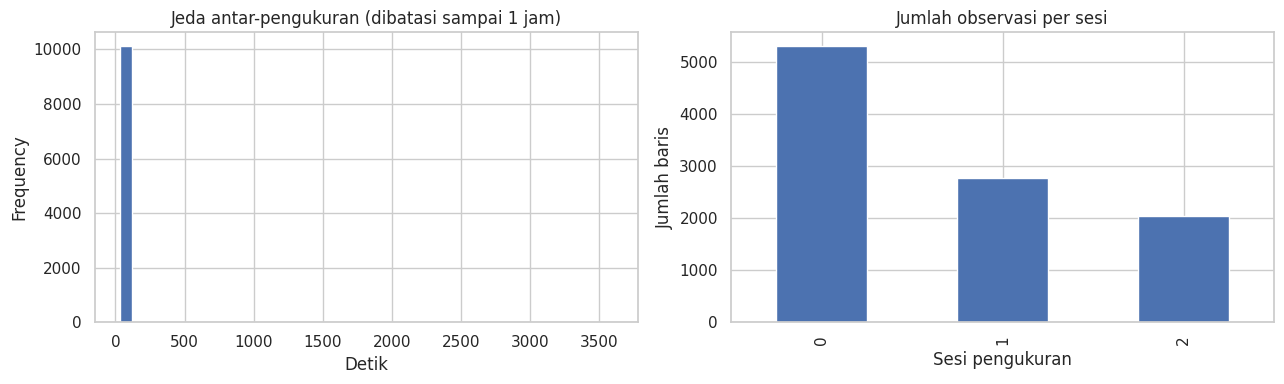

In [7]:
# 5. Melihat jeda waktu dan sesi pengukuran

time_gap = df["timestamp"].diff()
gap_seconds = time_gap.dt.total_seconds()

print("Interval pengukuran yang paling sering:")
display(time_gap.value_counts().head(10).to_frame("jumlah"))

print("\nRingkasan interval:")
display(gap_seconds.describe().to_frame("detik"))

# Jeda lebih dari 6 jam diperlakukan sebagai batas sesi pengukuran baru.
SESSION_GAP = pd.Timedelta(hours=6)
df["session_id"] = (time_gap > SESSION_GAP).cumsum().astype(int)

session_rows = []
for session_id, part in df.groupby("session_id"):
    session_rows.append({
        "session_id": session_id,
        "jumlah_baris": len(part),
        "mulai": part["timestamp"].min(),
        "selesai": part["timestamp"].max(),
        "durasi_jam": (
            part["timestamp"].max() - part["timestamp"].min()
        ).total_seconds() / 3600,
        "kelas_target": sorted(part[TARGET].unique().tolist())
    })

session_summary = pd.DataFrame(session_rows)
display(session_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
gap_seconds.dropna().clip(upper=3600).plot(
    kind="hist", bins=40, ax=axes[0]
)
axes[0].set_title("Jeda antar-pengukuran (dibatasi sampai 1 jam)")
axes[0].set_xlabel("Detik")

df["session_id"].value_counts().sort_index().plot(kind="bar", ax=axes[1])
axes[1].set_title("Jumlah observasi per sesi")
axes[1].set_xlabel("Sesi pengukuran")
axes[1].set_ylabel("Jumlah baris")
plt.tight_layout()
plt.show()

### Mengapa pembagian data tidak cukup hanya kronologis?

Data sensor berurutan waktu, sehingga random split per baris dapat membuat observasi yang hampir identik masuk ke train dan test. Namun, pembagian kronologis murni juga perlu diperiksa: jika periode terakhir hanya berisi okupansi 0, test set tidak dapat menilai kemampuan model pada kelas 1, 2, dan 3.

Karena itu, ditampilkan diagnostik kronologis terlebih dahulu. Protokol utama berikutnya menggunakan blok waktu utuh yang dibagi secara stratified agar semua kelas terwakili. Hasilnya harus disebut sebagai **blocked internal holdout**, bukan uji forecasting masa depan.

Distribusi kelas pada split kronologis murni:


,chron_train,chron_validation,chron_test
Room_Occupancy_Count,,,
0,5483,1225,1520
1,459,0,0
2,655,93,0
3,493,201,0


,chron_train,chron_validation,chron_test
Room_Occupancy_Count,,,
0,77.33,80.65,100.0
1,6.47,0.00,0.0
2,9.24,6.12,0.0
3,6.95,13.23,0.0


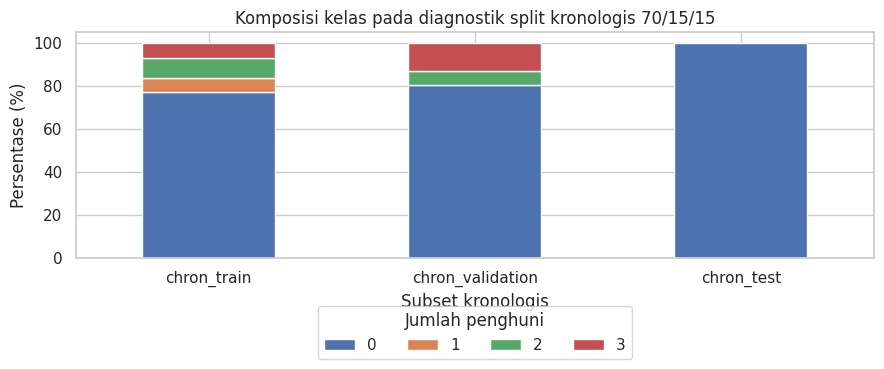

chron_train: kelas yang tidak muncul = []
chron_validation: kelas yang tidak muncul = [1]
chron_test: kelas yang tidak muncul = [1, 2, 3]
Catatan: bila kelas okupansi tertentu tidak muncul pada chron_test, metrik klasifikasi untuk kelas tersebut tidak dapat dihitung. Itulah alasan protokol utama menggunakan blok waktu stratified, dengan batasan bahwa protokol tersebut bukan simulasi masa depan.


In [8]:
# Diagnostik: distribusi kelas jika data dibagi murni secara kronologis 70/15/15
n_rows = len(df)
chron_train_end = int(n_rows * 0.70)
chron_val_end = int(n_rows * 0.85)
chron_parts = {
    "chron_train": df.iloc[:chron_train_end],
    "chron_validation": df.iloc[chron_train_end:chron_val_end],
    "chron_test": df.iloc[chron_val_end:]
}
chron_counts = pd.DataFrame({
    name: part[TARGET].value_counts().reindex([0, 1, 2, 3], fill_value=0)
    for name, part in chron_parts.items()
})
chron_pct = chron_counts.div(chron_counts.sum(axis=0), axis=1) * 100
print("Distribusi kelas pada split kronologis murni:")
display(chron_counts)
display(chron_pct.round(2))

fig, ax = plt.subplots(figsize=(9, 4))
chron_pct.T.plot(kind="bar", stacked=True, ax=ax)
ax.set_title("Komposisi kelas pada diagnostik split kronologis 70/15/15")
ax.set_xlabel("Subset kronologis")
ax.set_ylabel("Persentase (%)")
ax.legend(title="Jumlah penghuni", ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.18))
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

for name, part in chron_parts.items():
    absent = sorted(set([0, 1, 2, 3]) - set(part[TARGET].unique()))
    print(f"{name}: kelas yang tidak muncul = {absent}")

print(
    "Catatan: bila kelas okupansi tertentu tidak muncul pada chron_test, "
    "metrik klasifikasi untuk kelas tersebut tidak dapat dihitung. "
    "Itulah alasan protokol utama menggunakan blok waktu stratified, "
    "dengan batasan bahwa protokol tersebut bukan simulasi masa depan."
)

,jumlah,persentase
Room_Occupancy_Count,,
0,8228,81.23
1,459,4.53
2,748,7.38
3,694,6.85


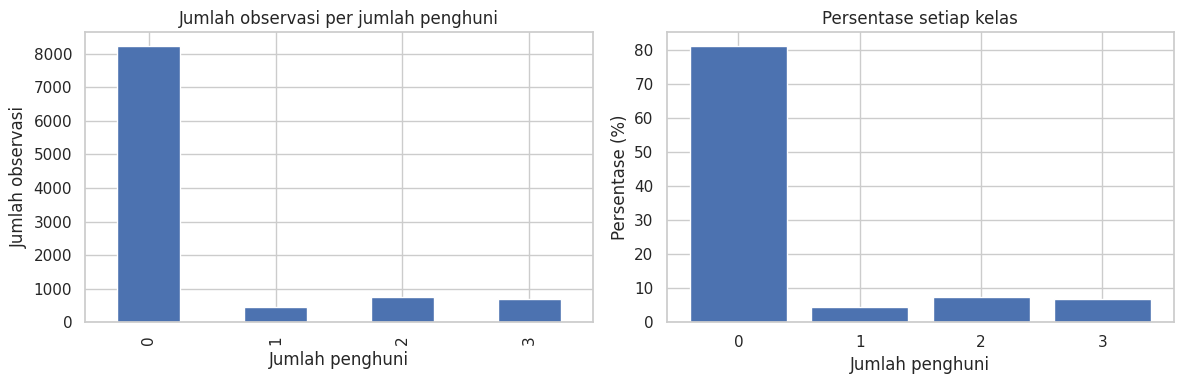

Kelas 0 mendominasi data: 81.23% dari seluruh pengamatan.


In [9]:
# 6. Distribusi jumlah penghuni

target_counts = df[TARGET].value_counts().sort_index()
target_share = (target_counts / len(df) * 100).round(2)

target_distribution = pd.DataFrame({
    "jumlah": target_counts,
    "persentase": target_share
})
display(target_distribution)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
target_counts.reindex([0, 1, 2, 3], fill_value=0).plot(kind="bar", ax=axes[0])
axes[0].set_title("Jumlah observasi per jumlah penghuni")
axes[0].set_xlabel("Jumlah penghuni")
axes[0].set_ylabel("Jumlah observasi")

axes[1].bar(target_share.index.astype(str), target_share.values)
axes[1].set_title("Persentase setiap kelas")
axes[1].set_xlabel("Jumlah penghuni")
axes[1].set_ylabel("Persentase (%)")
plt.tight_layout()
plt.show()

print(
    "Kelas 0 mendominasi data:",
    f"{target_share.get(0, 0):.2f}% dari seluruh pengamatan."
)

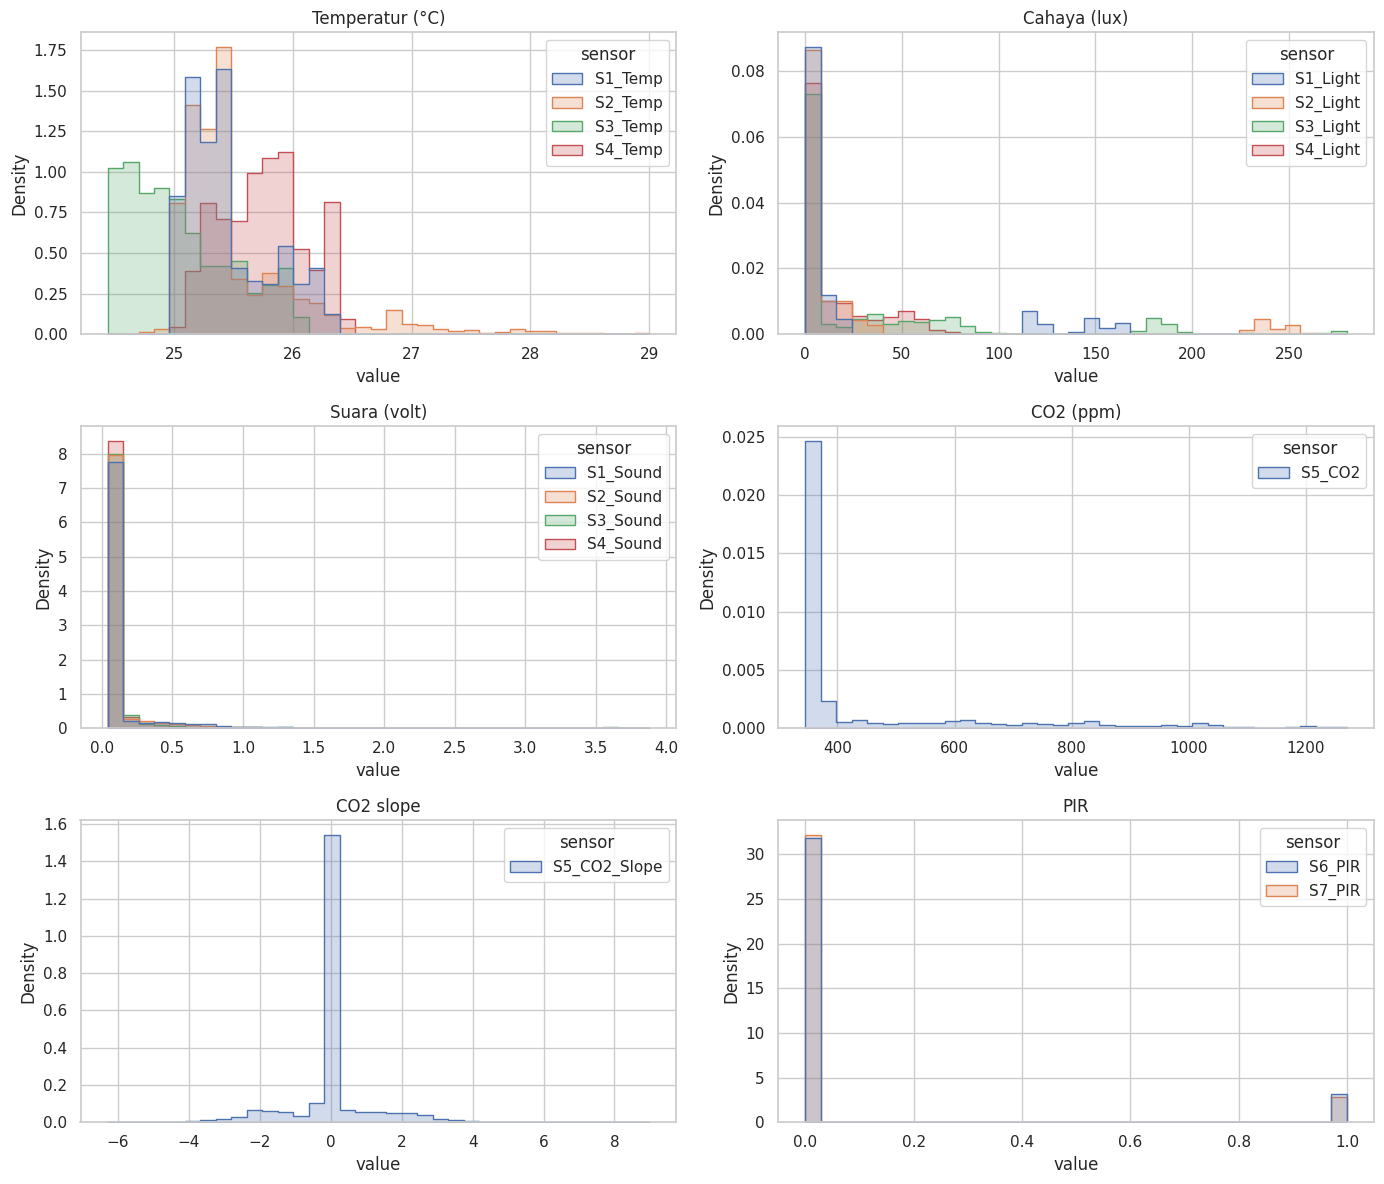

In [10]:
# 7. Melihat distribusi sensor

sensor_groups = {
    "Temperatur (°C)": [f"S{i}_Temp" for i in range(1, 5)],
    "Cahaya (lux)": [f"S{i}_Light" for i in range(1, 5)],
    "Suara (volt)": [f"S{i}_Sound" for i in range(1, 5)],
    "CO2 (ppm)": ["S5_CO2"],
    "CO2 slope": ["S5_CO2_Slope"],
    "PIR": ["S6_PIR", "S7_PIR"],
}

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
axes = axes.ravel()

for ax, (group_name, columns) in zip(axes, sensor_groups.items()):
    melted = df[columns].melt(var_name="sensor", value_name="value")
    sns.histplot(
        data=melted,
        x="value",
        hue="sensor",
        bins=35,
        element="step",
        stat="density",
        common_norm=False,
        ax=ax
    )
    ax.set_title(group_name)

plt.tight_layout()
plt.show()

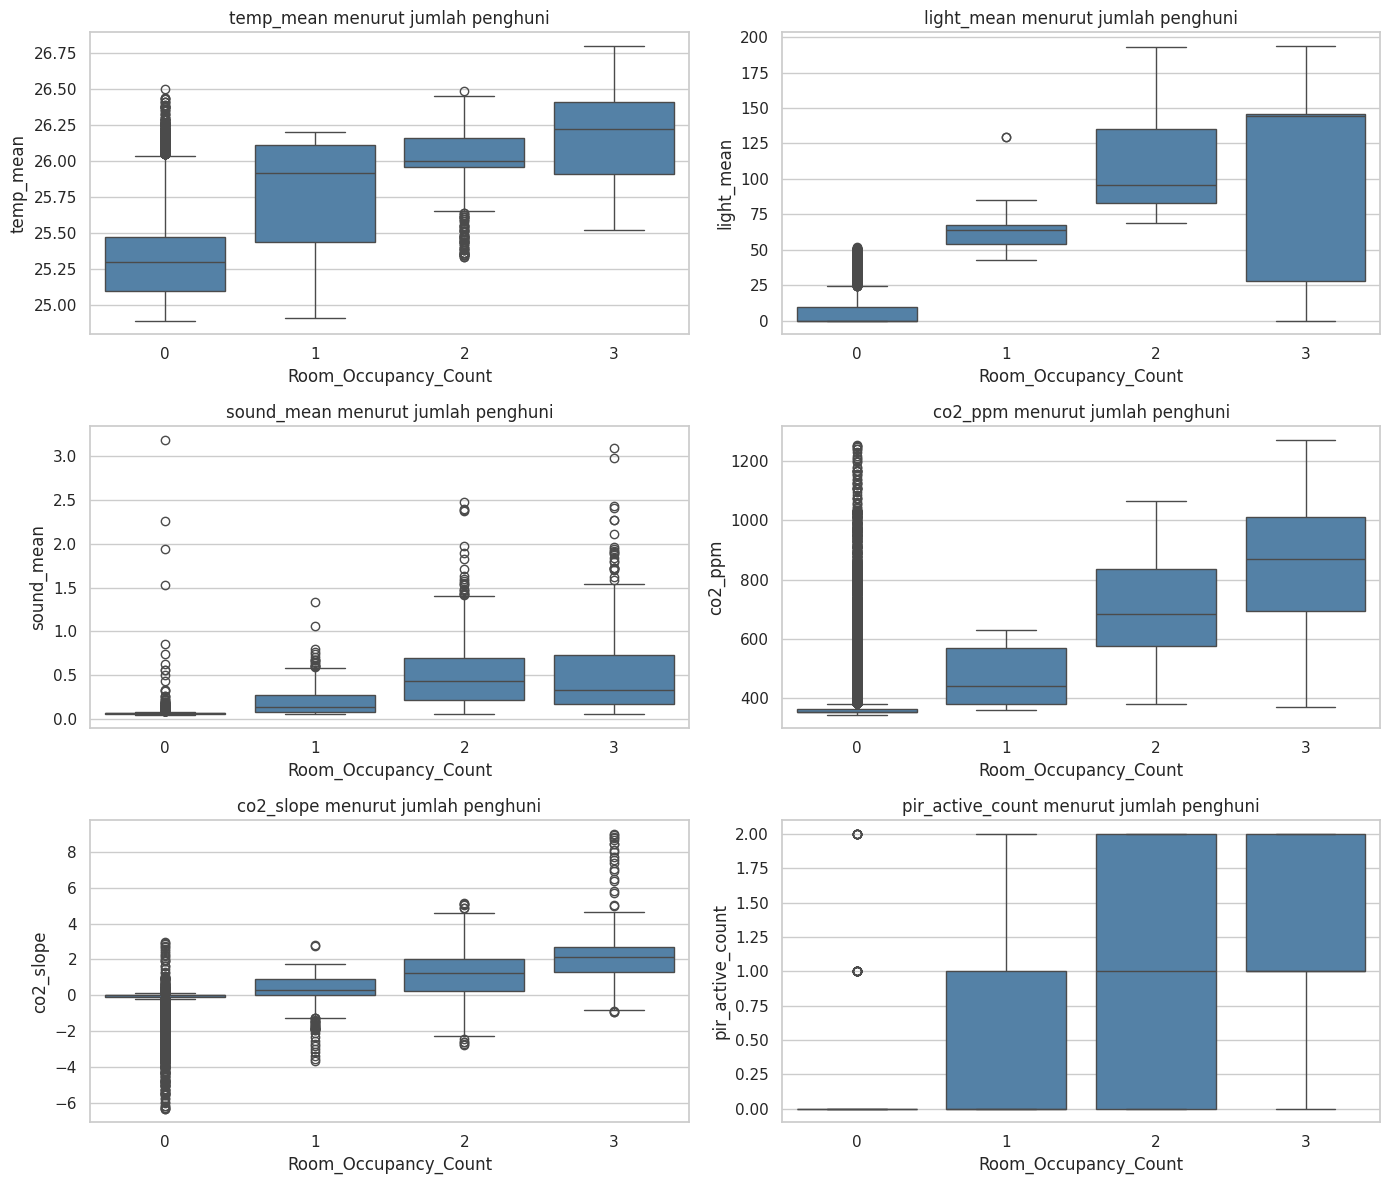

In [11]:
# 8. Membandingkan pembacaan sensor pada setiap jumlah penghuni

eda_features = pd.DataFrame(index=df.index)

for name, columns in [
    ("temp_mean", [f"S{i}_Temp" for i in range(1, 5)]),
    ("light_mean", [f"S{i}_Light" for i in range(1, 5)]),
    ("sound_mean", [f"S{i}_Sound" for i in range(1, 5)]),
]:
    eda_features[name] = df[columns].mean(axis=1)

eda_features["co2_ppm"] = df["S5_CO2"]
eda_features["co2_slope"] = df["S5_CO2_Slope"]
eda_features["pir_active_count"] = df[["S6_PIR", "S7_PIR"]].sum(axis=1)
eda_features[TARGET] = df[TARGET]

plot_features = list(eda_features.columns.drop(TARGET))
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
axes = axes.ravel()

for ax, feature in zip(axes, plot_features):
    sns.boxplot(data=eda_features, x=TARGET, y=feature, color="steelblue", ax=ax)
    ax.set_title(f"{feature} menurut jumlah penghuni")

plt.tight_layout()
plt.show()

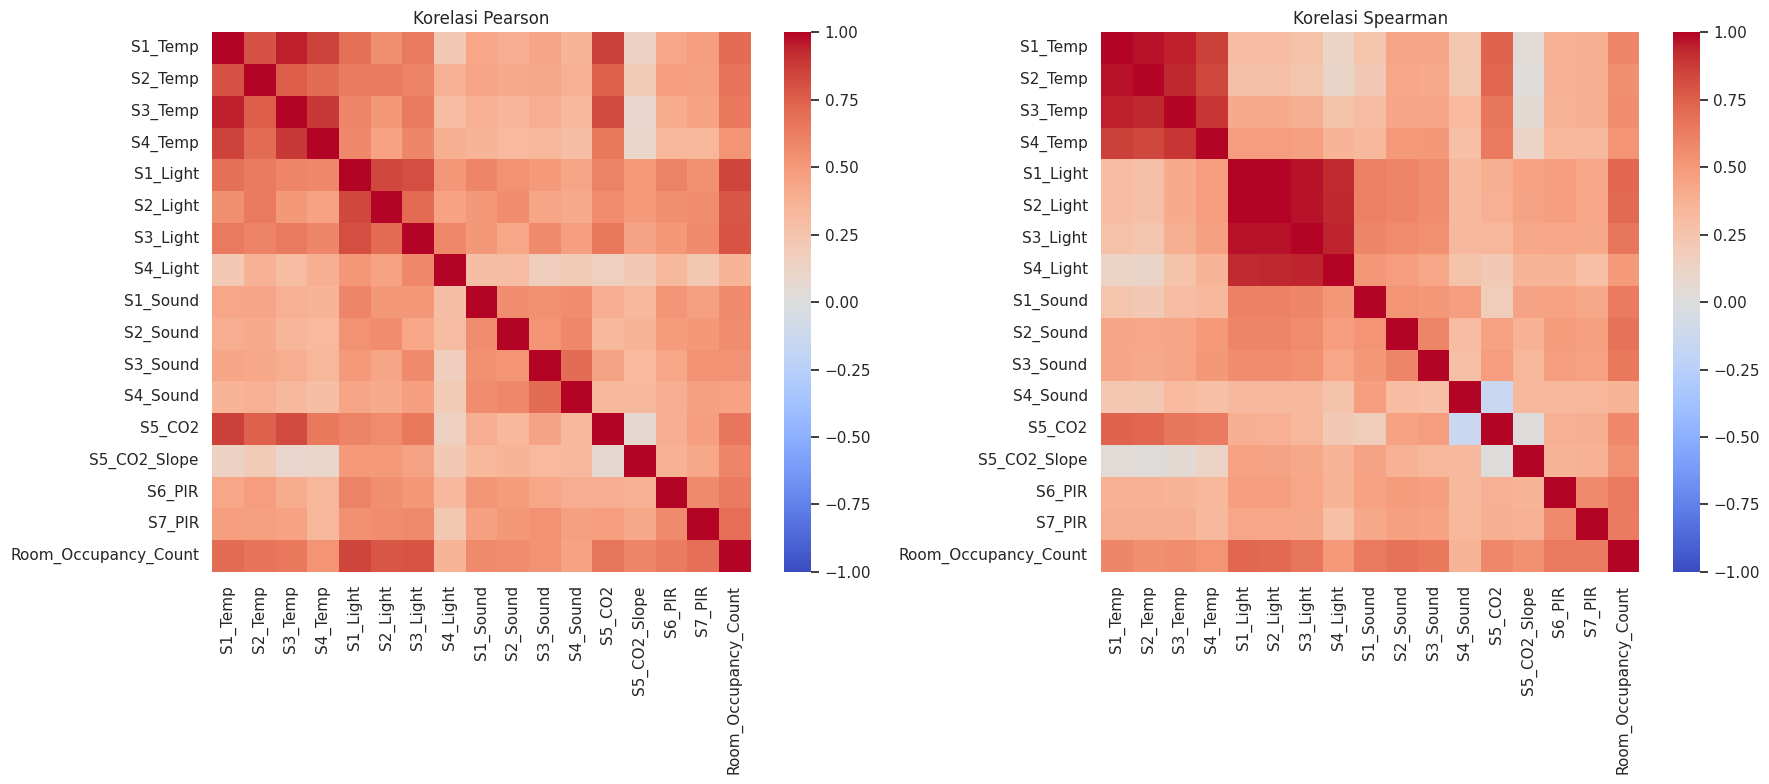

,Pearson,Spearman
S1_Light,0.849058,0.719052
S3_Light,0.793081,0.662057
S2_Light,0.788764,0.713250
S1_Temp,0.700868,0.588967
S7_PIR,0.695138,0.637666
S2_Temp,0.671263,0.547282
S5_CO2,0.660144,0.581023
S3_Temp,0.652047,0.558498
S6_PIR,0.633133,0.645555
S5_CO2_Slope,0.601105,0.543127


In [12]:
# 9. Korelasi Pearson dan Spearman

corr_columns = sensor_columns + [TARGET]
pearson_corr = df[corr_columns].corr(method="pearson")
spearman_corr = df[corr_columns].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

sns.heatmap(
    pearson_corr, cmap="coolwarm", vmin=-1, vmax=1, center=0, ax=axes[0]
)
axes[0].set_title("Korelasi Pearson")

sns.heatmap(
    spearman_corr, cmap="coolwarm", vmin=-1, vmax=1, center=0, ax=axes[1]
)
axes[1].set_title("Korelasi Spearman")

plt.tight_layout()
plt.show()

target_corr = pd.DataFrame({
    "Pearson": pearson_corr[TARGET].drop(TARGET),
    "Spearman": spearman_corr[TARGET].drop(TARGET)
})
target_corr["abs_Pearson"] = target_corr["Pearson"].abs()
display(target_corr.sort_values("abs_Pearson", ascending=False).drop(columns="abs_Pearson"))

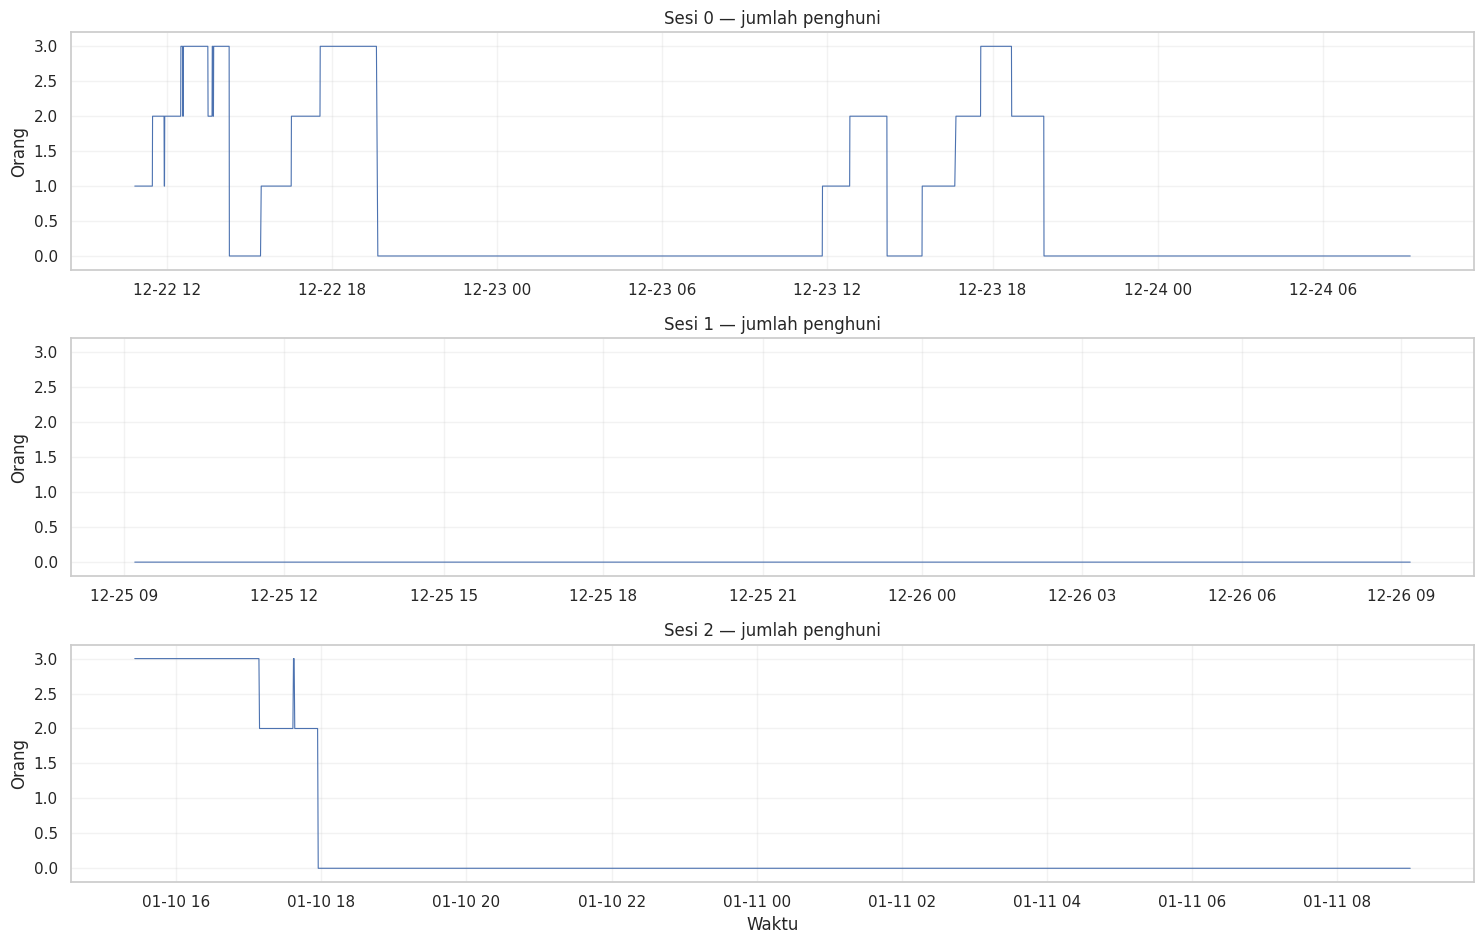

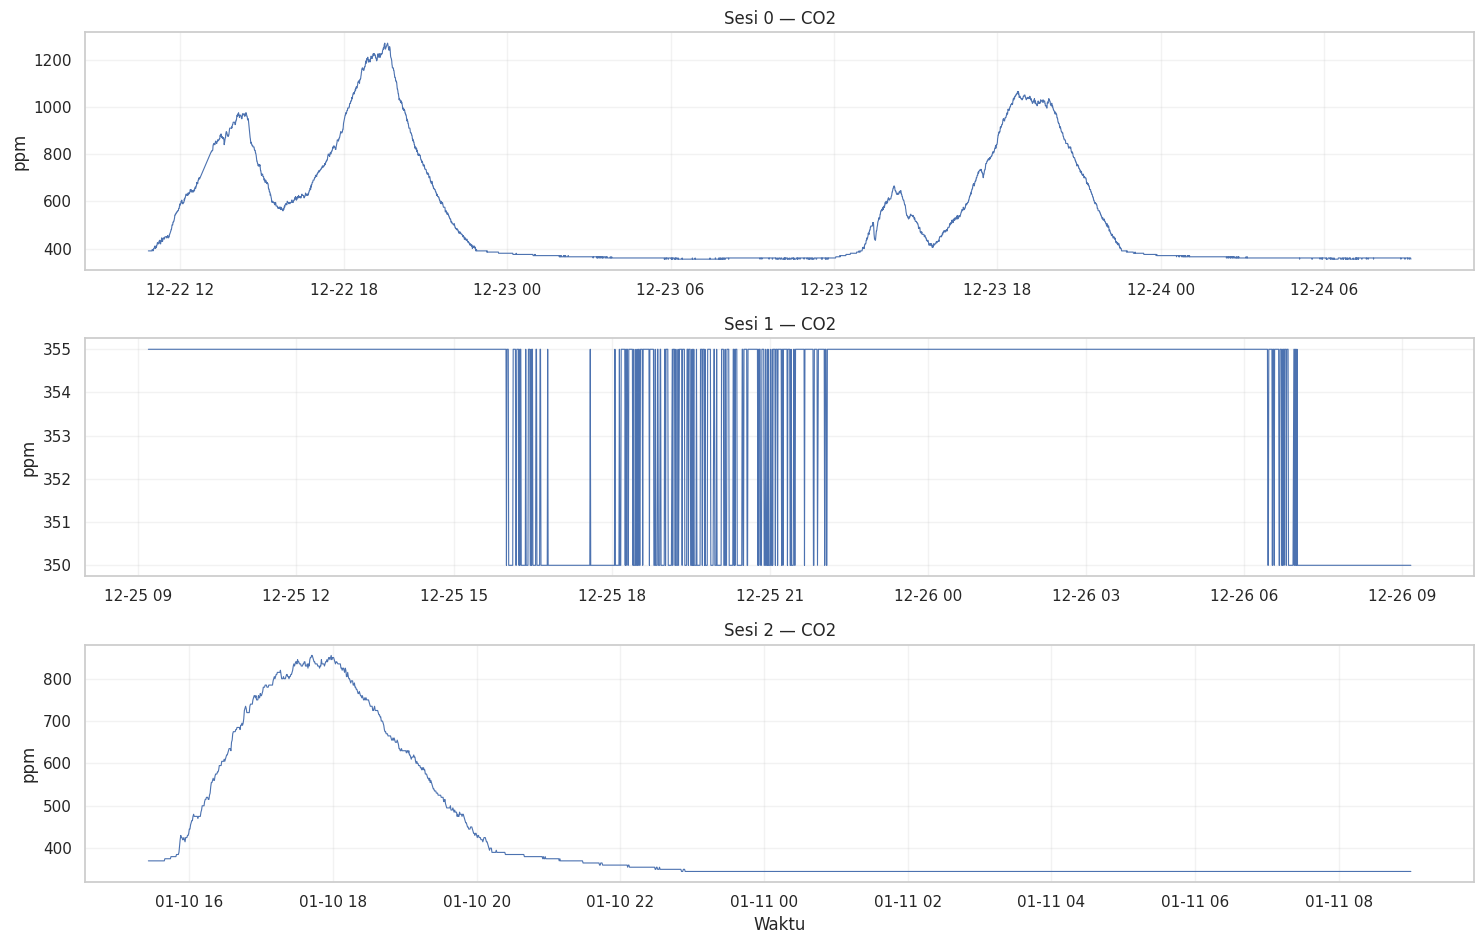

In [13]:
# 10. Pola okupansi dan CO2 per sesi

n_sessions = df["session_id"].nunique()
fig, axes = plt.subplots(
    n_sessions, 1,
    figsize=(15, max(4, 3.2 * n_sessions)),
    squeeze=False
)

for row, (session_id, part) in enumerate(df.groupby("session_id")):
    ax = axes[row, 0]
    ax.plot(part["timestamp"], part[TARGET], linewidth=0.8)
    ax.set_title(f"Sesi {session_id} — jumlah penghuni")
    ax.set_ylabel("Orang")
    ax.set_ylim(-0.2, 3.2)
    ax.grid(alpha=0.25)

plt.xlabel("Waktu")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(
    n_sessions, 1,
    figsize=(15, max(4, 3.2 * n_sessions)),
    squeeze=False
)

for row, (session_id, part) in enumerate(df.groupby("session_id")):
    ax = axes[row, 0]
    ax.plot(part["timestamp"], part["S5_CO2"], linewidth=0.8)
    ax.set_title(f"Sesi {session_id} — CO2")
    ax.set_ylabel("ppm")
    ax.grid(alpha=0.25)

plt.xlabel("Waktu")
plt.tight_layout()
plt.show()

In [ ]:
# 11. Melihat skewness, nilai nol, dan kandidat outlier

continuous_columns = [
    c for c in sensor_columns
    if c not in ["S6_PIR", "S7_PIR"]
]

distribution_summary = pd.DataFrame({
    "skewness": df[continuous_columns].skew(),
    "persen_nol": (df[continuous_columns] == 0).mean() * 100,
    "jumlah_nilai_unik": df[continuous_columns].nunique()
}).sort_values("skewness", key=lambda s: s.abs(), ascending=False)

display(distribution_summary.round(3))

# IQR adalah penanda awal untuk fitur kontinu, bukan alasan menghapus data.
outlier_rows = []
for col in continuous_columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    flagged = (df[col] < lower) | (df[col] > upper)

    outlier_rows.append({
        "fitur": col,
        "batas_bawah_IQR": lower,
        "batas_atas_IQR": upper,
        "jumlah_flag": int(flagged.sum()),
        "persentase_flag": float(flagged.mean() * 100)
    })

outlier_summary = pd.DataFrame(outlier_rows).sort_values(
    "persentase_flag", ascending=False
)
display(outlier_summary.round(3))

print(
    "PIR tidak dimasukkan ke pemeriksaan IQR karena bersifat biner; "
    "nilai 1 adalah sinyal gerakan yang bermakna."
)

,skewness,persen_nol,jumlah_nilai_unik
S4_Sound,10.952,0.000,106
S2_Sound,6.882,0.000,185
S3_Sound,5.995,0.000,258
S1_Sound,5.450,0.000,231
S2_Light,2.828,57.715,82
S2_Temp,2.356,0.000,69
S3_Light,2.100,55.198,177
S5_CO2,1.976,0.000,186
S1_Light,1.820,57.706,68
S4_Light,1.358,55.277,75


,fitur,batas_bawah_IQR,batas_atas_IQR,jumlah_flag,persentase_flag
13,S5_CO2_Slope,-0.115,0.069,4033,39.816
8,S1_Sound,0.055,0.095,1772,17.494
4,S1_Light,-18.000,30.000,1716,16.941
9,S2_Sound,0.035,0.075,1703,16.813
10,S3_Sound,0.045,0.085,1671,16.497
12,S5_CO2,190.000,630.000,1657,16.359
5,S2_Light,-21.000,35.000,1017,10.040
6,S3_Light,-75.000,125.000,950,9.379
1,S2_Temp,24.530,26.290,948,9.359
11,S4_Sound,-0.000,0.160,721,7.118


PIR tidak dimasukkan ke pemeriksaan IQR karena bersifat biner; nilai 1 adalah sinyal gerakan yang bermakna.


### Apa yang dipelajari dari EDA?

- Empat sensor S1–S4 mengukur jenis kondisi yang sama dari lokasi berbeda. Rata-rata merangkum tingkat umum, sedangkan simpangan baku merangkum perbedaan antar-lokasi.
- Cahaya, suara, dan CO₂ dapat memiliki distribusi miring serta nilai ekstrem. Itu tidak otomatis berarti datanya salah.
- Target okupansi tidak seimbang. Karena itu, selain error numerik, perlu melihat performa setiap kelas.
- Jeda waktu yang sangat panjang menandai sesi eksperimen berbeda. Grafik per sesi lebih jujur daripada menyambungkan seluruh tanggal menjadi satu garis.
- Pearson dan Spearman memiliki rentang -1 sampai +1. Warna hangat/dingin pada heatmap menunjukkan arah hubungan, bukan hubungan sebab-akibat.

Tahap berikutnya adalah mengubah pembacaan mentah menjadi fitur yang lebih ringkas, sambil tetap menyimpan informasi variasi antar-sensor.

## 4. Menyusun fitur dari beberapa titik sensor

Untuk tiap jenis sensor S1–S4, hitung:
- **Mean:** tingkat umum pengukuran di empat titik.
- **Standard deviation:** seberapa berbeda pembacaan antar-titik.

Kemudian tambahkan CO₂, CO₂ slope, dan jumlah PIR aktif.

Siapkan dua kandidat representasi:

1. **Compact:** cahaya, CO₂, dan PIR. Ini mewakili tiga mekanisme sensor yang berbeda dengan input ringkas.
2. **Extended:** menambahkan temperatur, suara, variasi antar-titik, dan CO₂ slope.

Keduanya akan dibandingkan pada validation set. Jadi tidak menganggap sejak awal bahwa fitur lebih banyak pasti lebih baik.

Fitur positif yang sangat miring ditransformasikan dengan `log1p`. Transformasi ini mengecilkan rentang nilai besar tanpa menghapus nilai nol. CO₂ slope tidak ditransformasi karena dapat bernilai negatif.

In [15]:
# 12. Feature engineering

X_all = pd.DataFrame(index=df.index)

for feature_name, columns in [
    ("temp", [f"S{i}_Temp" for i in range(1, 5)]),
    ("light", [f"S{i}_Light" for i in range(1, 5)]),
    ("sound", [f"S{i}_Sound" for i in range(1, 5)]),
]:
    X_all[f"{feature_name}_mean"] = df[columns].mean(axis=1)
    X_all[f"{feature_name}_std"] = df[columns].std(axis=1, ddof=0)

X_all["co2_ppm"] = df["S5_CO2"]
X_all["co2_slope"] = df["S5_CO2_Slope"]
X_all["pir_active_count"] = df[["S6_PIR", "S7_PIR"]].sum(axis=1)

# Transformasi log1p untuk fitur positif yang rentangnya lebar.
X_all["light_mean_log"] = np.log1p(X_all["light_mean"].clip(lower=0))
X_all["light_std_log"] = np.log1p(X_all["light_std"].clip(lower=0))
X_all["sound_mean_log"] = np.log1p(X_all["sound_mean"].clip(lower=0))
X_all["sound_std_log"] = np.log1p(X_all["sound_std"].clip(lower=0))
X_all["co2_log"] = np.log1p(X_all["co2_ppm"].clip(lower=0))

FEATURE_SETS = {
    "compact": [
        "light_mean_log", "co2_log", "pir_active_count"
    ],
    "extended": [
        "temp_mean", "temp_std",
        "light_mean_log", "light_std_log",
        "sound_mean_log", "sound_std_log",
        "co2_log", "co2_slope", "pir_active_count"
    ]
}

y = df[TARGET].astype(int).copy()
timestamps = df["timestamp"].copy()

print("Semua fitur hasil rekayasa:")
display(X_all.head())
print("\nKandidat fitur compact:", FEATURE_SETS["compact"])
print("Kandidat fitur extended:", FEATURE_SETS["extended"])

Semua fitur hasil rekayasa:


,temp_mean,temp_std,light_mean,light_std,sound_mean,sound_std,co2_ppm,co2_slope,pir_active_count,light_mean_log,light_std_log,sound_mean_log,sound_std_log,co2_log
0,24.9075,0.304087,62.00,34.749101,0.0975,0.054025,390,0.769231,0,4.143135,3.576525,0.093035,0.052617,5.968708
1,24.9225,0.327595,61.75,34.952647,0.2750,0.378186,390,0.646154,0,4.139159,3.582203,0.242946,0.320768,5.968708
2,24.9225,0.347158,62.00,34.749101,0.1700,0.151162,390,0.519231,0,4.143135,3.576525,0.157004,0.140772,5.968708
3,24.9375,0.329422,62.00,34.749101,0.1750,0.135739,390,0.388462,0,4.143135,3.576525,0.161268,0.127283,5.968708
4,24.9375,0.329422,62.25,34.686993,0.0900,0.051962,390,0.253846,0,4.147095,3.574786,0.086178,0.050657,5.968708



Kandidat fitur compact: ['light_mean_log', 'co2_log', 'pir_active_count']
Kandidat fitur extended: ['temp_mean', 'temp_std', 'light_mean_log', 'light_std_log', 'sound_mean_log', 'sound_std_log', 'co2_log', 'co2_slope', 'pir_active_count']


In [16]:
# 13. Ringkasan dua kandidat fitur

for set_name, columns in FEATURE_SETS.items():
    print(f"\n=== {set_name.upper()} ===")
    display(X_all[columns].describe().T)


=== COMPACT ===


,count,mean,std,min,25%,50%,75%,max
light_mean_log,10129.0,1.580339,1.909704,0.000000,0.000000,0.000000,3.449988,5.271717
co2_log,10129.0,6.068391,0.336322,5.846439,5.874931,5.888878,6.144186,7.147559
pir_active_count,10129.0,0.169711,0.493767,0.000000,0.000000,0.000000,0.000000,2.000000



=== EXTENDED ===


,count,mean,std,min,25%,50%,75%,max
temp_mean,10129.0,25.452704,0.399201,24.890000,25.127500,25.362500,25.612500,26.800000
temp_std,10129.0,0.289561,0.122942,0.065383,0.225097,0.290291,0.315079,1.428152
light_mean_log,10129.0,1.580339,1.909704,0.000000,0.000000,0.000000,3.449988,5.271717
light_std_log,10129.0,1.396565,1.692046,0.000000,0.000000,0.000000,2.993342,4.648250
sound_mean_log,10129.0,0.115220,0.149879,0.051168,0.060625,0.065319,0.072321,1.430909
sound_std_log,10129.0,0.055928,0.127564,0.000000,0.010838,0.015688,0.020257,0.963165
co2_log,10129.0,6.068391,0.336322,5.846439,5.874931,5.888878,6.144186,7.147559
co2_slope,10129.0,-0.004830,1.164990,-6.296154,-0.046154,0.000000,0.000000,8.980769
pir_active_count,10129.0,0.169711,0.493767,0.000000,0.000000,0.000000,0.000000,2.000000


### Mengapa transformasi log dipakai pada sebagian fitur?

`log1p(x)` mengubah rentang positif yang sangat lebar menjadi rentang yang lebih terkompresi, tetapi tetap terdefinisi ketika nilai awal nol. Transformasi ini bukan syarat fuzzy clustering dan bukan upaya membuat semua fitur normal; tujuannya mengurangi dominasi nilai sangat besar pada jarak.

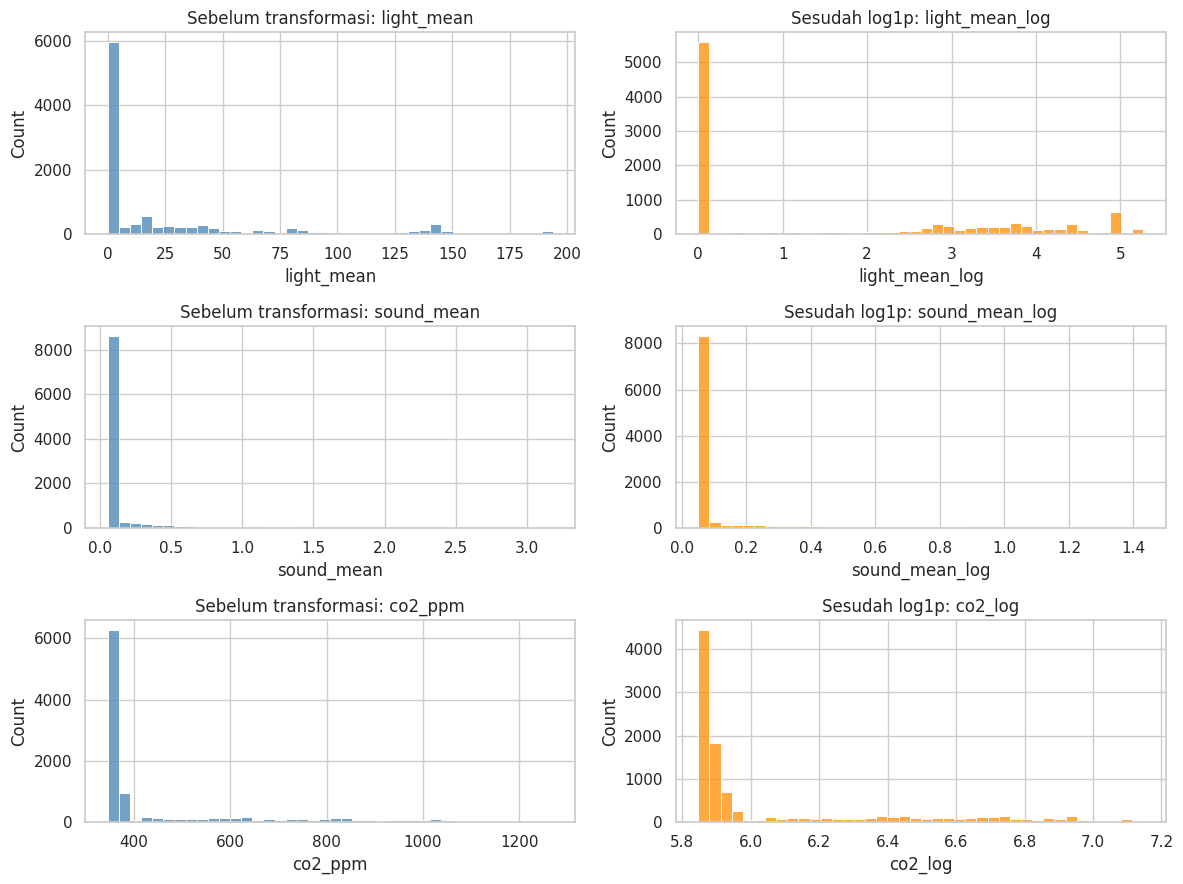

Contoh perhitungan fitur dari satu observasi:


,langkah,hasil
0,Rata-rata cahaya S1–S4,62.000000
1,log1p(rata-rata cahaya),4.143135
2,CO2 dari S5,390.000000
3,log1p(CO2),5.968708
4,Jumlah PIR aktif S6+S7,0.000000


In [17]:
# 13A. Membandingkan distribusi fitur sebelum dan sesudah log1p
transform_pairs = [
    ("light_mean", "light_mean_log"),
    ("sound_mean", "sound_mean_log"),
    ("co2_ppm", "co2_log")
]
fig, axes = plt.subplots(len(transform_pairs), 2, figsize=(12, 9))
for row, (raw_col, log_col) in enumerate(transform_pairs):
    sns.histplot(X_all[raw_col], bins=40, color="steelblue", ax=axes[row, 0])
    axes[row, 0].set_title(f"Sebelum transformasi: {raw_col}")
    sns.histplot(X_all[log_col], bins=40, color="darkorange", ax=axes[row, 1])
    axes[row, 1].set_title(f"Sesudah log1p: {log_col}")
plt.tight_layout()
plt.show()

# Contoh hitung fitur untuk satu baris agar proses agregasi tidak abstrak.
example_idx = 0
example_raw = df.iloc[example_idx]
example_calculation = pd.DataFrame({
    "langkah": [
        "Rata-rata cahaya S1–S4",
        "log1p(rata-rata cahaya)",
        "CO2 dari S5",
        "log1p(CO2)",
        "Jumlah PIR aktif S6+S7"
    ],
    "hasil": [
        np.mean([example_raw[f"S{i}_Light"] for i in range(1,5)]),
        np.log1p(np.mean([example_raw[f"S{i}_Light"] for i in range(1,5)])),
        example_raw["S5_CO2"],
        np.log1p(example_raw["S5_CO2"]),
        example_raw["S6_PIR"] + example_raw["S7_PIR"]
    ]
})
print("Contoh perhitungan fitur dari satu observasi:")
display(example_calculation)

## 5. Menyiapkan pembagian data: blocked stratified holdout

Karena tujuan penelitian adalah **mengestimasi okupansi pada saat pembacaan sensor**, bukan meramalkan masa depan, digunakan `StratifiedGroupKFold` dengan kelompok berupa blok waktu 20 menit di dalam setiap sesi operasional.

- Satu blok waktu utuh ditempatkan hanya pada satu subset.
- Satu fold menjadi test, satu fold menjadi validation, dan tiga fold sisanya menjadi train.
- Seed split dipilih dari sejumlah kandidat berdasarkan keterwakilan minimum setiap kelas dan kedekatan proporsi kelas setiap subset dengan distribusi keseluruhan. Pemilihan ini **tidak menggunakan skor model**.
- Setiap kelas harus memiliki minimal 10 observasi di setiap subset agar metrik per kelas tidak didasarkan pada dukungan yang terlalu kecil.
- Imputer dan scaler hanya dipelajari dari train.

**Batas interpretasi:** blok yang bersebelahan masih mungkin masuk ke subset berbeda. Karena itu, ketergantungan temporal antar-blok masih mungkin ada. Protokol ini bukan *future holdout*, bukan *leave-one-session-out*, dan bukan bukti generalisasi ke ruangan lain. Notebook menampilkan diagnostik blok bersebelahan agar batasan ini terlihat. Jika tujuan penelitian diubah menjadi forecasting, diperlukan split kronologis tersendiri.

In [18]:
# 14. Membentuk blok waktu dan split train/validation/test

def make_blocked_stratified_split(
    data, target, session_column="session_id",
    block_minutes=20, n_splits=5, random_state=42,
    max_seed_tries=100, min_class_count=10
):
    """
    Stratified group holdout pada blok waktu.
    Seed dipilih dari keterwakilan kelas dan kedekatan proporsi kelas
    terhadap distribusi keseluruhan; tidak menggunakan skor model.
    """
    data = data.reset_index(drop=True)
    target = pd.Series(target).reset_index(drop=True)

    elapsed_minutes = (
        data["timestamp"]
        - data.groupby(session_column)["timestamp"].transform("min")
    ).dt.total_seconds() / 60.0

    block_number = np.floor(elapsed_minutes / block_minutes).astype(int)
    groups = (
        data[session_column].astype(str)
        + "_block_"
        + block_number.astype(str)
    )

    classes = sorted(target.unique())
    global_distribution = (
        target.value_counts(normalize=True)
        .reindex(classes, fill_value=0)
        .to_numpy(dtype=float)
    )
    all_indices = np.arange(len(data))
    best_candidate = None

    for seed in range(random_state, random_state + max_seed_tries):
        splitter = StratifiedGroupKFold(
            n_splits=n_splits, shuffle=True, random_state=seed
        )
        folds = list(splitter.split(np.zeros((len(data), 1)), target, groups))

        test_idx = folds[0][1]
        val_idx = folds[1][1]
        train_idx = np.setdiff1d(
            all_indices, np.concatenate([test_idx, val_idx])
        )

        split_indices = {
            "train": train_idx,
            "validation": val_idx,
            "test": test_idx
        }

        # Syarat minimum dukungan kelas agar metrik per kelas tidak dibangun
        # dari hanya satu-dua observasi.
        count_ok = True
        for idx in split_indices.values():
            counts = (
                target.iloc[idx].value_counts()
                .reindex(classes, fill_value=0)
            )
            if (counts < min_class_count).any():
                count_ok = False
                break
        if not count_ok:
            continue

        # Total variation (L1) antara proporsi kelas setiap subset dan keseluruhan.
        distribution_errors = []
        for idx in split_indices.values():
            subset_distribution = (
                target.iloc[idx].value_counts(normalize=True)
                .reindex(classes, fill_value=0)
                .to_numpy(dtype=float)
            )
            distribution_errors.append(
                float(np.abs(subset_distribution - global_distribution).sum())
            )

        size_shares = np.array(
            [len(idx) / len(data) for idx in split_indices.values()],
            dtype=float
        )
        size_error = float(np.std(size_shares))
        balance_score = float(np.mean(distribution_errors) + 0.10 * size_error)

        if (
            best_candidate is None
            or balance_score < best_candidate["balance_score"]
        ):
            best_candidate = {
                "split_indices": split_indices,
                "seed": seed,
                "balance_score": balance_score,
                "distribution_errors": distribution_errors,
                "size_shares": size_shares
            }

    if best_candidate is None:
        raise RuntimeError(
            "Tidak ditemukan blocked split dengan minimal "
            f"{min_class_count} observasi per kelas pada setiap subset "
            f"dalam {max_seed_tries} seed. Jangan menurunkan syarat diam-diam; "
            "periksa jumlah blok kelas minoritas atau ubah durasi blok."
        )

    return (
        best_candidate["split_indices"],
        groups,
        best_candidate["seed"],
        best_candidate["balance_score"],
        best_candidate["distribution_errors"]
    )


(
    split_indices,
    time_blocks,
    split_seed,
    split_balance_score,
    split_distribution_errors
) = make_blocked_stratified_split(
    df, y, block_minutes=20, n_splits=5,
    random_state=RANDOM_STATE,
    max_seed_tries=100,
    min_class_count=10
)

train_idx = split_indices["train"]
val_idx = split_indices["validation"]
test_idx = split_indices["test"]

X_train_all = X_all.iloc[train_idx].copy()
X_val_all = X_all.iloc[val_idx].copy()
X_test_all = X_all.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_val = y.iloc[val_idx].copy()
y_test = y.iloc[test_idx].copy()

t_train = timestamps.iloc[train_idx].copy()
t_val = timestamps.iloc[val_idx].copy()
t_test = timestamps.iloc[test_idx].copy()

groups_by_split = {
    name: set(time_blocks.iloc[idx])
    for name, idx in split_indices.items()
}
assert groups_by_split["train"].isdisjoint(groups_by_split["validation"])
assert groups_by_split["train"].isdisjoint(groups_by_split["test"])
assert groups_by_split["validation"].isdisjoint(groups_by_split["test"])

print("Seed split terpilih:", split_seed)
print("Skor keseimbangan distribusi kelas (lebih kecil lebih baik):",
      round(split_balance_score, 6))
print("L1 deviation train/validation/test:",
      np.round(split_distribution_errors, 4))
print("Ukuran train/validation/test:",
      len(train_idx), len(val_idx), len(test_idx))
print("Jumlah blok waktu:", time_blocks.nunique())

Seed split terpilih: 137
Skor keseimbangan distribusi kelas (lebih kecil lebih baik): 0.044172
L1 deviation train/validation/test: [0.0191 0.0239 0.0339]
Ukuran train/validation/test: 6031 2054 2044
Jumlah blok waktu: 265


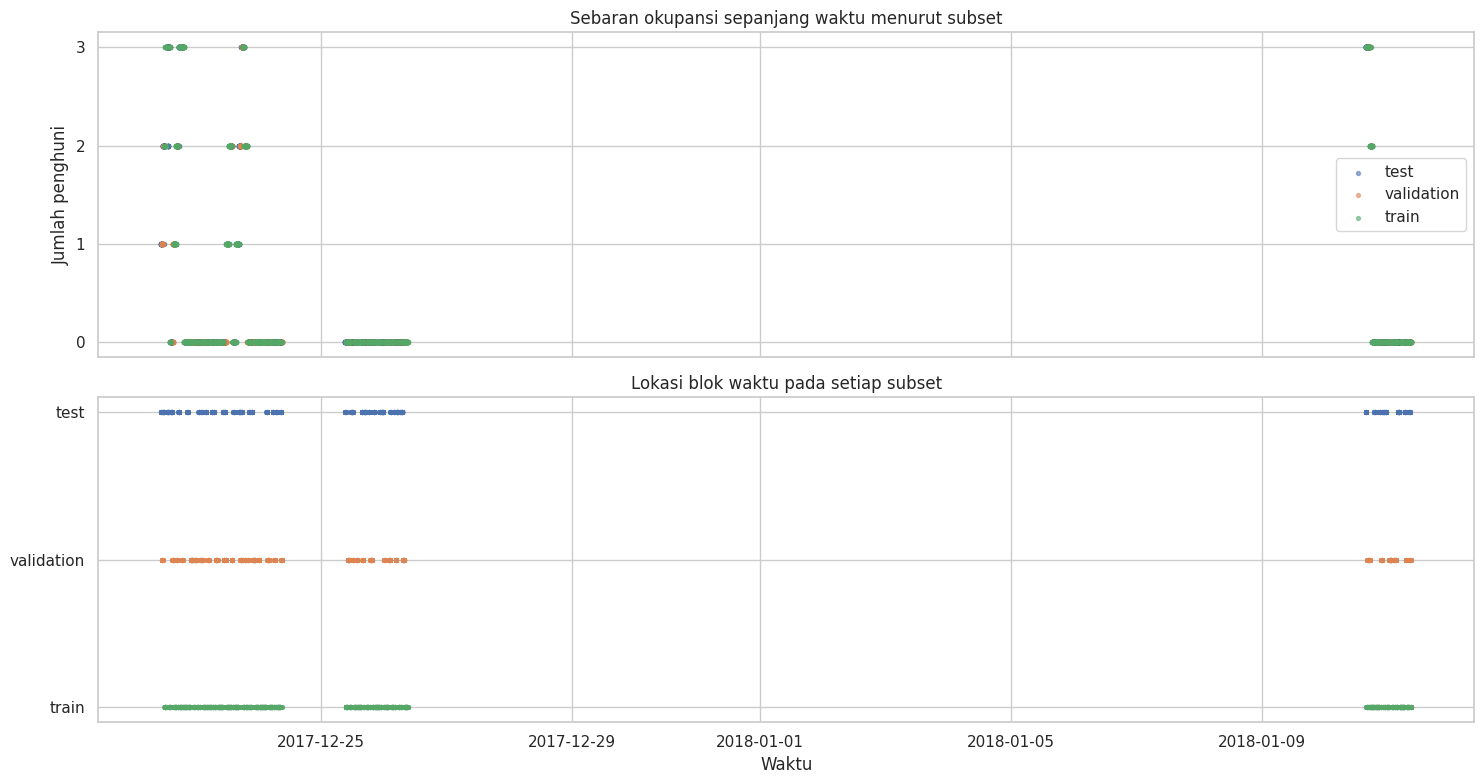

In [19]:
# 14A. Visualisasi pembagian blok waktu
split_labels = np.full(len(df), "unassigned", dtype=object)
split_labels[train_idx] = "train"
split_labels[val_idx] = "validation"
split_labels[test_idx] = "test"
split_plot_df = pd.DataFrame({
    "timestamp": df["timestamp"],
    "occupancy": y,
    "split": split_labels
}).sort_values("timestamp")

split_order = {"train": 0, "validation": 1, "test": 2}
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
for name, part in split_plot_df.groupby("split", sort=False):
    axes[0].scatter(
        part["timestamp"], part["occupancy"],
        s=8, alpha=0.55, label=name
    )
axes[0].set_title("Sebaran okupansi sepanjang waktu menurut subset")
axes[0].set_ylabel("Jumlah penghuni")
axes[0].set_yticks([0,1,2,3])
axes[0].legend()

for name, part in split_plot_df.groupby("split", sort=False):
    axes[1].scatter(
        part["timestamp"], np.full(len(part), split_order[name]),
        s=7, alpha=0.5, label=name
    )
axes[1].set_yticks([0,1,2])
axes[1].set_yticklabels(["train", "validation", "test"])
axes[1].set_title("Lokasi blok waktu pada setiap subset")
axes[1].set_xlabel("Waktu")
plt.tight_layout()
plt.show()

Pasangan blok 20-menit bersebelahan: 262
Pasangan lintas subset: 141
Proporsi pasangan lintas subset: 53.82%
Median jeda antar-pengamatan pada pasangan blok: 0.517 menit
Matriks jumlah transisi subset antar-blok bersebelahan:


split_right,train,validation,test
split_left,,,
train,98,24,34
validation,32,14,7
test,29,15,9


Matriks proporsi transisi per subset asal:


split_right,train,validation,test
split_left,,,
train,0.628,0.154,0.218
validation,0.604,0.264,0.132
test,0.547,0.283,0.170


Diagnostik per sesi:


,session_id,adjacent_pairs,cross_split_pairs,cross_split_rate,median_gap_minutes
0,0,139,73,0.5252,0.5167
1,1,71,38,0.5352,0.5167
2,2,52,30,0.5769,0.5167


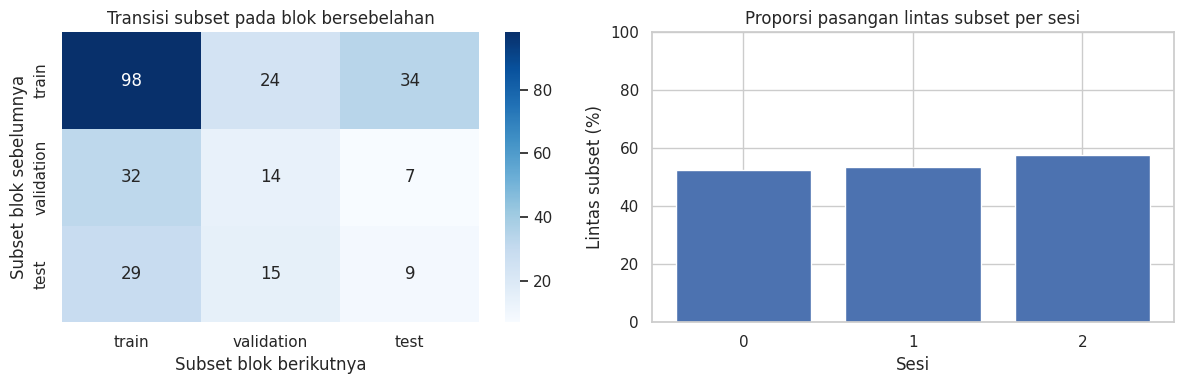

Interpretasi: setiap blok utuh hanya berada pada satu subset sehingga tidak ada overlap blok secara langsung. Namun, pasangan blok bersebelahan yang berbeda subset masih dapat berbagi pola temporal/autokorelasi. Ini adalah risiko ketergantungan temporal yang tersisa, bukan bukti otomatis bahwa terjadi kebocoran label. Hasil tetap disebut blocked internal holdout, bukan future holdout.


In [20]:
# 14B. Diagnostik kedekatan temporal blok antar-subset
# Blok tidak overlap, tetapi blok bersebelahan dapat memiliki autokorelasi.
elapsed_minutes = (
    df["timestamp"]
    - df.groupby("session_id")["timestamp"].transform("min")
).dt.total_seconds() / 60.0
block_number = np.floor(elapsed_minutes / 20).astype(int)

row_block_df = pd.DataFrame({
    "session_id": df["session_id"].to_numpy(),
    "block_number": block_number.to_numpy(),
    "timestamp": df["timestamp"].to_numpy(),
    "split": split_labels
})

block_diagnostic = (
    row_block_df.groupby(["session_id", "block_number"], as_index=False)
    .agg(
        block_start=("timestamp", "min"),
        block_end=("timestamp", "max"),
        split=("split", "first"),
        n_observations=("timestamp", "size")
    )
)

adjacent_records = []
for session_id, part in block_diagnostic.groupby("session_id"):
    part = part.sort_values("block_number").reset_index(drop=True)
    for left, right in zip(part.iloc[:-1].to_dict("records"), part.iloc[1:].to_dict("records")):
        if right["block_number"] - left["block_number"] == 1:
            gap_minutes = (right["block_start"] - left["block_end"]).total_seconds() / 60.0
            adjacent_records.append({
                "session_id": session_id,
                "block_left": left["block_number"],
                "split_left": left["split"],
                "block_right": right["block_number"],
                "split_right": right["split"],
                "cross_split": left["split"] != right["split"],
                "gap_minutes_between_observations": gap_minutes
            })

adjacent_block_df = pd.DataFrame(adjacent_records)
if len(adjacent_block_df):
    cross_count = int(adjacent_block_df["cross_split"].sum())
    cross_rate = float(adjacent_block_df["cross_split"].mean())
    print("Pasangan blok 20-menit bersebelahan:", len(adjacent_block_df))
    print("Pasangan lintas subset:", cross_count)
    print("Proporsi pasangan lintas subset:", f"{cross_rate:.2%}")
    print("Median jeda antar-pengamatan pada pasangan blok:",
          round(float(adjacent_block_df["gap_minutes_between_observations"].median()), 3), "menit")

    split_order = ["train", "validation", "test"]
    transition_counts = pd.crosstab(
        adjacent_block_df["split_left"], adjacent_block_df["split_right"]
    ).reindex(index=split_order, columns=split_order, fill_value=0)
    transition_rates = transition_counts.div(
        transition_counts.sum(axis=1).replace(0, np.nan), axis=0
    )
    print("Matriks jumlah transisi subset antar-blok bersebelahan:")
    display(transition_counts)
    print("Matriks proporsi transisi per subset asal:")
    display(transition_rates.round(3))

    per_session_adjacency = (
        adjacent_block_df.groupby("session_id")
        .agg(
            adjacent_pairs=("cross_split", "size"),
            cross_split_pairs=("cross_split", "sum"),
            cross_split_rate=("cross_split", "mean"),
            median_gap_minutes=("gap_minutes_between_observations", "median")
        )
        .reset_index()
    )
    print("Diagnostik per sesi:")
    display(per_session_adjacency.round(4))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.heatmap(transition_counts, annot=True, fmt="d", cmap="Blues", ax=axes[0])
    axes[0].set_title("Transisi subset pada blok bersebelahan")
    axes[0].set_xlabel("Subset blok berikutnya")
    axes[0].set_ylabel("Subset blok sebelumnya")
    axes[1].bar(
        per_session_adjacency["session_id"].astype(str),
        per_session_adjacency["cross_split_rate"] * 100
    )
    axes[1].set_title("Proporsi pasangan lintas subset per sesi")
    axes[1].set_xlabel("Sesi")
    axes[1].set_ylabel("Lintas subset (%)")
    axes[1].set_ylim(0, 100)
    plt.tight_layout()
    plt.show()
else:
    transition_counts = pd.DataFrame()
    per_session_adjacency = pd.DataFrame()
    print("Tidak ditemukan pasangan blok bersebelahan dalam sesi yang sama.")

print(
    "Interpretasi: setiap blok utuh hanya berada pada satu subset sehingga tidak ada "
    "overlap blok secara langsung. Namun, pasangan blok bersebelahan yang berbeda "
    "subset masih dapat berbagi pola temporal/autokorelasi. Ini adalah risiko "
    "ketergantungan temporal yang tersisa, bukan bukti otomatis bahwa terjadi "
    "kebocoran label. Hasil tetap disebut blocked internal holdout, bukan future holdout."
)

### Cara membaca diagnostik temporal

Proporsi pasangan blok bersebelahan lintas subset **bukan** persentase baris yang bocor. Setiap blok 20 menit tetap utuh dan hanya masuk satu subset. Angka tersebut menunjukkan seberapa sering dua blok yang berurutan secara waktu ditempatkan pada subset berbeda. Jika nilainya tinggi, pola sensor pada blok train dan test mungkin masih berkorelasi karena kedekatan waktu.

Karena itu, hasil utama harus disebut *blocked internal holdout*. Ia lebih ketat daripada random split per baris, tetapi belum setara dengan pengujian pada periode masa depan yang benar-benar terpisah. Untuk klaim forecasting atau generalisasi lintas sesi, diperlukan protokol evaluasi tambahan yang sesuai dan dukungan kelas yang memadai.

Jumlah observasi per kelas:


,train,validation,test
Room_Occupancy_Count,,,
0,4913,1653,1662
1,317,84,58
2,421,161,166
3,380,156,158


Persentase kelas per subset:


,train,validation,test
Room_Occupancy_Count,,,
0,81.46,80.48,81.31
1,5.26,4.09,2.84
2,6.98,7.84,8.12
3,6.30,7.59,7.73


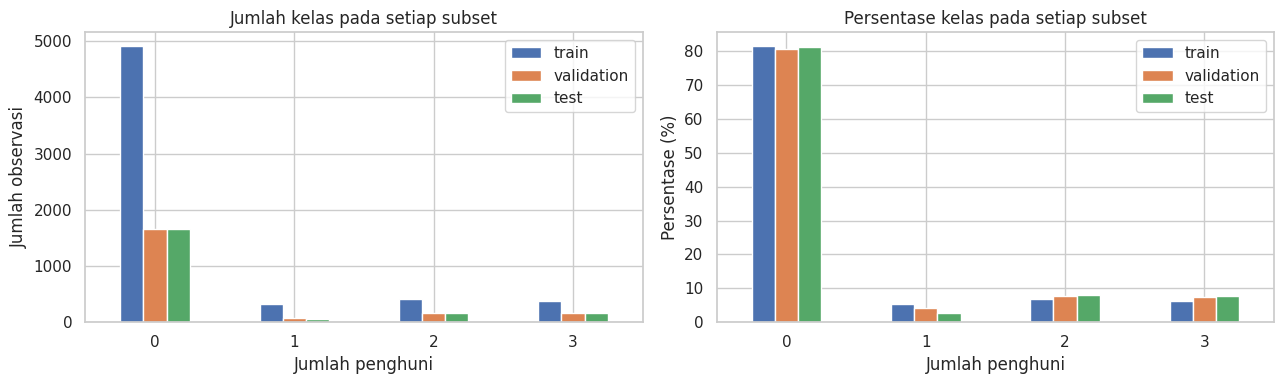

Kelas train: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
Kelas validation: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
Kelas test: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


In [21]:
# 15. Melihat komposisi kelas pada setiap subset

split_counts = pd.DataFrame({
    "train": y_train.value_counts().reindex([0, 1, 2, 3], fill_value=0),
    "validation": y_val.value_counts().reindex([0, 1, 2, 3], fill_value=0),
    "test": y_test.value_counts().reindex([0, 1, 2, 3], fill_value=0),
})

split_percent = split_counts.div(split_counts.sum(axis=0), axis=1) * 100

print("Jumlah observasi per kelas:")
display(split_counts)

print("Persentase kelas per subset:")
display(split_percent.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
split_counts.plot(kind="bar", ax=axes[0])
axes[0].set_title("Jumlah kelas pada setiap subset")
axes[0].set_xlabel("Jumlah penghuni")
axes[0].set_ylabel("Jumlah observasi")
axes[0].tick_params(axis="x", rotation=0)

split_percent.plot(kind="bar", ax=axes[1])
axes[1].set_title("Persentase kelas pada setiap subset")
axes[1].set_xlabel("Jumlah penghuni")
axes[1].set_ylabel("Persentase (%)")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

print("Kelas train:", sorted(y_train.unique()))
print("Kelas validation:", sorted(y_val.unique()))
print("Kelas test:", sorted(y_test.unique()))

## 6. Menyiapkan skala fitur dan menangani ketidakseimbangan target

Fitur sensor memiliki satuan dan rentang yang berbeda. Perlu menggunakan `RobustScaler` karena median dan IQR lebih tahan terhadap nilai ekstrem dibanding mean dan standard deviation.

Scaler dan imputasi di-*fit* hanya pada train. Validation dan test hanya ditransformasikan menggunakan parameter yang dipelajari dari train.

Untuk target yang tidak seimbang, tidak dilakukan perubahan komposisi validation dan test. Saat model dilatih, bandingkan dua pilihan:
- **Tanpa bobot:** setiap observasi mendapat bobot yang sama.
- **sqrt-balanced:** kelas yang jarang mendapat bobot lebih besar, tetapi menggunakan akar inverse frequency agar bobotnya tidak terlalu ekstrem.

Dengan begitu, bisa dilihat apakah pembobotan membantu kelas 1–3 tanpa membuat evaluasi test menjadi artifisial.

In [22]:
# 16. Fungsi bobot sampel dan preprocessing kandidat fitur

def make_sample_weights(y_values, mode="none"):
    y_values = np.asarray(y_values, dtype=int)

    if mode == "none":
        return np.ones(len(y_values), dtype=float)
    if mode != "sqrt_balanced":
        raise ValueError("mode harus 'none' atau 'sqrt_balanced'.")

    classes, counts = np.unique(y_values, return_counts=True)
    raw_weights = {
        cls: np.sqrt(len(y_values) / (len(classes) * count))
        for cls, count in zip(classes, counts)
    }
    weights = np.array([raw_weights[value] for value in y_values], dtype=float)
    return weights / weights.mean()

y_scaler_search = StandardScaler()
y_train_scaled = y_scaler_search.fit_transform(
    y_train.to_numpy().reshape(-1, 1)
).ravel()

prepared = {}

for set_name, columns in FEATURE_SETS.items():
    imputer = SimpleImputer(strategy="median")
    Xtr_imp = imputer.fit_transform(X_train_all[columns])
    Xva_imp = imputer.transform(X_val_all[columns])

    scaler = RobustScaler()
    Xtr_scaled = scaler.fit_transform(Xtr_imp)
    Xva_scaled = scaler.transform(Xva_imp)

    prepared[set_name] = {
        "columns": columns,
        "imputer": imputer,
        "scaler": scaler,
        "X_train": Xtr_scaled,
        "X_val": Xva_scaled
    }

    print(set_name, "| train:", Xtr_scaled.shape, "| validation:", Xva_scaled.shape)

print("\nDistribusi target training:")
display(y_train.value_counts().sort_index().to_frame("jumlah"))
print("\nBobot sqrt-balanced per kelas:")
weight_preview = make_sample_weights(y_train, "sqrt_balanced")
display(pd.DataFrame({
    "kelas": sorted(y_train.unique()),
    "bobot": [
        weight_preview[np.where(y_train.to_numpy() == cls)[0][0]]
        for cls in sorted(y_train.unique())
    ]
}))

compact | train: (6031, 3) | validation: (2054, 3)
extended | train: (6031, 9) | validation: (2054, 9)

Distribusi target training:


,jumlah
Room_Occupancy_Count,
0,4913
1,317
2,421
3,380



Bobot sqrt-balanced per kelas:


,kelas,bobot
0,0,0.672689
1,1,2.648244
2,2,2.297982
3,3,2.418777


### Apa yang berubah setelah scaling?

Scaling mengubah skala numerik agar jarak tidak didominasi fitur yang satuannya besar. Ia tidak mengubah urutan nilai dalam satu fitur. Plot berikut membandingkan rentang fitur terpilih sebelum dan sesudah RobustScaler.

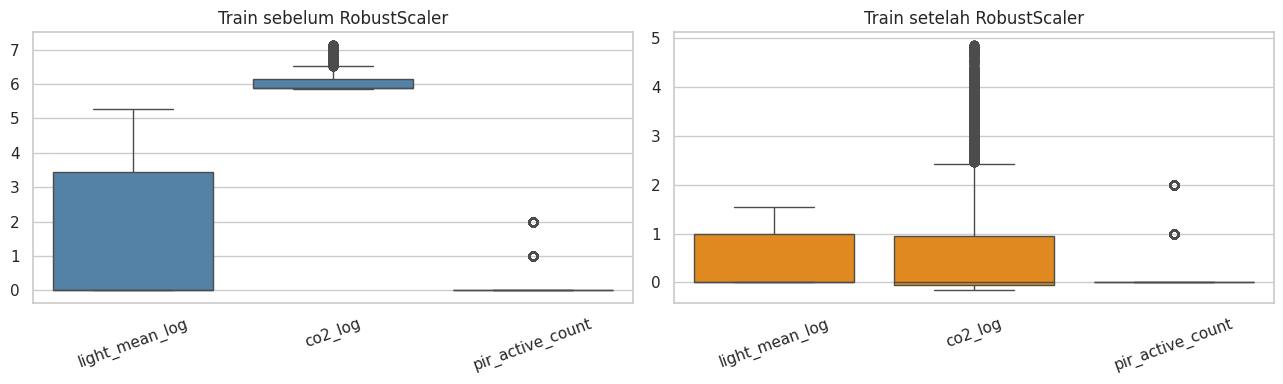

In [23]:
# 16A. Visualisasi efek RobustScaler pada fitur compact
compact_cols = FEATURE_SETS["compact"]
compact_scaled_df = pd.DataFrame(
    prepared["compact"]["X_train"], columns=compact_cols
)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=X_train_all[compact_cols], color="steelblue", ax=axes[0])
axes[0].set_title("Train sebelum RobustScaler")
axes[0].tick_params(axis="x", rotation=20)
sns.boxplot(data=compact_scaled_df, color="darkorange", ax=axes[1])
axes[1].set_title("Train setelah RobustScaler")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## 7. Landasan teori: fuzzy clustering dan First-Order Sugeno

### 7.1 Komponen fuzzy system pada penelitian

| Komponen | Implementasi |
|---|---|
| Variabel input | Fitur sensor hasil feature engineering |
| Variabel output | Jumlah penghuni ruangan, 0–3 orang |
| Fuzzy partition | FCM atau GK pada ruang gabungan input–output saat training |
| Antecedent | Region fuzzy multivariat yang dibentuk dari pusat dan kovarians cluster yang diproyeksikan ke ruang input |
| Membership function antecedent | Gaussian/ellipsoidal exponential membership |
| Consequent | Fungsi linear First-Order Sugeno pada setiap aturan |
| Inferensi | Firing strength dinormalisasi, kemudian local outputs digabung dengan weighted average |
| Output crisp | Estimasi kontinu, dibatasi ke rentang fisik 0–3, lalu dikuantisasi ke jumlah orang terdekat |

### 7.2 Fuzzy C-Means (FCM)

FCM mencari partisi fuzzy dengan meminimalkan:

\[
J_m(U,V)=\sum_{i=1}^{C}\sum_{k=1}^{N}u_{ik}^{m}\lVert z_k-v_i\rVert^2
\]

Dengan kendala partisi:

\[
0\leq u_{ik}\leq 1,\qquad \sum_{i=1}^{C}u_{ik}=1
\]

Pusat cluster diperbarui dengan:

\[
v_i=\frac{\sum_{k=1}^{N}u_{ik}^{m}z_k}{\sum_{k=1}^{N}u_{ik}^{m}}
\]

Untuk jarak tidak nol, membership diperbarui dengan:

\[
u_{ik}=\left[\sum_{j=1}^{C}\left(\frac{d_{ik}}{d_{jk}}\right)^{\frac{2}{m-1}}\right]^{-1}
\]

FCM menggunakan jarak Euclidean. Karena itu, geometri partisinya cenderung lebih sesuai untuk cluster yang relatif sferis. Kriteria berhenti yang dipakai dalam kode adalah perubahan maksimum membership yang lebih kecil dari toleransi:

\[
\Delta_U=\max_{i,k}|u_{ik}^{(t+1)}-u_{ik}^{(t)}|<\varepsilon.
\]

### 7.3 Gustafson–Kessel (GK)

GK mengganti jarak Euclidean dengan jarak kuadratik yang adaptif terhadap cluster:

\[
d_{ik,A_i}^{2}=(z_k-v_i)^T A_i(z_k-v_i)
\]

Kovarians fuzzy cluster:

\[
F_i=\frac{\sum_{k=1}^{N}u_{ik}^{m}(z_k-v_i)(z_k-v_i)^T}{\sum_{k=1}^{N}u_{ik}^{m}}
\]

Fungsi objektif GK menggunakan jarak adaptif:

\[
J_m(U,V,A)=\sum_{i=1}^{C}\sum_{k=1}^{N}u_{ik}^{m}(z_k-v_i)^TA_i(z_k-v_i).
\]

Dengan kendala volume \(|A_i|=\rho_i\), matriks metrik GK:

\[
A_i=[\rho_i\det(F_i)]^{1/p}F_i^{-1}.
\]

Implementasi menggunakan \(\rho_i=1\). Eigenvector kovarians menunjukkan orientasi cluster, sedangkan akar eigenvalue menunjukkan panjang semi-sumbu ellipsoid. Regularisasi eigenvalue diterapkan agar invers kovarians stabil; regularisasi ini adalah pengaman numerik, bukan bukti bahwa data mengikuti distribusi normal.

### 7.4 Identifikasi aturan pada ruang input–output

Untuk setiap pasangan training \((x_k,y_k)\), clustering dilakukan pada:

\[
z_k=[x_k^T,\ y_k]^T
\]

Target digunakan hanya saat identifikasi model pada training. Setelah cluster diperoleh, pusat dan blok kovarians yang berkaitan dengan input diproyeksikan ke ruang input. Saat inferensi, firing strength dihitung dari input sensor saja karena target belum diketahui.

Pendekatan product-space clustering untuk membentuk aturan TSK dan penggunaan region fuzzy multivariat dijelaskan oleh Gómez-Skarmeta, Delgado, dan Vila (1999). Paper tersebut juga membahas pembentukan consequent fungsional dan estimasi parameternya dengan least squares.

### 7.5 Membership antecedent dan inferensi Sugeno

Untuk aturan ke-i, membership antecedent Gaussian ellipsoidal dihitung sebagai:

\[
\mu_i(x)=\exp\left[-\frac{1}{2}(x-c_i)^T\Sigma_i^{-1}(x-c_i)\right]
\]

Pada tahap pembentukan cluster, FCM memakai jarak Euclidean dan GK memakai metrik kovarians adaptif pada ruang gabungan input–output. Untuk membuat aturan dapat dipakai saat target belum diketahui, blok kovarians input dari cluster dipakai untuk membentuk MF antecedent ellipsoidal di ruang input. Ini adalah tahap proyeksi/identifikasi antecedent yang dinyatakan eksplisit; ia bukan klaim bahwa membership product-space dipakai langsung saat prediksi. Fungsi ini adalah **membership function peak-normalized**, bukan probability density Gaussian: faktor normalisasi determinan kovarians tidak disertakan karena yang dibutuhkan adalah derajat kecocokan relatif terhadap pusat aturan, bukan kepadatan probabilitas. Karena itu, membership tidak boleh ditafsirkan sebagai probabilitas.

Firing strength ternormalisasi:

\[
\bar{\alpha}_i(x)=\frac{\mu_i(x)}{\sum_{j=1}^{C}\mu_j(x)}
\]

Aturan First-Order Sugeno:

\[
R_i:\quad \text{IF }x\text{ berada pada region fuzzy }A_i\quad
\text{THEN }f_i(x)=b_i+\sum_{j=1}^{p}a_{ij}x_j
\]

Output model:

\[
\hat y(x)=\sum_{i=1}^{C}\bar{\alpha}_i(x)f_i(x)
\]

Pada Sugeno, agregasi consequent linear dengan firing strength ternormalisasi menghasilkan output crisp secara langsung. Karena itu, proses ini tidak menggunakan centroid defuzzification seperti yang umum dijelaskan pada Mamdani.

### 7.6 Estimasi parameter consequent

Setiap consequent diestimasi dengan Weighted Ridge Least Squares. Untuk aturan ke-i, parameter diperoleh dengan meminimalkan:

\[
\min_{\theta_i}
\left\|W_i^{1/2}(\Phi\theta_i-y)\right\|_2^2
+\lambda\left\|R^{1/2}\theta_i\right\|_2^2
\]

Dengan \(\Phi=[x_1,\ldots,x_p,1]\), bobot diagonal \(W_i\) berasal dari membership antecedent training yang dipangkatkan \(m\), dan \(R\) tidak memberi penalti pada intercept. Bentuk persamaan normal secara matematis adalah:

\[
\theta_i=(\Phi^T W_i\Phi+\lambda R)^{-1}\Phi^T W_i y.
\]

Namun, kode **tidak** menyelesaikan persamaan normal secara langsung. Untuk stabilitas numerik, kode membentuk sistem augmented:

\[
\begin{bmatrix}
W_i^{1/2}\Phi\\
\sqrt{\lambda}R^{1/2}
\end{bmatrix}\theta_i
\approx
\begin{bmatrix}
W_i^{1/2}y\\
0
\end{bmatrix}
\]

dan menyelesaikannya dengan `numpy.linalg.lstsq`. Cara ini menghindari pembentukan normal matrix sebagai sistem yang harus diinvers/dipecahkan langsung. Condition number normal matrix tetap dicatat sebagai diagnostik, bukan sebagai solver.

**Penting untuk konsistensi model:** bobot least squares harus berasal dari membership antecedent yang sama dengan membership yang digunakan saat inferensi. Membership joint-space dari FCM/GK tetap disimpan untuk evaluasi partisi, tetapi tidak langsung dipakai sebagai firing strength saat inferensi.

### 7.7 Catatan variabel linguistik dan operator fuzzy

Variabel linguistik seperti “rendah”, “sedang”, dan “tinggi” adalah salah satu cara mendeskripsikan himpunan fuzzy. Penelitian ini menggunakan antecedent berupa satu region multivariat per aturan, bukan AND dari beberapa membership function satu dimensi. Karena itu, label R1, R2, dan seterusnya adalah identitas aturan. Profil cluster boleh diterjemahkan menjadi deskripsi relatif berdasarkan distribusi data, tetapi deskripsi tersebut tidak boleh disalahartikan sebagai membership function terpisah yang benar-benar dipakai model.

FCM/GK membentuk membership partition dengan jumlah membership per observasi sama dengan satu. Pada tahap Sugeno, nilai tersebut digunakan sebagai derajat aktivasi relatif. Membership bukan probabilitas.

### 7.8 Konsep dasar logika fuzzy

Bagian ini merangkum konsep.

**Himpunan fuzzy.** Pada himpunan klasik, keanggotaan bersifat tegas: 0 atau 1. Pada himpunan fuzzy, suatu elemen memiliki derajat keanggotaan \(\mu_A(x)\in[0,1]\). Derajat ini menyatakan tingkat kecocokan terhadap konsep fuzzy, **bukan probabilitas**.

**Variabel linguistik.** Variabel yang nilainya dinyatakan dengan istilah bahasa, misalnya CO₂ dengan istilah *rendah*, *sedang*, dan *tinggi*. Variabel linguistik dapat dijelaskan melalui nama variabel, himpunan istilah linguistik, semesta pembicaraan, aturan sintaksis pembentukan istilah, dan aturan semantik yang menghubungkan istilah dengan himpunan fuzzy. Istilah tersebut dihubungkan ke nilai numerik melalui membership function. Dalam penelitian ini istilah tersebut dipakai untuk menjelaskan konsep; model yang dilatih **tidak** membangun MF satu dimensi rendah/sedang/tinggi secara terpisah. Antecedent aktual adalah region fuzzy multivariat hasil proyeksi cluster, dengan identitas aturan R1, R2, dan seterusnya.

**Fungsi keanggotaan.** Terdapat bentuk triangular, trapezoidal, Gaussian, dan generalized bell. Contoh bentuk satu dimensi:

- Triangular: \(\mu(x)=\max\{\min[(x-a)/(b-a),(c-x)/(c-b)],0\}\).
- Trapezoidal: bernilai 0 di luar \([a,d]\), naik linier pada \([a,b]\), bernilai 1 pada \([b,c]\), lalu turun linier pada \([c,d]\).
- Gaussian: \(\mu(x)=\exp[-(x-c)^2/(2\sigma^2)]\), dengan pusat \(c\) dan lebar \(\sigma\).

Bentuk Gaussian dipilih di sini karena dapat diperluas menjadi region ellipsoidal dengan kovarians, sehingga arah dan skala variasi antarf fitur dapat direpresentasikan bersama:

\[
\mu_i(x)=\exp\left[-\tfrac12(x-c_i)^T\Sigma_i^{-1}(x-c_i)\right].
\]

**Operator fuzzy.** Irisan/AND umumnya dimodelkan dengan T-norm, misalnya minimum \(T(a,b)=\min(a,b)\) atau product \(T(a,b)=ab\). Gabungan/OR dapat dimodelkan dengan S-norm, misalnya maksimum \(S(a,b)=\max(a,b)\) atau algebraic sum \(S(a,b)=a+b-ab\). Komplemen standar adalah \(N(a)=1-a\). Pada implementasi penelitian ini, antecedent merupakan satu MF multivariat per aturan; karena itu tidak ada operasi AND/OR antar-MF satu dimensi yang dihitung secara terpisah. Normalisasi firing strength antar-aturan juga **bukan** T-norm atau S-norm.

**Inferensi fuzzy.** Secara umum FIS mencakup fuzzifier, knowledge/rule base, inference engine, dan output stage. Pada model Sugeno, setiap aturan menghasilkan fungsi crisp (konsekuen konstan atau linear), kemudian keluaran agregat diperoleh dengan rata-rata berbobot firing strength.

**Defuzzifikasi.** Pada Mamdani, output fuzzy lazim diubah menjadi crisp menggunakan metode seperti centroid. Pada Sugeno, konsekuen sudah berupa fungsi numerik; weighted average menghasilkan output crisp secara langsung. Jadi, model ini tidak melakukan centroid defuzzification.

**Hard vs fuzzy clustering.** Hard clustering memberikan keanggotaan 0/1 sehingga satu observasi masuk ke satu cluster. Fuzzy clustering memberi derajat keanggotaan pada beberapa cluster dengan kendala \(\sum_i u_{ik}=1\). Ini relevan ketika kondisi sensor berada di area transisi antar-pola.

| Observasi | Hard cluster A | Hard cluster B | Fuzzy cluster A | Fuzzy cluster B |
|---|---:|---:|---:|---:|
| Contoh 1 | 1 | 0 | 0.85 | 0.15 |
| Contoh 2 | 0 | 1 | 0.35 | 0.65 |

Angka pada tabel hanya ilustrasi untuk membedakan bentuk partisi, bukan hasil clustering dataset.

#### Pemetaan konsep teori ke implementasi penelitian

| Konsep | Penjelasan umum | Implementasi aktual |
|---|---|---|
| Himpunan fuzzy | Derajat keanggotaan 0–1 | Membership cluster dan antecedent |
| Variabel linguistik | Contoh CO₂ rendah/sedang/tinggi | Ilustrasi konseptual; bukan MF operasional satu dimensi |
| Membership function | Triangular, trapezoidal, Gaussian, dll. | Gaussian ellipsoidal dari pusat dan kovarians |
| Operator fuzzy | T-norm, S-norm, komplemen | Dijelaskan sebagai teori; antecedent model memakai satu region multivariat |
| Inferensi | Aktivasi aturan dan agregasi | Normalized firing strength + weighted average |
| Defuzzifikasi | Mengubah output fuzzy ke crisp | Tidak memakai centroid; Sugeno langsung menghasilkan crisp |
| Clustering | Hard vs fuzzy | FCM dan GK menghasilkan membership kontinu |

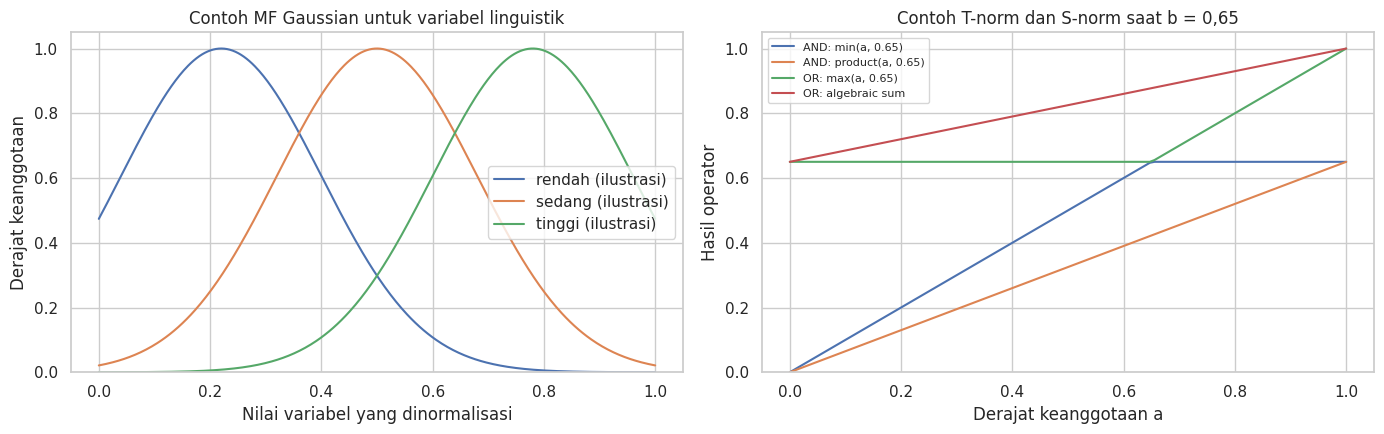

Catatan: MF satu dimensi di kiri adalah ilustrasi konsep linguistik, bukan rule antecedent yang dipakai model.


In [24]:
# Visualisasi konseptual: istilah linguistik, MF Gaussian, T-norm, dan S-norm
# Grafik ini untuk menjelaskan teori dasar; MF satu dimensi ini TIDAK digunakan
# sebagai antecedent operasional model occupancy yang dilatih.
x_demo_mf = np.linspace(0, 1, 400)
centers_demo_mf = [0.22, 0.50, 0.78]
sigma_demo_mf = 0.18
labels_demo_mf = ["rendah (ilustrasi)", "sedang (ilustrasi)", "tinggi (ilustrasi)"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for center, label in zip(centers_demo_mf, labels_demo_mf):
    mu = np.exp(-0.5 * ((x_demo_mf - center) / sigma_demo_mf) ** 2)
    axes[0].plot(x_demo_mf, mu, label=label)
axes[0].set_title("Contoh MF Gaussian untuk variabel linguistik")
axes[0].set_xlabel("Nilai variabel yang dinormalisasi")
axes[0].set_ylabel("Derajat keanggotaan")
axes[0].set_ylim(0, 1.05)
axes[0].legend()

# Bandingkan operator untuk dua derajat keanggotaan a dan b.
a = np.linspace(0, 1, 120)
b = np.linspace(0, 1, 120)
A, B = np.meshgrid(a, b)
T_min = np.minimum(A, B)
T_product = A * B
S_max = np.maximum(A, B)
S_algebraic = A + B - A * B
axes[1].plot(a, np.minimum(a, 0.65), label="AND: min(a, 0.65)")
axes[1].plot(a, a * 0.65, label="AND: product(a, 0.65)")
axes[1].plot(a, np.maximum(a, 0.65), label="OR: max(a, 0.65)")
axes[1].plot(a, a + 0.65 - a * 0.65, label="OR: algebraic sum")
axes[1].set_title("Contoh T-norm dan S-norm saat b = 0,65")
axes[1].set_xlabel("Derajat keanggotaan a")
axes[1].set_ylabel("Hasil operator")
axes[1].set_ylim(0, 1.05)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

print("Catatan: MF satu dimensi di kiri adalah ilustrasi konsep linguistik, bukan rule antecedent yang dipakai model.")

In [25]:
# 17. Fungsi dasar fuzzy clustering

def regularize_covariance(cov, reg=1e-2):
    cov = np.asarray(cov, dtype=float)
    cov = (cov + cov.T) / 2.0

    eigenvalues, eigenvectors = np.linalg.eigh(cov)
    scale = max(float(np.trace(cov) / cov.shape[0]), 1e-6)
    eigen_floor = max(reg * scale, 1e-6)
    eigenvalues = np.maximum(eigenvalues, eigen_floor)

    cov_reg = (eigenvectors * eigenvalues) @ eigenvectors.T
    return (cov_reg + cov_reg.T) / 2.0


def distances_euclidean_squared(X, centers):
    diff = X[None, :, :] - centers[:, None, :]
    return np.sum(diff ** 2, axis=2)


def distances_mahalanobis_squared(X, centers, matrices):
    distances = np.empty((centers.shape[0], X.shape[0]), dtype=float)
    for i in range(centers.shape[0]):
        diff = X - centers[i]
        distances[i] = np.einsum(
            "ni,ij,nj->n", diff, matrices[i], diff
        )
    return np.maximum(distances, 0.0)


def membership_from_distances(D2, m=2.0, eps=1e-12):
    D2 = np.maximum(np.asarray(D2, dtype=float), 0.0)

    with np.errstate(divide="ignore", invalid="ignore", over="ignore"):
        inverse = np.maximum(D2, eps) ** (-1.0 / (m - 1.0))
        U = inverse / np.maximum(inverse.sum(axis=0, keepdims=True), eps)

    zero_mask = D2 <= eps
    has_zero = zero_mask.any(axis=0)
    if has_zero.any():
        zero_columns = zero_mask[:, has_zero].astype(float)
        U[:, has_zero] = zero_columns / np.maximum(
            zero_columns.sum(axis=0, keepdims=True), 1.0
        )

    return U

In [26]:
# 18. Algoritma FCM dan Gustafson–Kessel dengan audit konvergensi

def _cluster_geometry(X, U, m, sample_weight, method, reg):
    """Hitung pusat, kovarians fuzzy, matriks metrik, dan jarak kuadrat."""
    n_samples, n_features = X.shape
    Um_weighted = (U ** m) * sample_weight[None, :]
    cluster_mass = Um_weighted.sum(axis=1)
    if np.any(cluster_mass <= 1e-10):
        raise FloatingPointError("Ditemukan cluster dengan massa efektif hampir nol.")

    centers = (Um_weighted @ X) / cluster_mass[:, None]
    covariances, matrices = [], []

    for i in range(U.shape[0]):
        diff = X - centers[i]
        cov = (diff.T * Um_weighted[i]) @ diff / cluster_mass[i]
        cov = regularize_covariance(cov, reg=reg)
        covariances.append(cov)

        if method == "gk":
            eigvals, eigvecs = np.linalg.eigh(cov)
            determinant = float(np.prod(eigvals))
            determinant = max(determinant, 1e-30)
            # GK dengan kendala |A_i| = 1 (rho_i = 1).
            metric = (determinant ** (1.0 / n_features)) * (
                (eigvecs * (1.0 / eigvals)) @ eigvecs.T
            )
        else:
            metric = np.eye(n_features)
        matrices.append(metric)

    covariances = np.stack(covariances)
    matrices = np.stack(matrices)
    D2 = (
        distances_mahalanobis_squared(X, centers, matrices)
        if method == "gk"
        else distances_euclidean_squared(X, centers)
    )
    return centers, covariances, matrices, D2, cluster_mass


def fit_fuzzy_cluster(
    X, c, method="gk", m=2.0, max_iter=220, tol=1e-5,
    reg=1e-2, seed=42, sample_weight=None
):
    """FCM/GK; status konvergensi diverifikasi terhadap geometri final."""
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or not np.isfinite(X).all():
        raise ValueError("X harus matriks 2D yang seluruh nilainya finite.")
    if c < 2 or c >= len(X):
        raise ValueError("c harus >= 2 dan lebih kecil dari jumlah observasi.")
    if m <= 1:
        raise ValueError("m harus lebih besar dari 1.")

    n_samples, _ = X.shape
    if sample_weight is None:
        sample_weight = np.ones(n_samples, dtype=float)
    else:
        sample_weight = np.asarray(sample_weight, dtype=float).ravel()
        if len(sample_weight) != n_samples or np.any(sample_weight <= 0):
            raise ValueError("sample_weight harus positif dan sama panjang dengan X.")

    method = method.lower()
    if method not in {"fcm", "gk"}:
        raise ValueError("method harus 'fcm' atau 'gk'.")

    rng = np.random.default_rng(seed)
    U = rng.dirichlet(np.ones(c), size=n_samples).T
    delta_history, update_delta_history, objective_history = [], [], []
    converged = False
    final_delta = np.inf

    for iteration in range(1, max_iter + 1):
        # Langkah 1: geometri dihitung dari U saat ini.
        _, _, _, D2, _ = _cluster_geometry(
            X, U, m, sample_weight, method, reg
        )
        U_new = membership_from_distances(D2, m=m)
        update_delta = float(np.max(np.abs(U_new - U)))
        U = U_new

        # Langkah 2: periksa konsistensi U dengan geometri yang dibentuk oleh U baru.
        _, _, _, D2_check, _ = _cluster_geometry(
            X, U, m, sample_weight, method, reg
        )
        U_check = membership_from_distances(D2_check, m=m)
        consistency_delta = float(np.max(np.abs(U_check - U)))
        objective = float(np.sum((U ** m) * sample_weight[None, :] * D2_check))

        update_delta_history.append(update_delta)
        delta_history.append(consistency_delta)
        objective_history.append(objective)

        if consistency_delta < tol:
            converged = True
            final_delta = consistency_delta
            break

        U = U_check
        final_delta = consistency_delta

    # Geometri akhir dihitung ulang dari U yang dikembalikan.
    centers, covariances, matrices, D2_final, cluster_mass = _cluster_geometry(
        X, U, m, sample_weight, method, reg
    )
    U_final_check = membership_from_distances(D2_final, m=m)
    final_consistency_delta = float(np.max(np.abs(U_final_check - U)))
    converged = bool(final_consistency_delta < tol)
    objective = float(np.sum((U ** m) * sample_weight[None, :] * D2_final))

    if not np.allclose(U.sum(axis=0), 1.0, atol=1e-7):
        raise RuntimeError("Membership matrix tidak memenuhi jumlah keanggotaan = 1.")
    if not np.isfinite(centers).all() or not np.isfinite(covariances).all():
        raise FloatingPointError("Pusat atau kovarians cluster tidak finite.")

    return {
        "U": U,
        "centers": centers,
        "covariances": covariances,
        "matrices": matrices,
        "objective": objective,
        "iterations": iteration,
        "delta": final_consistency_delta,
        "converged": converged,
        "delta_history": np.asarray(delta_history),
        "update_delta_history": np.asarray(update_delta_history),
        "objective_history": np.asarray(objective_history),
        "cluster_mass": cluster_mass,
        "method": method,
        "m": m,
        "sample_weight": sample_weight,
        "tol": tol,
        "reg": reg,
        "n_init_converged": None
    }


def fit_best_cluster(
    X, c, method, n_init=2, seed=42, sample_weight=None,
    require_convergence=False, **kwargs
):
    """Multi-start; pilih objective terkecil di antara run yang konvergen."""
    runs = [
        fit_fuzzy_cluster(
            X, c=c, method=method, seed=seed + run,
            sample_weight=sample_weight, **kwargs
        )
        for run in range(n_init)
    ]
    converged_runs = [run for run in runs if run["converged"]]
    pool = converged_runs if converged_runs else runs

    # ARI antarinisialisasi membandingkan label cluster dominan dan invariant terhadap permutasi label.
    # Ini diagnostik tambahan; tidak menggantikan pemeriksaan membership fuzzy atau skor prediksi.
    pairwise_ari = []
    for left_idx in range(len(converged_runs)):
        for right_idx in range(left_idx + 1, len(converged_runs)):
            left_labels = np.argmax(converged_runs[left_idx]["U"], axis=0)
            right_labels = np.argmax(converged_runs[right_idx]["U"], axis=0)
            pairwise_ari.append(float(adjusted_rand_score(left_labels, right_labels)))
    partition_ari_mean = float(np.mean(pairwise_ari)) if pairwise_ari else np.nan
    partition_ari_min = float(np.min(pairwise_ari)) if pairwise_ari else np.nan
    best = min(pool, key=lambda item: item["objective"])
    best = dict(best)
    best["n_init_total"] = n_init
    best["n_init_converged"] = len(converged_runs)
    best["partition_ari_mean"] = partition_ari_mean
    best["partition_ari_min"] = partition_ari_min
    best["initialization_diagnostics"] = [
        {
            "objective": float(run["objective"]),
            "iterations": int(run["iterations"]),
            "delta": float(run["delta"]),
            "converged": bool(run["converged"])
        }
        for run in runs
    ]
    if require_convergence and not best["converged"]:
        raise RuntimeError(
            f"Tidak ada inisialisasi {method.upper()} yang konvergen "
            f"untuk C={c}, m={kwargs.get('m')}, max_iter={kwargs.get('max_iter')}. "
            "Naikkan max_iter atau periksa konfigurasi."
        )
    return best

In [27]:
# 19. Indeks validasi partisi fuzzy

def fuzzy_validity_indices(cluster_model):
    U = cluster_model["U"]
    C, N = U.shape
    eps = 1e-12

    fpc = float(np.sum(U ** 2) / N)
    pe = float(-np.sum(U * np.log(np.maximum(U, eps))) / N)
    pe_normalized = float(pe / np.log(C))
    mpc = float(1.0 - (C / (C - 1.0)) * (1.0 - fpc))

    return {
        "FPC": fpc,
        "PE": pe,
        "PE_normalized": pe_normalized,
        "MPC": mpc,
        "minimum_membership_mass": float(U.sum(axis=1).min())
    }


def xie_beni_euclidean(Z, cluster_model):
    U = cluster_model["U"]
    centers = cluster_model["centers"]
    m = cluster_model["m"]

    D2 = distances_euclidean_squared(Z, centers)
    center_D2 = distances_euclidean_squared(centers, centers)
    np.fill_diagonal(center_D2, np.inf)
    min_separation = float(np.min(center_D2))

    if min_separation <= 1e-12:
        return np.inf

    numerator = float(np.sum((U ** m) * D2))
    return numerator / (len(Z) * min_separation)

**Catatan indeks Xie–Beni:** notebook menghitung versi Euclidean sebagai indeks tambahan agar hasil bisa dibaca secara umum. Untuk GK, jarak objektif utamanya adalah jarak adaptif berbasis matriks kovarians; karena itu nilai `XB_Euclidean_supplementary` tidak dipakai sebagai kriteria utama pemilihan model GK dan tidak boleh ditafsirkan sebagai indeks yang sepenuhnya mengikuti metrik GK.

In [28]:
# 20. Membership antecedent dan estimasi konsekuen Sugeno

def projected_gaussian_membership(X, centers_x, covariances_x, reg=1e-2):
    """Peak-normalized Gaussian ellipsoidal MF (bukan density); dinormalisasi menjadi firing strength relatif."""
    X = np.asarray(X, dtype=float)
    n_rules = centers_x.shape[0]
    log_membership = np.empty((len(X), n_rules), dtype=float)

    for i in range(n_rules):
        cov = regularize_covariance(covariances_x[i], reg=reg)
        inv_cov = np.linalg.inv(cov)
        diff = X - centers_x[i]
        distance_squared = np.einsum("ni,ij,nj->n", diff, inv_cov, diff)
        log_membership[:, i] = -0.5 * np.maximum(distance_squared, 0.0)

    log_membership -= log_membership.max(axis=1, keepdims=True)
    membership = np.exp(log_membership)
    membership /= np.maximum(membership.sum(axis=1, keepdims=True), 1e-12)
    return membership


def fit_tsk_model(
    X, y_scaled, c, method="gk", m=2.0, ridge_alpha=1e-2,
    n_init=2, max_iter=220, seed=42, sample_weight=None,
    require_convergence=False, tol=1e-5
):
    """Identifikasi antecedent via product-space clustering dan consequent via augmented WLS.

    Product-space membership mengidentifikasi hubungan input-output pada training.
    Proyeksi pusat dan blok kovarians input membentuk antecedent yang dapat dihitung
    saat inferensi tanpa target. Membership antecedent input-space yang sama dipakai
    untuk bobot WLS dan firing strength saat inferensi.
    """
    X = np.asarray(X, dtype=float)
    y_scaled = np.asarray(y_scaled, dtype=float).ravel()
    if len(X) != len(y_scaled):
        raise ValueError("X dan y_scaled harus memiliki jumlah baris sama.")
    if not np.isfinite(X).all() or not np.isfinite(y_scaled).all():
        raise ValueError("X dan y_scaled harus berisi nilai finite.")

    if sample_weight is None:
        sample_weight = np.ones(len(X), dtype=float)
    else:
        sample_weight = np.asarray(sample_weight, dtype=float).ravel()
        if len(sample_weight) != len(X) or np.any(sample_weight <= 0):
            raise ValueError("sample_weight harus positif dan sama panjang dengan X.")

    if ridge_alpha <= 0:
        raise ValueError("ridge_alpha harus > 0 untuk menjaga kestabilan estimasi.")

    Z = np.column_stack([X, y_scaled])
    cluster_model = fit_best_cluster(
        Z, c=c, method=method, n_init=n_init, seed=seed,
        sample_weight=sample_weight, require_convergence=require_convergence,
        m=m, max_iter=max_iter, tol=tol
    )

    n_features = X.shape[1]
    centers_x = cluster_model["centers"][:, :n_features]
    covariances_x = cluster_model["covariances"][:, :n_features, :n_features]
    covariances_x = np.stack([
        regularize_covariance(cov, reg=cluster_model["reg"])
        for cov in covariances_x
    ])

    U_antecedent = projected_gaussian_membership(
        X, centers_x, covariances_x, reg=cluster_model["reg"]
    )
    if not np.allclose(U_antecedent.sum(axis=1), 1.0, atol=1e-7):
        raise RuntimeError("Firing strength antecedent tidak ternormalisasi.")

    # Weighted Ridge Least Squares: theta_i = (Phi' W_i Phi + lambda R)^-1 Phi' W_i y.
    Phi = np.column_stack([X, np.ones(len(X))])
    penalty = np.eye(Phi.shape[1]) * ridge_alpha
    penalty[-1, -1] = 0.0  # intercept tidak diregularisasi
    consequents, wls_diagnostics = [], []

    for i in range(c):
        weights = (U_antecedent[:, i] ** m) * sample_weight
        sqrt_weights = np.sqrt(np.maximum(weights, 0.0))
        Phi_weighted = Phi * sqrt_weights[:, None]
        y_weighted = y_scaled * sqrt_weights
        # Solve the regularized weighted least-squares problem as an
        # augmented least-squares system, avoiding explicit normal equations.
        penalty_sqrt = np.diag(np.sqrt(np.diag(penalty)))
        augmented_design = np.vstack([Phi_weighted, penalty_sqrt])
        augmented_target = np.concatenate([
            y_weighted, np.zeros(Phi.shape[1], dtype=float)
        ])
        theta, residuals, rank, singular_values = np.linalg.lstsq(
            augmented_design, augmented_target, rcond=None
        )
        normal_matrix = Phi_weighted.T @ Phi_weighted + penalty
        consequents.append(theta)
        wls_diagnostics.append({
            "rule": f"R{i+1}",
            "effective_weight_sum": float(weights.sum()),
            "effective_sample_size": float(weights.sum() ** 2 / np.sum(weights ** 2)),
            "condition_number_normal_matrix": float(np.linalg.cond(normal_matrix)),
            "augmented_design_rank": int(rank),
            "minimum_singular_value_augmented": float(singular_values.min()),
            "solver": "augmented_lstsq"
        })

    return {
        "cluster": cluster_model,
        "centers_x": centers_x,
        "covariances_x": covariances_x,
        "U_antecedent_train": U_antecedent,
        "consequents": np.vstack(consequents),
        "wls_diagnostics": pd.DataFrame(wls_diagnostics),
        "method": method, "c": c, "m": m,
        "ridge_alpha": ridge_alpha,
        "converged": cluster_model["converged"]
    }


def predict_tsk_model(model, X_scaled):
    X_scaled = np.asarray(X_scaled, dtype=float)
    firing = projected_gaussian_membership(
        X_scaled, model["centers_x"], model["covariances_x"]
    )
    Phi = np.column_stack([X_scaled, np.ones(len(X_scaled))])
    local_outputs = Phi @ model["consequents"].T
    prediction = np.sum(firing * local_outputs, axis=1)
    return prediction, firing, local_outputs

In [29]:
# 21. Pemeriksaan numerik fungsi fuzzy dengan data sintetis

rng = np.random.default_rng(123)
X_demo = np.vstack([
    rng.normal(-1.0, 0.35, size=(60, 3)),
    rng.normal(1.0, 0.35, size=(60, 3))
])
y_demo = np.r_[
    X_demo[:60, 0] + rng.normal(0, 0.1, 60),
    2 * X_demo[60:, 0] + rng.normal(0, 0.1, 60)
]

demo_model = fit_tsk_model(
    X_demo, y_demo, c=2, method="gk",
    n_init=2, max_iter=80, seed=123
)
demo_pred, demo_firing, _ = predict_tsk_model(demo_model, X_demo)

assert demo_model["cluster"]["U"].shape == (2, 120)
assert np.allclose(demo_model["cluster"]["U"].sum(axis=0), 1.0, atol=1e-6)
assert np.allclose(demo_firing.sum(axis=1), 1.0, atol=1e-8)
assert np.isfinite(demo_pred).all()

print("Pemeriksaan numerik lolos.")
print("Membership training:", demo_model["cluster"]["U"].shape)
print("Firing strength inferensi:", demo_firing.shape)

Pemeriksaan numerik lolos.
Membership training: (2, 120)
Firing strength inferensi: (120, 2)


## 8. Mencari konfigurasi yang paling sesuai

Jumlah cluster menentukan jumlah aturan Sugeno. Pencarian membandingkan dua representasi fitur, FCM/GK, beberapa jumlah cluster, nilai fuzzifier \(m\), dan dua skema bobot sampel.

**Pemeriksaan konvergensi menjadi syarat kelayakan.** Setiap konfigurasi dicoba dengan beberapa random initialization. Hanya konfigurasi yang memenuhi toleransi konsistensi membership dan jumlah minimum inisialisasi konvergen yang dapat masuk proses seleksi. Konfigurasi yang gagal tetap dicatat untuk audit, tetapi tidak boleh menang.

**Urutan seleksi yang benar-benar diterapkan oleh kode, dan ditetapkan sebelum test dibuka:**
1. Validation **MAE bounded** sebagai kriteria utama. Ini menilai keluaran operasional setelah prediksi dibatasi pada rentang fisik 0–3 orang.
2. Validation Macro F1 yang lebih tinggi.
3. Validation balanced accuracy yang lebih tinggi.
4. Raw out-of-range rate yang lebih rendah.
5. Validation MAE raw yang lebih rendah.
6. Jumlah aturan yang lebih sedikit jika seluruh kriteria sebelumnya setara.

MAE raw tetap penting dan selalu dilaporkan karena clipping dapat menyembunyikan perilaku keluaran matematis Sugeno. Karena itu, pemilihan menggunakan MAE bounded **tidak** berarti prediksi raw diabaikan: out-of-range rate dan MAE raw menjadi kriteria sekunder/diagnostik.

Setelah pencarian awal, delapan konfigurasi teratas yang eligible masuk shortlist untuk tuning ridge \(\lambda\). Pemilihan akhir tetap menggunakan validation. Test set tidak digunakan untuk memilih fitur, metode, jumlah cluster, fuzzifier, bobot sampel, maupun ridge alpha.

Konfigurasi hanya eligible bila minimal 3 dari 4 inisialisasi konvergen pada pencarian awal dan tuning ridge. Model final kemudian dilatih ulang pada gabungan train+validation dengan minimal 7 dari 10 inisialisasi konvergen. Jumlah run konvergen tidak otomatis membuktikan partisi cluster identik; karena itu notebook juga menghitung Adjusted Rand Index (ARI) antarinisialisasi berdasarkan label cluster dominan sebagai diagnostik tambahan. ARI tidak dipakai sebagai pengganti evaluasi fuzzy atau metrik prediksi.

In [ ]:
# 22. Fungsi evaluasi: output kontinu raw, bounded, dan jumlah diskrit

LABELS = [0, 1, 2, 3]


def bound_occupancy_prediction(y_pred_continuous):
    """Pembatasan fisik output ke rentang okupansi 0–3 orang."""
    return np.clip(np.asarray(y_pred_continuous, dtype=float), 0.0, 3.0)


def to_count_prediction(y_pred_continuous):
    """Clip ke 0-3 lalu pembulatan terdekat; flooring menimbulkan bias ke bawah."""
    bounded = bound_occupancy_prediction(y_pred_continuous)
    return np.floor(bounded + 0.5).astype(int)


def evaluate_occupancy(y_true, y_pred_continuous):
    y_true = np.asarray(y_true, dtype=int)
    y_raw = np.asarray(y_pred_continuous, dtype=float)
    y_bounded = bound_occupancy_prediction(y_raw)
    y_count = to_count_prediction(y_raw)
    below = y_raw < 0.0
    above = y_raw > 3.0
    excess = np.maximum(0.0, -y_raw) + np.maximum(0.0, y_raw - 3.0)

    return {
        "MAE_raw": float(mean_absolute_error(y_true, y_raw)),
        "RMSE_raw": float(np.sqrt(mean_squared_error(y_true, y_raw))),
        "MAE_bounded": float(mean_absolute_error(y_true, y_bounded)),
        "RMSE_bounded": float(np.sqrt(mean_squared_error(y_true, y_bounded))),
        "Exact_Count_Accuracy": float(accuracy_score(y_true, y_count)),
        "Macro_F1": float(f1_score(
            y_true, y_count, labels=LABELS,
            average="macro", zero_division=0
        )),
        "Balanced_Accuracy": float(balanced_accuracy_score(y_true, y_count)),
        "Within_1_Person": float(np.mean(np.abs(y_true - y_count) <= 1)),
        "Out_of_range_rate_raw": float(np.mean(below | above)),
        "Below_zero_rate_raw": float(np.mean(below)),
        "Above_three_rate_raw": float(np.mean(above)),
        "Mean_out_of_range_excess": float(np.mean(excess)),
        "Raw_prediction_min": float(np.min(y_raw)),
        "Raw_prediction_max": float(np.max(y_raw))
    }

In [31]:
# 23. Eksperimen konfigurasi pada validation set dengan multi-start dan convergence gate

C_CANDIDATES = [2, 3, 4]
METHODS = ["fcm", "gk"]
WEIGHT_MODES = ["none", "sqrt_balanced"]
M_CANDIDATES = [1.5, 2.0, 2.5]
RIDGE_ALPHA_SCREEN = 1e-2
N_INIT_SEARCH = 4
MIN_CONVERGED_SEARCH = 3
MAX_ITER_SEARCH = 400
CONVERGENCE_TOL = 1e-5

search_records = []

for feature_set_name, data in prepared.items():
    Xtr = data["X_train"]
    Xva = data["X_val"]
    Z_train = np.column_stack([Xtr, y_train_scaled])

    for weight_mode in WEIGHT_MODES:
        sample_weights = make_sample_weights(y_train, weight_mode)

        for method in METHODS:
            for c in C_CANDIDATES:
                for m_value in M_CANDIDATES:
                    print(
                        f"{feature_set_name} | {method.upper()} | C={c} | "
                        f"m={m_value} | weights={weight_mode}"
                    )
                    model = fit_tsk_model(
                        Xtr, y_train_scaled, c=c, method=method,
                        m=m_value, ridge_alpha=RIDGE_ALPHA_SCREEN,
                        n_init=N_INIT_SEARCH, max_iter=MAX_ITER_SEARCH,
                        tol=CONVERGENCE_TOL, seed=RANDOM_STATE,
                        sample_weight=sample_weights,
                        require_convergence=False
                    )
                    cluster_diag = model["cluster"]

                    record = {
                        "feature_set": feature_set_name,
                        "method": method.upper(),
                        "C": c,
                        "m": m_value,
                        "weight_mode": weight_mode,
                        "ridge_alpha": RIDGE_ALPHA_SCREEN,
                        "objective": cluster_diag["objective"],
                        "iterations": cluster_diag["iterations"],
                        "convergence_delta": cluster_diag["delta"],
                        "converged": cluster_diag["converged"],
                        "n_init_converged": cluster_diag["n_init_converged"],
                        "n_init_total": cluster_diag["n_init_total"],
                        "meets_multi_start_convergence_gate": (
                            cluster_diag["n_init_converged"] >= MIN_CONVERGED_SEARCH
                        ),
                        "eligible_for_selection": False,
                        "minimum_cluster_mass": float(cluster_diag["cluster_mass"].min()),
                        "partition_ari_mean": cluster_diag["partition_ari_mean"],
                        "partition_ari_min": cluster_diag["partition_ari_min"],
                        "XB_Euclidean_supplementary": xie_beni_euclidean(Z_train, cluster_diag)
                    }

                    if (
                        cluster_diag["converged"]
                        and cluster_diag["n_init_converged"] >= MIN_CONVERGED_SEARCH
                    ):
                        record["eligible_for_selection"] = True
                        val_pred_scaled, _, _ = predict_tsk_model(model, Xva)
                        val_pred = y_scaler_search.inverse_transform(
                            val_pred_scaled.reshape(-1, 1)
                        ).ravel()
                        scores = evaluate_occupancy(y_val, val_pred)
                        validity = fuzzy_validity_indices(cluster_diag)
                        record.update({f"val_{key}": value for key, value in scores.items()})
                        record.update(validity)
                    else:
                        # Non-converged candidate is retained for audit, but cannot win.
                        record.update({
                            key: np.nan for key in [
                                "val_MAE_raw", "val_RMSE_raw", "val_MAE_bounded",
                                "val_RMSE_bounded", "val_Exact_Count_Accuracy",
                                "val_Macro_F1", "val_Balanced_Accuracy",
                                "val_Within_1_Person", "val_Out_of_range_rate_raw",
                                "val_Below_zero_rate_raw", "val_Above_three_rate_raw",
                                "val_Mean_out_of_range_excess", "val_Raw_prediction_min",
                                "val_Raw_prediction_max", "FPC", "PE",
                                "PE_normalized", "MPC", "minimum_membership_mass"
                            ]
                        })
                    search_records.append(record)

search_results = pd.DataFrame(search_records)
print("Jumlah konfigurasi:", len(search_results))
print("Konfigurasi dengan setidaknya satu inisialisasi konvergen:", int(search_results["converged"].sum()))
print("Konfigurasi yang memenuhi kelayakan multi-start berdasarkan konvergensi:", int(search_results["eligible_for_selection"].sum()))
print("Konfigurasi yang tidak memenuhi multi-start convergence gate:",
      int((~search_results["eligible_for_selection"]).sum()))
display(search_results.sort_values(
    ["eligible_for_selection", "val_MAE_bounded", "val_Macro_F1"],
    ascending=[False, True, False], na_position="last"
).round(5).reset_index(drop=True))

compact | FCM | C=2 | m=1.5 | weights=none
compact | FCM | C=2 | m=2.0 | weights=none
compact | FCM | C=2 | m=2.5 | weights=none
compact | FCM | C=3 | m=1.5 | weights=none
compact | FCM | C=3 | m=2.0 | weights=none
compact | FCM | C=3 | m=2.5 | weights=none
compact | FCM | C=4 | m=1.5 | weights=none
compact | FCM | C=4 | m=2.0 | weights=none
compact | FCM | C=4 | m=2.5 | weights=none
compact | GK | C=2 | m=1.5 | weights=none
compact | GK | C=2 | m=2.0 | weights=none
compact | GK | C=2 | m=2.5 | weights=none
compact | GK | C=3 | m=1.5 | weights=none
compact | GK | C=3 | m=2.0 | weights=none
compact | GK | C=3 | m=2.5 | weights=none
compact | GK | C=4 | m=1.5 | weights=none
compact | GK | C=4 | m=2.0 | weights=none
compact | GK | C=4 | m=2.5 | weights=none
compact | FCM | C=2 | m=1.5 | weights=sqrt_balanced
compact | FCM | C=2 | m=2.0 | weights=sqrt_balanced
compact | FCM | C=2 | m=2.5 | weights=sqrt_balanced
compact | FCM | C=3 | m=1.5 | weights=sqrt_balanced
compact | FCM | C=3 | m=2.0

,feature_set,method,C,m,weight_mode,ridge_alpha,objective,iterations,convergence_delta,converged,n_init_converged,n_init_total,meets_multi_start_convergence_gate,eligible_for_selection,minimum_cluster_mass,partition_ari_mean,partition_ari_min,XB_Euclidean_supplementary,val_MAE_raw,val_RMSE_raw,val_MAE_bounded,val_RMSE_bounded,val_Exact_Count_Accuracy,val_Macro_F1,val_Balanced_Accuracy,val_Within_1_Person,val_Out_of_range_rate_raw,val_Below_zero_rate_raw,val_Above_three_rate_raw,val_Mean_out_of_range_excess,val_Raw_prediction_min,val_Raw_prediction_max,FPC,PE,PE_normalized,MPC,minimum_membership_mass
0,compact,GK,4,2.0,none,0.01,7.046138e+02,62,0.00001,True,4,4,True,True,326.56096,0.51870,0.35758,0.29291,0.09624,0.32930,0.08556,0.30081,0.96689,0.90580,0.93311,0.99172,0.39387,0.38948,0.00438,0.01068,-0.56117,3.10899,0.90589,0.19174,0.13831,0.87452,451.83937
1,extended,FCM,4,2.5,sqrt_balanced,0.01,8.736050e+05,41,0.00001,True,4,4,True,True,214.26322,1.00000,1.00000,0.04570,0.13629,0.22520,0.09279,0.21477,0.95131,0.83081,0.83578,0.99757,0.62317,0.61198,0.01120,0.04350,-0.44281,3.49676,0.79026,0.43381,0.31292,0.72035,421.58466
2,extended,GK,4,2.0,sqrt_balanced,0.01,6.372380e+04,73,0.00001,True,4,4,True,True,350.13401,1.00000,1.00000,0.60229,0.10946,0.23747,0.09805,0.23615,0.93379,0.76713,0.77040,0.99854,0.48053,0.47420,0.00633,0.01141,-0.18324,3.25524,0.58371,0.73789,0.53227,0.44495,454.97102
3,extended,GK,3,1.5,sqrt_balanced,0.01,1.122351e+05,21,0.00001,True,4,4,True,True,869.54471,0.65243,0.37116,0.41781,0.11439,0.24339,0.10081,0.24188,0.93135,0.76971,0.78810,0.99951,0.53554,0.52872,0.00682,0.01358,-0.26796,3.25825,0.93058,0.12672,0.11535,0.89587,455.64540
4,extended,FCM,4,1.5,none,0.01,1.237965e+06,35,0.00001,True,4,4,True,True,190.59301,0.95575,0.91150,0.06095,0.11302,0.26751,0.10089,0.26518,0.93574,0.75496,0.75096,0.99513,0.41870,0.40944,0.00925,0.01213,-0.12370,3.53459,0.94853,0.09706,0.07001,0.93137,237.02976
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,compact,GK,2,2.0,sqrt_balanced,0.01,3.815873e+03,39,0.00001,True,4,4,True,True,2264.39363,1.00000,1.00000,0.13253,0.21529,0.44625,0.20287,0.44558,0.88267,0.65392,0.74308,0.97907,0.45375,0.44791,0.00584,0.01242,-0.03404,3.24057,0.91727,0.14703,0.21212,0.83453,1209.47369
68,compact,GK,2,2.5,sqrt_balanced,0.01,3.103644e+03,44,0.00001,True,4,4,True,True,1671.88334,1.00000,1.00000,0.11548,0.21764,0.43879,0.20350,0.43793,0.89241,0.67843,0.75769,0.97274,0.46008,0.45424,0.00584,0.01414,-0.03701,3.27037,0.82719,0.27929,0.40293,0.65439,1417.90474
69,compact,FCM,2,2.5,sqrt_balanced,0.01,6.196930e+03,9,0.00000,True,4,4,True,True,1218.09159,1.00000,1.00000,0.04444,0.24517,0.42923,0.22092,0.42735,0.91334,0.67610,0.73426,0.97907,0.42405,0.41821,0.00584,0.02425,-0.08196,3.14820,0.81912,0.30826,0.44472,0.63824,1226.45492
70,compact,FCM,2,2.0,sqrt_balanced,0.01,7.944247e+03,9,0.00000,True,4,4,True,True,1573.45423,1.00000,1.00000,0.05902,0.25387,0.43438,0.22616,0.43207,0.91334,0.67610,0.73426,0.97907,0.45229,0.44645,0.00584,0.02770,-0.08944,3.14171,0.89010,0.19120,0.27584,0.78021,1069.49253


In [32]:
# 24. Menyusun shortlist konfigurasi konvergen dari validation set

eligible_search = search_results[
    search_results["eligible_for_selection"]
    & np.isfinite(search_results["val_MAE_bounded"])
].copy()
if eligible_search.empty:
    raise RuntimeError(
        "Tidak ada konfigurasi yang konvergen pada pencarian awal. "
        "Naikkan MAX_ITER_SEARCH atau periksa stabilitas data dan kovarians."
    )

# Kriteria ditetapkan sebelum test dibuka:
# 1) MAE bounded sebagai metrik utama karena output operasional dibatasi 0–3;
# 2) Macro F1 dan balanced accuracy untuk memeriksa kelas minoritas;
# 3) raw out-of-range rate dan MAE raw sebagai diagnostik.
ranked_search = eligible_search.sort_values(
    ["val_MAE_bounded", "val_Macro_F1", "val_Balanced_Accuracy",
     "val_Out_of_range_rate_raw", "val_MAE_raw", "C"],
    ascending=[True, False, False, True, True, True]
)

# Pertahankan kombinasi konfigurasi yang unik, lalu tuning ridge pada shortlist.
config_columns = ["feature_set", "method", "C", "m", "weight_mode"]
shortlist_configs = ranked_search.drop_duplicates(subset=config_columns).head(8).reset_index(drop=True)
print("Shortlist konfigurasi untuk tuning ridge (ranking utama: MAE bounded validation):")
display(shortlist_configs[
    config_columns + ["val_MAE_raw", "val_MAE_bounded", "val_Macro_F1",
                      "val_Out_of_range_rate_raw", "n_init_converged", "convergence_delta",
                      "partition_ari_mean", "partition_ari_min"]
].round(5))

Shortlist konfigurasi untuk tuning ridge (ranking utama: MAE bounded validation):


,feature_set,method,C,m,weight_mode,val_MAE_raw,val_MAE_bounded,val_Macro_F1,val_Out_of_range_rate_raw,n_init_converged,convergence_delta,partition_ari_mean,partition_ari_min
0,compact,GK,4,2.0,none,0.09624,0.08556,0.90580,0.39387,4,0.00001,0.51870,0.35758
1,extended,FCM,4,2.5,sqrt_balanced,0.13629,0.09279,0.83081,0.62317,4,0.00001,1.00000,1.00000
2,extended,GK,4,2.0,sqrt_balanced,0.10946,0.09805,0.76713,0.48053,4,0.00001,1.00000,1.00000
3,extended,GK,3,1.5,sqrt_balanced,0.11439,0.10081,0.76971,0.53554,4,0.00001,0.65243,0.37116
4,extended,FCM,4,1.5,none,0.11302,0.10089,0.75496,0.41870,4,0.00001,0.95575,0.91150
5,extended,FCM,4,2.0,none,0.13104,0.10435,0.77058,0.58715,4,0.00001,1.00000,1.00000
6,extended,GK,4,2.5,sqrt_balanced,0.12429,0.10508,0.77070,0.55745,4,0.00001,1.00000,1.00000
7,extended,GK,4,1.5,sqrt_balanced,0.12176,0.10682,0.78617,0.46397,4,0.00001,0.48967,0.31648


### Menyetel regularisasi consequent dengan validation set

Nilai \(\lambda\) mengatur kekuatan penalti ridge pada koefisien linear consequent. Nilai terlalu kecil dapat membuat koefisien sensitif ketika fitur berkorelasi; nilai terlalu besar dapat membuat consequent terlalu sederhana.

Notebook mengambil **delapan konfigurasi teratas** yang sudah memenuhi multi-start convergence gate pada pencarian awal, lalu menguji beberapa nilai \(\lambda\) pada masing-masing konfigurasi. Pemilihan akhir tetap berdasarkan validation; test tidak disentuh sampai evaluasi akhir.

Estimasi consequent diselesaikan sebagai *augmented weighted least squares* dengan `numpy.linalg.lstsq`, bukan dengan membentuk dan menyelesaikan persamaan normal secara langsung. Pendekatan augmented menghindari penguadratan condition number yang terjadi ketika persamaan normal dibentuk. Meski demikian, diagnostik kondisi matriks tetap dilaporkan karena parameter masih dapat sensitif terhadap fitur yang saling berkorelasi.

Konfigurasi terpilih setelah tuning ridge:
Feature set: compact
Clustering: GK
Jumlah aturan: 4
Fuzzifier m: 2.0
Pembobotan: none
Ridge alpha: 0.0001
Kriteria utama pemilihan: validation MAE bounded
Validation MAE raw (diagnostik): 0.09622
Validation MAE bounded: 0.08552
Validation Macro F1: 0.9058
Validation out-of-range rate: 0.39387


,feature_set,method,C,m,weight_mode,ridge_alpha,converged,n_init_converged,iterations,convergence_delta,val_MAE_raw,val_RMSE_raw,val_MAE_bounded,val_RMSE_bounded,val_Exact_Count_Accuracy,val_Macro_F1,val_Balanced_Accuracy,val_Within_1_Person,val_Out_of_range_rate_raw,val_Below_zero_rate_raw,val_Above_three_rate_raw,val_Mean_out_of_range_excess,val_Raw_prediction_min,val_Raw_prediction_max
0,compact,GK,4,2.0,none,0.0001,True,4,60,0.00001,0.09622,0.32930,0.08552,0.30072,0.96689,0.90580,0.93311,0.99172,0.39387,0.38948,0.00438,0.01070,-0.56255,3.10902
1,compact,GK,4,2.0,none,0.0010,True,4,60,0.00001,0.09622,0.32930,0.08552,0.30073,0.96689,0.90580,0.93311,0.99172,0.39387,0.38948,0.00438,0.01070,-0.56242,3.10901
2,compact,GK,4,2.0,none,0.0100,True,4,60,0.00001,0.09624,0.32930,0.08556,0.30081,0.96689,0.90580,0.93311,0.99172,0.39387,0.38948,0.00438,0.01068,-0.56117,3.10899
3,compact,GK,4,2.0,none,0.1000,True,4,60,0.00001,0.09640,0.32926,0.08592,0.30160,0.96641,0.90408,0.93151,0.99172,0.39241,0.38802,0.00438,0.01048,-0.54877,3.10872
4,compact,GK,4,2.0,none,1.0000,True,4,60,0.00001,0.09789,0.32957,0.08912,0.30928,0.95910,0.87649,0.90343,0.99124,0.38802,0.38364,0.00438,0.00877,-0.43425,3.10432
5,extended,FCM,4,2.5,sqrt_balanced,0.1000,True,4,42,0.00001,0.13369,0.22144,0.09032,0.21099,0.95570,0.84537,0.85696,0.99757,0.61636,0.60565,0.01071,0.04337,-0.44186,3.44123
6,extended,FCM,4,2.5,sqrt_balanced,1.0000,True,4,42,0.00001,0.13189,0.22190,0.09069,0.21263,0.95326,0.83705,0.84758,0.99757,0.60467,0.59591,0.00876,0.04120,-0.43309,3.31963
7,extended,FCM,4,2.5,sqrt_balanced,0.0100,True,4,42,0.00001,0.13629,0.22520,0.09279,0.21477,0.95131,0.83081,0.83578,0.99757,0.62317,0.61198,0.01120,0.04350,-0.44280,3.49676
8,extended,FCM,4,2.5,sqrt_balanced,0.0010,True,4,42,0.00001,0.14124,0.24829,0.09627,0.22614,0.94499,0.81446,0.82247,0.99757,0.63291,0.62171,0.01120,0.04496,-0.92475,3.50367
9,extended,FCM,4,2.5,sqrt_balanced,0.0001,True,4,42,0.00001,0.14494,0.26933,0.09742,0.22885,0.94012,0.80136,0.81248,0.99757,0.63583,0.62463,0.01120,0.04753,-1.49108,3.50438


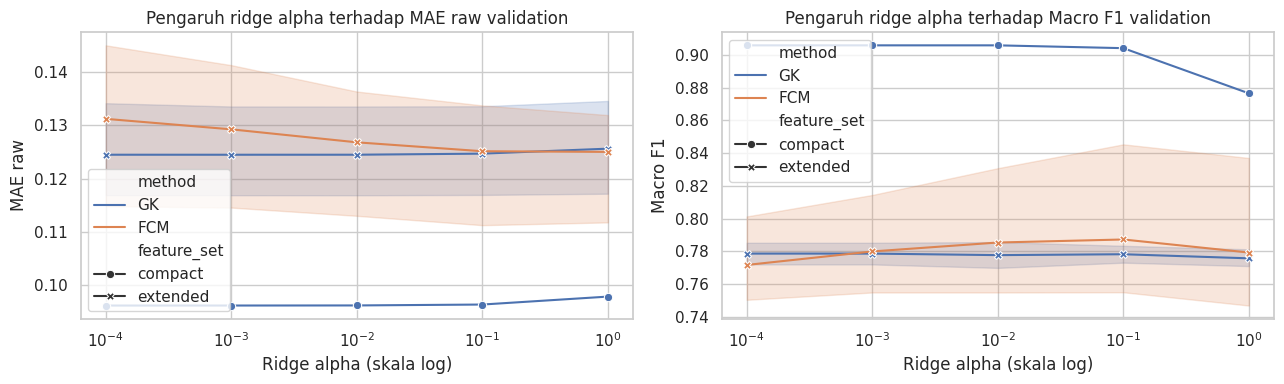

In [33]:
# 24A. Tuning ridge alpha pada beberapa konfigurasi terbaik

RIDGE_CANDIDATES = [1e-4, 1e-3, 1e-2, 1e-1, 1.0]
N_INIT_REFINE = 4
MIN_CONVERGED_REFINE = 3
MAX_ITER_REFINE = 400
refined_records = []

for _, candidate in shortlist_configs.iterrows():
    feature_set_name = candidate["feature_set"]
    method = candidate["method"].lower()
    c = int(candidate["C"])
    m_value = float(candidate["m"])
    weight_mode = candidate["weight_mode"]
    data = prepared[feature_set_name]
    weights = make_sample_weights(y_train, weight_mode)

    for alpha in RIDGE_CANDIDATES:
        try:
            model_alpha = fit_tsk_model(
                data["X_train"], y_train_scaled,
                c=c, method=method, m=m_value,
                ridge_alpha=alpha, n_init=N_INIT_REFINE,
                max_iter=MAX_ITER_REFINE, tol=CONVERGENCE_TOL,
                seed=RANDOM_STATE + 300,
                sample_weight=weights, require_convergence=False
            )
            if (
                not model_alpha["cluster"]["converged"]
                or model_alpha["cluster"]["n_init_converged"] < MIN_CONVERGED_REFINE
            ):
                refined_records.append({
                    "feature_set": feature_set_name,
                    "method": method.upper(),
                    "C": c,
                    "m": m_value,
                    "weight_mode": weight_mode,
                    "ridge_alpha": alpha,
                    "converged": False,
                    "n_init_converged": model_alpha["cluster"]["n_init_converged"],
                    "iterations": model_alpha["cluster"]["iterations"],
                    "convergence_delta": model_alpha["cluster"]["delta"],
                    "error": "Tidak memenuhi multi-start convergence gate"
                })
                continue

            pred_alpha_scaled, _, _ = predict_tsk_model(
                model_alpha, data["X_val"]
            )
            pred_alpha = y_scaler_search.inverse_transform(
                pred_alpha_scaled.reshape(-1, 1)
            ).ravel()
            scores = evaluate_occupancy(y_val, pred_alpha)
            refined_records.append({
                "feature_set": feature_set_name,
                "method": method.upper(),
                "C": c,
                "m": m_value,
                "weight_mode": weight_mode,
                "ridge_alpha": alpha,
                "converged": True,
                "n_init_converged": model_alpha["cluster"]["n_init_converged"],
                "iterations": model_alpha["cluster"]["iterations"],
                "convergence_delta": model_alpha["cluster"]["delta"],
                **{f"val_{key}": value for key, value in scores.items()}
            })
        except RuntimeError as exc:
            refined_records.append({
                "feature_set": feature_set_name,
                "method": method.upper(),
                "C": c,
                "m": m_value,
                "weight_mode": weight_mode,
                "ridge_alpha": alpha,
                "converged": False,
                "error": str(exc)
            })

refined_results = pd.DataFrame(refined_records)
refined_eligible = refined_results[
    refined_results["converged"] & np.isfinite(refined_results["val_MAE_raw"])
].copy()
if refined_eligible.empty:
    raise RuntimeError(
        "Tidak ada konfigurasi shortlist yang konvergen saat tuning ridge. "
        "Naikkan MAX_ITER_REFINE atau evaluasi kembali parameter regularisasi kovarians."
    )

refined_eligible = refined_eligible.sort_values(
    ["val_MAE_bounded", "val_Macro_F1", "val_Balanced_Accuracy",
     "val_Out_of_range_rate_raw", "val_MAE_raw", "C"],
    ascending=[True, False, False, True, True, True]
)
best_alpha_row = refined_eligible.iloc[0]

SELECTED_FEATURE_SET = best_alpha_row["feature_set"]
SELECTED_METHOD = best_alpha_row["method"].lower()
SELECTED_C = int(best_alpha_row["C"])
SELECTED_M = float(best_alpha_row["m"])
SELECTED_WEIGHT_MODE = best_alpha_row["weight_mode"]
SELECTED_RIDGE_ALPHA = float(best_alpha_row["ridge_alpha"])

print("Konfigurasi terpilih setelah tuning ridge:")
print("Feature set:", SELECTED_FEATURE_SET)
print("Clustering:", SELECTED_METHOD.upper())
print("Jumlah aturan:", SELECTED_C)
print("Fuzzifier m:", SELECTED_M)
print("Pembobotan:", SELECTED_WEIGHT_MODE)
print("Ridge alpha:", SELECTED_RIDGE_ALPHA)
print("Kriteria utama pemilihan: validation MAE bounded")
print("Validation MAE raw (diagnostik):", round(float(best_alpha_row["val_MAE_raw"]), 5))
print("Validation MAE bounded:", round(float(best_alpha_row["val_MAE_bounded"]), 5))
print("Validation Macro F1:", round(float(best_alpha_row["val_Macro_F1"]), 5))
print("Validation out-of-range rate:", round(float(best_alpha_row["val_Out_of_range_rate_raw"]), 5))
display(refined_eligible.round(5).reset_index(drop=True))

# Visualisasi pengaruh regularisasi consequent terhadap validation error.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.lineplot(
    data=refined_eligible, x="ridge_alpha", y="val_MAE_raw",
    hue="method", style="feature_set", markers=True, dashes=False, ax=axes[0]
)
axes[0].set_xscale("log")
axes[0].set_title("Pengaruh ridge alpha terhadap MAE raw validation")
axes[0].set_xlabel("Ridge alpha (skala log)")
axes[0].set_ylabel("MAE raw")
sns.lineplot(
    data=refined_eligible, x="ridge_alpha", y="val_Macro_F1",
    hue="method", style="feature_set", markers=True, dashes=False, ax=axes[1]
)
axes[1].set_xscale("log")
axes[1].set_title("Pengaruh ridge alpha terhadap Macro F1 validation")
axes[1].set_xlabel("Ridge alpha (skala log)")
axes[1].set_ylabel("Macro F1")
plt.tight_layout()
plt.show()

### Penguncian parameter sebelum membuka test set

Nilai fuzzifier `m` sudah menjadi bagian dari pencarian konfigurasi utama dan tuning ridge berbasis validation. Pencarian memakai empat inisialisasi per kandidat dan hanya kandidat dengan minimal tiga inisialisasi konvergen yang dapat dipertimbangkan. Karena itu, tidak dilakukan pemilihan ulang `m` setelah metrik test dilihat. Jika ingin menambah rentang `m`, perubahan harus dilakukan di `M_CANDIDATES`, kemudian seluruh proses pemilihan validation dan pelatihan final diulang sebelum test dibuka.

Test set hanya digunakan satu kali untuk evaluasi konfigurasi yang sudah dikunci. Hasil test tidak boleh dipakai untuk mengubah `m`, jumlah cluster, fitur, bobot sampel, atau regularisasi.

## 9. Melatih ulang model terpilih dan menguji hasilnya

Setelah konfigurasi dipilih dari validation, model dilatih ulang menggunakan gabungan train dan validation. Test set baru dibuka pada tahap evaluasi ini.

Prediksi Sugeno bersifat kontinu. Untuk menampilkan jumlah penghuni, kita membulatkannya ke bilangan bulat terdekat dan membatasi hasil pada rentang fisik 0–3. Flooring tidak dipakai karena dapat menurunkan prediksi secara sistematis.

In [34]:
# 25. Preprocessing final pada train + validation

selected_columns = FEATURE_SETS[SELECTED_FEATURE_SET]

X_dev_raw = pd.concat(
    [X_train_all[selected_columns], X_val_all[selected_columns]],
    axis=0
)
X_test_raw = X_test_all[selected_columns].copy()

y_dev = pd.concat([y_train, y_val], axis=0)
y_test_array = y_test.to_numpy(dtype=int)

imputer_final = SimpleImputer(strategy="median")
X_dev_imputed = imputer_final.fit_transform(X_dev_raw)
X_test_imputed = imputer_final.transform(X_test_raw)

x_scaler_final = RobustScaler()
X_dev_scaled = x_scaler_final.fit_transform(X_dev_imputed)
X_test_scaled = x_scaler_final.transform(X_test_imputed)

y_scaler_final = StandardScaler()
y_dev_scaled = y_scaler_final.fit_transform(
    y_dev.to_numpy().reshape(-1, 1)
).ravel()

final_sample_weights = make_sample_weights(
    y_dev, SELECTED_WEIGHT_MODE
)

print("Fitur final:", selected_columns)
print("Development:", X_dev_scaled.shape)
print("Test:", X_test_scaled.shape)

Fitur final: ['light_mean_log', 'co2_log', 'pir_active_count']
Development: (8085, 3)
Test: (2044, 3)


In [35]:
# 26. Fit model fuzzy final pada gabungan train + validation

final_fuzzy_model = fit_tsk_model(
    X_dev_scaled, y_dev_scaled,
    c=SELECTED_C, method=SELECTED_METHOD,
    m=SELECTED_M, ridge_alpha=SELECTED_RIDGE_ALPHA,
    n_init=10, max_iter=500, tol=CONVERGENCE_TOL,
    seed=RANDOM_STATE + 100,
    sample_weight=final_sample_weights,
    require_convergence=True
)

assert final_fuzzy_model["cluster"]["converged"], "Model final wajib konvergen."
assert final_fuzzy_model["cluster"]["n_init_converged"] >= 7, (
    "Model final harus memiliki minimal 7 dari 10 inisialisasi yang konvergen."
)
assert np.allclose(
    final_fuzzy_model["cluster"]["U"].sum(axis=0), 1.0, atol=1e-7
)
assert np.allclose(
    final_fuzzy_model["U_antecedent_train"].sum(axis=1), 1.0, atol=1e-7
)

test_pred_scaled, test_firing, test_local_outputs_scaled = predict_tsk_model(
    final_fuzzy_model, X_test_scaled
)
test_pred_fuzzy_raw = y_scaler_final.inverse_transform(
    test_pred_scaled.reshape(-1, 1)
).ravel()
test_pred_fuzzy_bounded = bound_occupancy_prediction(test_pred_fuzzy_raw)

print("Metode:", SELECTED_METHOD.upper())
print("Jumlah aturan:", SELECTED_C)
print("Fuzzifier m:", SELECTED_M)
print("Ridge alpha:", SELECTED_RIDGE_ALPHA)
print("Inisialisasi konvergen:", final_fuzzy_model["cluster"]["n_init_converged"], "/", final_fuzzy_model["cluster"]["n_init_total"])
print("Iterasi run terbaik:", final_fuzzy_model["cluster"]["iterations"])
print("Final consistency delta:", final_fuzzy_model["cluster"]["delta"])
print("Konvergen:", final_fuzzy_model["cluster"]["converged"])
print("Pairwise dominant-partition ARI mean/min:",
      final_fuzzy_model["cluster"]["partition_ari_mean"],
      final_fuzzy_model["cluster"]["partition_ari_min"])
print("Diagnostik setiap inisialisasi:")
display(pd.DataFrame(final_fuzzy_model["cluster"]["initialization_diagnostics"]))
print("Diagnostik WLS per aturan:")
display(final_fuzzy_model["wls_diagnostics"])

Metode: GK
Jumlah aturan: 4
Fuzzifier m: 2.0
Ridge alpha: 0.0001
Inisialisasi konvergen: 10 / 10
Iterasi run terbaik: 42
Final consistency delta: 6.744438044714585e-06
Konvergen: True
Pairwise dominant-partition ARI mean/min: 0.7798184855472334 0.3417184237702186
Diagnostik setiap inisialisasi:


,objective,iterations,delta,converged
0,882.686477,42,0.000007,True
1,1079.617926,41,0.000008,True
2,882.686515,47,0.000007,True
3,895.734009,28,0.000003,True
4,966.230656,32,0.000006,True
5,966.032258,42,0.000010,True
6,1168.685227,32,0.000008,True
7,966.032326,35,0.000008,True
8,997.705647,61,0.000008,True
9,966.229921,31,0.000008,True


Diagnostik WLS per aturan:


,rule,effective_weight_sum,effective_sample_size,condition_number_normal_matrix,augmented_design_rank,minimum_singular_value_augmented,solver
0,R1,612.663645,916.130629,5.427145e+02,4,4.251526,augmented_lstsq
1,R2,385.260565,641.760822,1.611304e+03,4,1.279696,augmented_lstsq
2,R3,1892.369411,2018.975972,3.369686e+07,4,0.010000,augmented_lstsq
3,R4,4584.045525,4586.580001,6.957520e+07,4,0.010000,augmented_lstsq


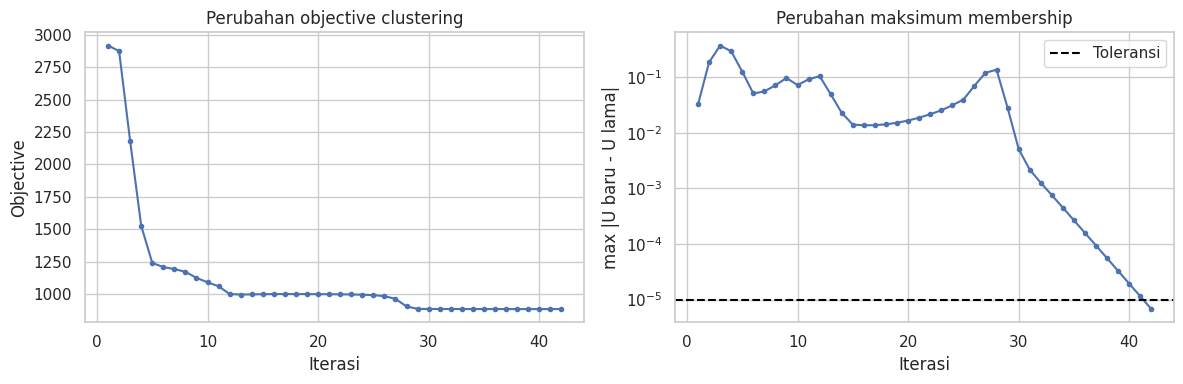

In [36]:
# 26A. Visualisasi proses konvergensi clustering final
history = final_fuzzy_model["cluster"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(np.arange(1, len(history["objective_history"])+1), history["objective_history"], marker="o", markersize=3)
axes[0].set_title("Perubahan objective clustering")
axes[0].set_xlabel("Iterasi")
axes[0].set_ylabel("Objective")
axes[1].semilogy(np.arange(1, len(history["delta_history"])+1), np.maximum(history["delta_history"], 1e-12), marker="o", markersize=3)
axes[1].axhline(1e-5, linestyle="--", color="black", label="Toleransi")
axes[1].set_title("Perubahan maksimum membership")
axes[1].set_xlabel("Iterasi")
axes[1].set_ylabel("max |U baru - U lama|")
axes[1].legend()
plt.tight_layout()
plt.show()

### Pembanding tambahan

**Random Forest dan Dummy Mean bukan komponen wajib dan bukan bagian dari sistem fuzzy utama.** Keduanya dipertahankan sebagai pembanding tambahan agar posisi model fuzzy dapat dibaca dengan lebih objektif.

- **Dummy Mean** adalah baseline naif: selalu memprediksi rata-rata target pada data development. Fungsinya memeriksa apakah model belajar lebih dari tebakan konstan. Pada target yang tidak seimbang, accuracy Dummy dapat terlihat tinggi hanya karena kelas mayoritas; karena itu Macro F1 dan balanced accuracy juga ditampilkan.
- **Random Forest Regressor** adalah benchmark machine learning non-fuzzy yang mempelajari hubungan sensor-target. Konfigurasinya ditetapkan sebagai pembanding praktis, bukan hasil pencarian hyperparameter terbaik.

Kedua pembanding dilatih pada development set (train+validation) dan diuji pada test yang sama dengan model fuzzy.

In [ ]:
# 27. Pembanding tambahan : Random Forest dan Dummy Mean

rf_baseline = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    max_features=0.8,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf_baseline.fit(
    X_dev_scaled,
    y_dev.to_numpy(dtype=float),
    sample_weight=final_sample_weights
)
test_pred_rf = rf_baseline.predict(X_test_scaled)

dummy_baseline = DummyRegressor(strategy="mean")
dummy_baseline.fit(
    X_dev_scaled,
    y_dev.to_numpy(dtype=float),
    sample_weight=final_sample_weights
)
test_pred_dummy = dummy_baseline.predict(X_test_scaled)

print("Baseline selesai dilatih.")

Baseline selesai dilatih.


In [ ]:
# 28. Evaluasi final pada test set

final_results = pd.DataFrame([
    {
        "model": f"{SELECTED_METHOD.upper()} + First-Order Sugeno",
        **evaluate_occupancy(y_test_array, test_pred_fuzzy_raw)
    },
    {
        "model": "Random Forest Regressor",
        **evaluate_occupancy(y_test_array, test_pred_rf)
    },
    {
        "model": "Dummy Mean Baseline",
        **evaluate_occupancy(y_test_array, test_pred_dummy)
    }
]).set_index("model")

display(final_results.round(5))

print(
    "Metrik MAE/RMSE raw menunjukkan keluaran matematis model sebelum batas fisik. "
    "Metrik bounded menunjukkan keluaran setelah dibatasi ke rentang okupansi 0-3. "
    "Keduanya dilaporkan agar post-processing tidak menyembunyikan perilaku model."
)

,MAE_raw,RMSE_raw,MAE_bounded,RMSE_bounded,Exact_Count_Accuracy,Macro_F1,Balanced_Accuracy,Within_1_Person,Out_of_range_rate_raw,Below_zero_rate_raw,Above_three_rate_raw,Mean_out_of_range_excess,Raw_prediction_min,Raw_prediction_max
model,,,,,,,,,,,,,,
GK + First-Order Sugeno,0.19114,0.50184,0.18890,0.50175,0.88209,0.67661,0.72574,0.94716,0.05675,0.05626,0.00049,0.00224,-0.05022,3.00157
Random Forest Regressor,0.06306,0.29745,0.06306,0.29745,0.96575,0.88513,0.88953,0.99070,0.00000,0.00000,0.00000,0.00000,0.00000,3.00000
Dummy Mean Baseline,0.66847,0.93336,0.66847,0.93336,0.81311,0.22423,0.25000,0.84149,0.00000,0.00000,0.00000,0.00000,0.39246,0.39246


Metrik MAE/RMSE raw menunjukkan keluaran matematis model sebelum batas fisik. Metrik bounded menunjukkan keluaran setelah dibatasi ke rentang okupansi 0–3. Keduanya dilaporkan agar post-processing tidak menyembunyikan perilaku model.


### Membaca pergeseran performa validation ke test

Validation digunakan untuk memilih konfigurasi, sehingga skor terbaik validation dapat cenderung optimistis karena beberapa kandidat telah dibandingkan di sana. Setelah konfigurasi dikunci, model fuzzy dilatih ulang pada gabungan train+validation dan dievaluasi pada test yang tidak dipakai untuk seleksi.

Perbandingan berikut menunjukkan **pergeseran skor validation–test**, bukan *generalization gap* yang sepenuhnya murni: model validation dilatih pada train, sedangkan model final test dilatih ulang pada train+validation. Selain itu, kedekatan temporal antar-blok masih menjadi keterbatasan protokol. Test tetap menjadi hasil evaluasi utama yang dilaporkan.

,metric,validation,test,test_minus_validation,direction
0,MAE raw,0.09622,0.19114,0.09492,lebih kecil lebih baik
1,MAE bounded,0.08552,0.18890,0.10339,lebih kecil lebih baik
2,RMSE raw,0.32930,0.50184,0.17254,lebih kecil lebih baik
3,RMSE bounded,0.30072,0.50175,0.20102,lebih kecil lebih baik
4,Macro F1,0.90580,0.67661,-0.22919,lebih besar lebih baik
5,Balanced accuracy,0.93311,0.72574,-0.20737,lebih besar lebih baik
6,Raw out-of-range rate,0.39387,0.05675,-0.33711,lebih kecil lebih baik


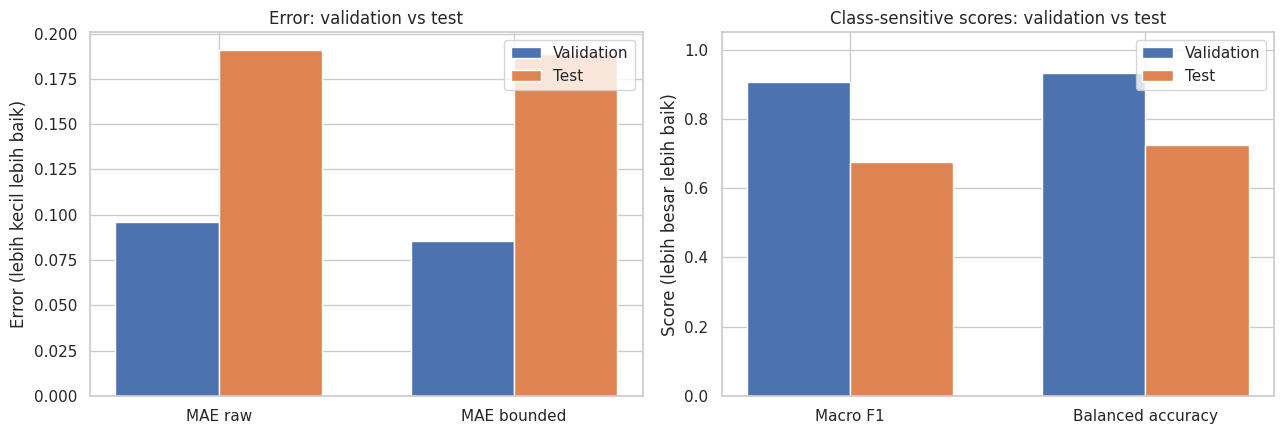

Catatan: validation score adalah hasil seleksi hyperparameter dan dapat optimistis. Test score adalah estimasi utama pada holdout yang tidak dipakai memilih model. Perbedaan keduanya tidak boleh langsung disebut overfitting tanpa mempertimbangkan perbedaan ukuran data latih final dan ketergantungan temporal antar-blok.


In [39]:
# 28B. Perbandingan validation dan test untuk konfigurasi fuzzy terpilih
fuzzy_test_name = f"{SELECTED_METHOD.upper()} + First-Order Sugeno"
fuzzy_test_metrics = final_results.loc[fuzzy_test_name]

comparison_specs = [
    ("MAE raw", "val_MAE_raw", "MAE_raw", "lebih kecil lebih baik"),
    ("MAE bounded", "val_MAE_bounded", "MAE_bounded", "lebih kecil lebih baik"),
    ("RMSE raw", "val_RMSE_raw", "RMSE_raw", "lebih kecil lebih baik"),
    ("RMSE bounded", "val_RMSE_bounded", "RMSE_bounded", "lebih kecil lebih baik"),
    ("Macro F1", "val_Macro_F1", "Macro_F1", "lebih besar lebih baik"),
    ("Balanced accuracy", "val_Balanced_Accuracy", "Balanced_Accuracy", "lebih besar lebih baik"),
    ("Raw out-of-range rate", "val_Out_of_range_rate_raw", "Out_of_range_rate_raw", "lebih kecil lebih baik")
]

validation_test_gap = pd.DataFrame([
    {
        "metric": label,
        "validation": float(best_alpha_row[val_key]),
        "test": float(fuzzy_test_metrics[test_key]),
        "test_minus_validation": float(fuzzy_test_metrics[test_key] - best_alpha_row[val_key]),
        "direction": direction
    }
    for label, val_key, test_key, direction in comparison_specs
])

display(validation_test_gap.round(5))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
error_rows = validation_test_gap[
    validation_test_gap["metric"].isin(["MAE raw", "MAE bounded"])
]
score_rows = validation_test_gap[
    validation_test_gap["metric"].isin(["Macro F1", "Balanced accuracy"])
]

x = np.arange(len(error_rows))
width = 0.35
axes[0].bar(x - width/2, error_rows["validation"], width, label="Validation")
axes[0].bar(x + width/2, error_rows["test"], width, label="Test")
axes[0].set_xticks(x)
axes[0].set_xticklabels(error_rows["metric"])
axes[0].set_title("Error: validation vs test")
axes[0].set_ylabel("Error (lebih kecil lebih baik)")
axes[0].legend()

x = np.arange(len(score_rows))
axes[1].bar(x - width/2, score_rows["validation"], width, label="Validation")
axes[1].bar(x + width/2, score_rows["test"], width, label="Test")
axes[1].set_xticks(x)
axes[1].set_xticklabels(score_rows["metric"])
axes[1].set_ylim(0, 1.05)
axes[1].set_title("Class-sensitive scores: validation vs test")
axes[1].set_ylabel("Score (lebih besar lebih baik)")
axes[1].legend()
plt.tight_layout()
plt.show()

print(
    "Catatan: validation score adalah hasil seleksi hyperparameter dan dapat optimistis. "
    "Test score adalah estimasi utama pada holdout yang tidak dipakai memilih model. "
    "Perbedaan keduanya tidak boleh langsung disebut overfitting tanpa mempertimbangkan "
    "perbedaan ukuran data latih final dan ketergantungan temporal antar-blok."
)

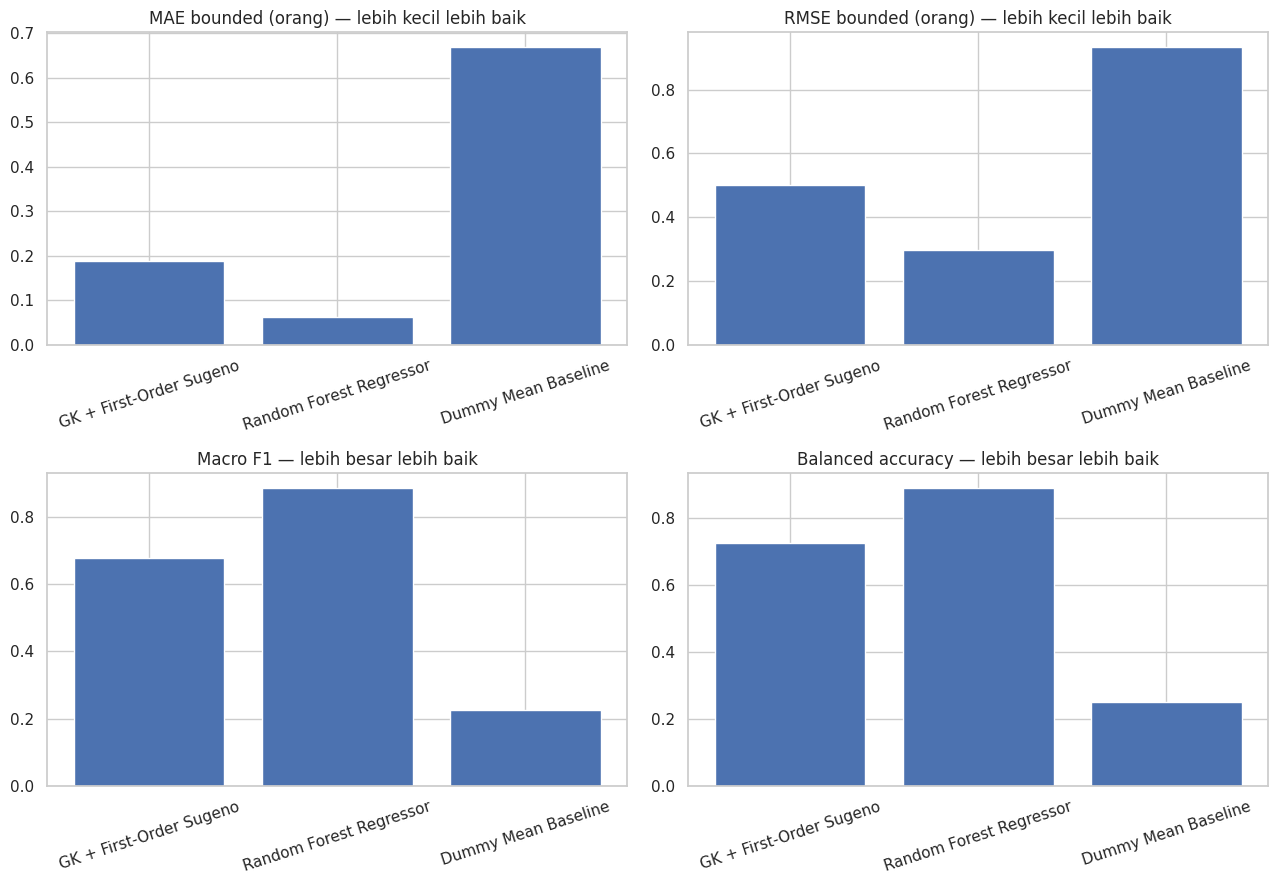

Laporan per kelas (fuzzy):


,precision,recall,f1-score,support
0,0.9816,0.9296,0.9549,1662.0
1,0.4070,0.6034,0.4861,58.0
2,0.5000,0.8193,0.6210,166.0
3,0.7768,0.5506,0.6444,158.0


In [40]:
# 28A. Visualisasi perbandingan model pada test set
metrics_for_plot = [
    ("MAE_bounded", "MAE bounded (orang) — lebih kecil lebih baik"),
    ("RMSE_bounded", "RMSE bounded (orang) — lebih kecil lebih baik"),
    ("Macro_F1", "Macro F1 — lebih besar lebih baik"),
    ("Balanced_Accuracy", "Balanced accuracy — lebih besar lebih baik"),
]
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (metric, title) in zip(axes.ravel(), metrics_for_plot):
    ax.bar(final_results.index.astype(str), final_results[metric].values)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=18)
plt.tight_layout()
plt.show()

# Per-class precision, recall, F1, dan support untuk model fuzzy.
class_report = pd.DataFrame(classification_report(
    y_test_array, fuzzy_count_pred if "fuzzy_count_pred" in globals() else to_count_prediction(test_pred_fuzzy_raw),
    labels=LABELS, output_dict=True, zero_division=0
)).T
print("Laporan per kelas (fuzzy):")
display(class_report.loc[[str(x) for x in LABELS]].round(4))

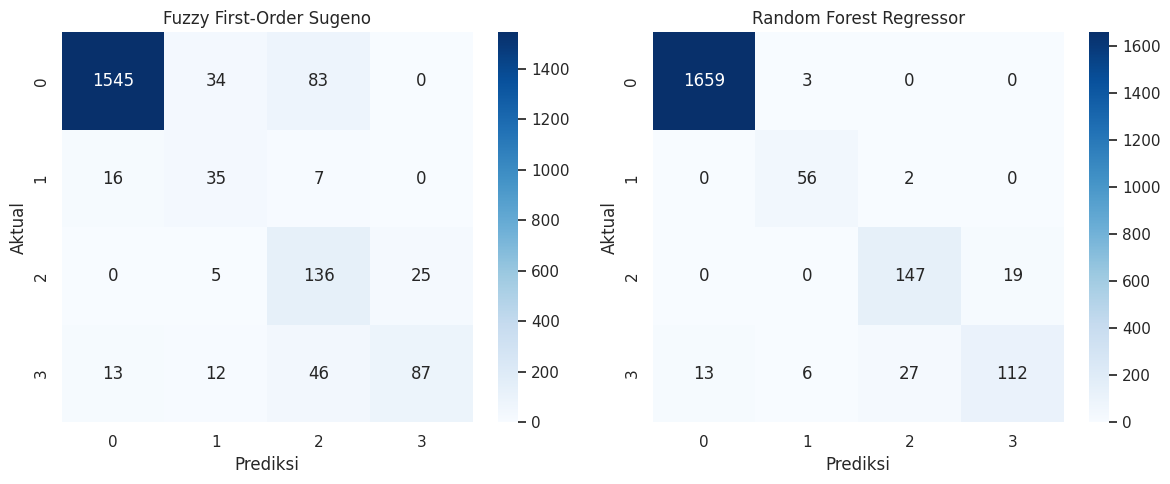

Classification report — Fuzzy Sugeno
              precision    recall  f1-score   support

           0       0.98      0.93      0.95      1662
           1       0.41      0.60      0.49        58
           2       0.50      0.82      0.62       166
           3       0.78      0.55      0.64       158

    accuracy                           0.88      2044
   macro avg       0.67      0.73      0.68      2044
weighted avg       0.91      0.88      0.89      2044



In [41]:
# 29. Confusion matrix dan classification report

fuzzy_count_pred = to_count_prediction(test_pred_fuzzy_raw)
rf_count_pred = to_count_prediction(test_pred_rf)
cm_fuzzy = confusion_matrix(y_test_array, fuzzy_count_pred, labels=LABELS)
cm_rf = confusion_matrix(y_test_array, rf_count_pred, labels=LABELS)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(
    cm_fuzzy, annot=True, fmt="d", cmap="Blues",
    xticklabels=LABELS, yticklabels=LABELS, ax=axes[0]
)
axes[0].set_title("Fuzzy First-Order Sugeno")
axes[0].set_xlabel("Prediksi")
axes[0].set_ylabel("Aktual")
sns.heatmap(
    cm_rf, annot=True, fmt="d", cmap="Blues",
    xticklabels=LABELS, yticklabels=LABELS, ax=axes[1]
)
axes[1].set_title("Random Forest Regressor")
axes[1].set_xlabel("Prediksi")
axes[1].set_ylabel("Aktual")
plt.tight_layout()
plt.show()

print("Classification report — Fuzzy Sugeno")
print(classification_report(
    y_test_array, fuzzy_count_pred, labels=LABELS, zero_division=0
))

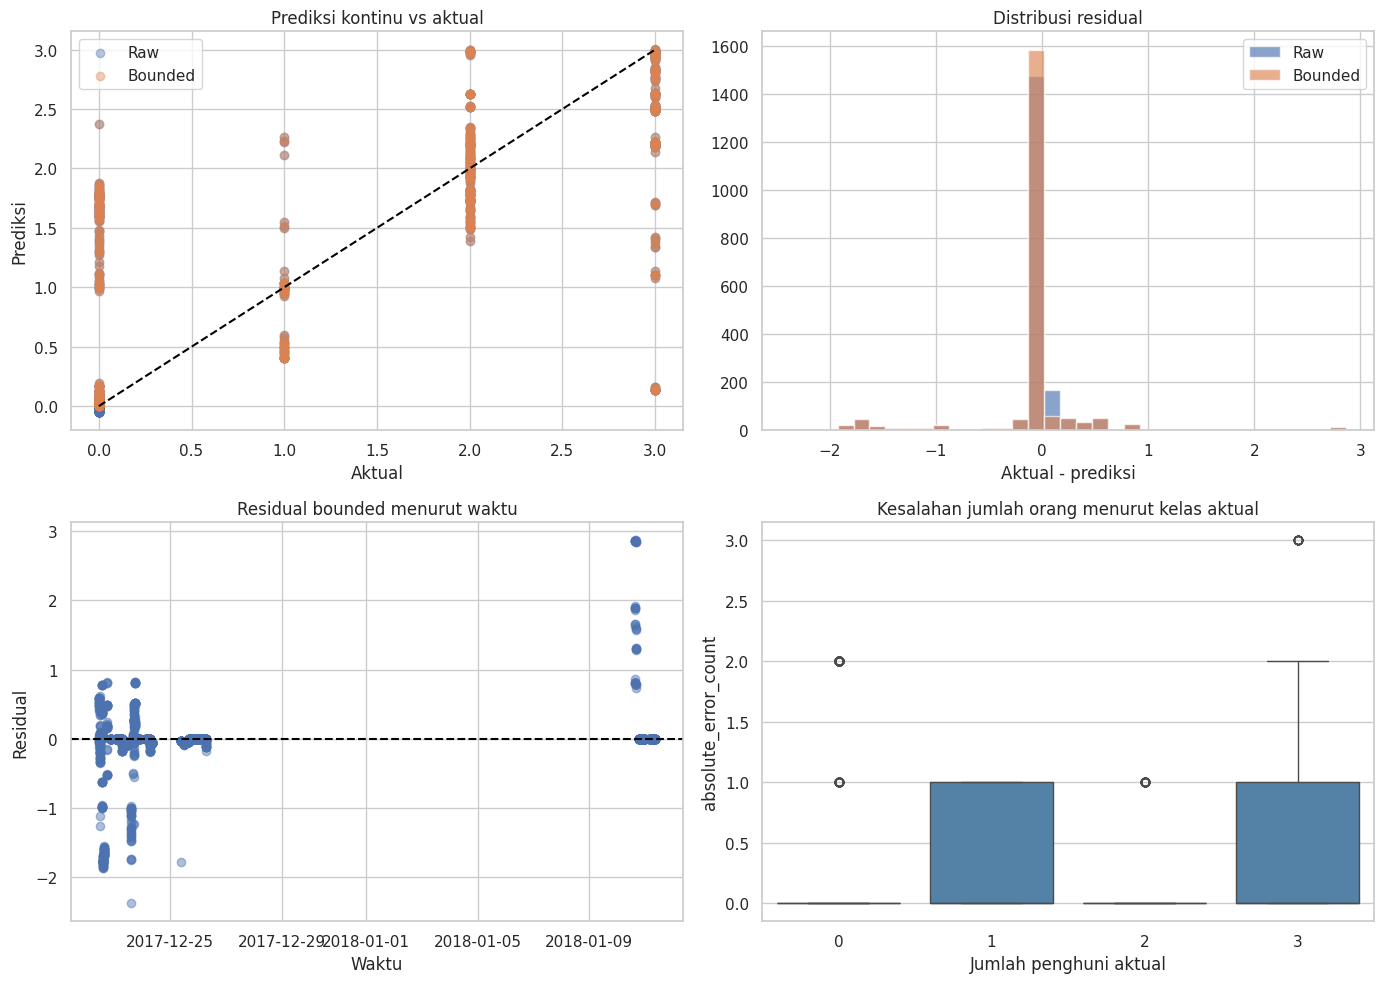

,timestamp,actual,predicted_raw,predicted_bounded,predicted_count,residual_raw,residual_bounded,absolute_error_count
1659,2018-01-10 15:26:49,3,0.137505,0.137505,0,2.862495,2.862495,3
1673,2018-01-10 15:33:58,3,0.133773,0.133773,0,2.866227,2.866227,3
1683,2018-01-10 15:39:04,3,0.133291,0.133291,0,2.866709,2.866709,3
1672,2018-01-10 15:33:28,3,0.136129,0.136129,0,2.863871,2.863871,3
1671,2018-01-10 15:32:57,3,0.136590,0.136590,0,2.863410,2.863410,3
1686,2018-01-10 15:40:36,3,0.162312,0.162312,0,2.837688,2.837688,3
1670,2018-01-10 15:32:26,3,0.137505,0.137505,0,2.862495,2.862495,3
1669,2018-01-10 15:31:56,3,0.137958,0.137958,0,2.862042,2.862042,3
1668,2018-01-10 15:31:25,3,0.137958,0.137958,0,2.862042,2.862042,3
1691,2018-01-10 15:43:10,3,0.154290,0.154290,0,2.845710,2.845710,3


In [42]:
# 30. Analisis residual dan kesalahan prediksi

test_result_df = pd.DataFrame({
    "timestamp": t_test.to_numpy(),
    "actual": y_test_array,
    "predicted_raw": test_pred_fuzzy_raw,
    "predicted_bounded": test_pred_fuzzy_bounded,
    "predicted_count": fuzzy_count_pred,
    "residual_raw": y_test_array - test_pred_fuzzy_raw,
    "residual_bounded": y_test_array - test_pred_fuzzy_bounded,
    "absolute_error_count": np.abs(y_test_array - fuzzy_count_pred)
})

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes[0, 0].scatter(test_result_df["actual"], test_result_df["predicted_raw"], alpha=0.4, label="Raw")
axes[0, 0].scatter(test_result_df["actual"], test_result_df["predicted_bounded"], alpha=0.4, label="Bounded")
axes[0, 0].plot([0, 3], [0, 3], linestyle="--", color="black")
axes[0, 0].set_title("Prediksi kontinu vs aktual")
axes[0, 0].set_xlabel("Aktual")
axes[0, 0].set_ylabel("Prediksi")
axes[0, 0].legend()

axes[0, 1].hist(test_result_df["residual_raw"], bins=35, alpha=0.65, label="Raw")
axes[0, 1].hist(test_result_df["residual_bounded"], bins=35, alpha=0.65, label="Bounded")
axes[0, 1].set_title("Distribusi residual")
axes[0, 1].set_xlabel("Aktual - prediksi")
axes[0, 1].legend()

axes[1, 0].scatter(test_result_df["timestamp"], test_result_df["residual_bounded"], alpha=0.45)
axes[1, 0].axhline(0, linestyle="--", color="black")
axes[1, 0].set_title("Residual bounded menurut waktu")
axes[1, 0].set_xlabel("Waktu")
axes[1, 0].set_ylabel("Residual")

sns.boxplot(data=test_result_df, x="actual", y="absolute_error_count", color="steelblue", ax=axes[1, 1])
axes[1, 1].set_title("Kesalahan jumlah orang menurut kelas aktual")
axes[1, 1].set_xlabel("Jumlah penghuni aktual")
plt.tight_layout()
plt.show()

display(test_result_df.sort_values("absolute_error_count", ascending=False).head(15))

### Diagnostik output Sugeno sebelum pembatasan fisik

Output Sugeno linear tidak otomatis terikat pada rentang target 0–3. Karena itu, clipping merupakan post-processing untuk mematuhi batas fisik, bukan bagian dari konsekuen linear itu sendiri. Kedua hasil harus dilaporkan agar clipping tidak menyamarkan perilaku model.

,indikator,nilai
0,Prediksi di bawah 0,0.056262
1,Prediksi di atas 3,0.000489
2,Total prediksi di luar rentang,0.056751
3,Rata-rata jarak di luar rentang (orang),0.002237
4,Nilai minimum prediksi raw,-0.050216
5,Nilai maksimum prediksi raw,3.001569


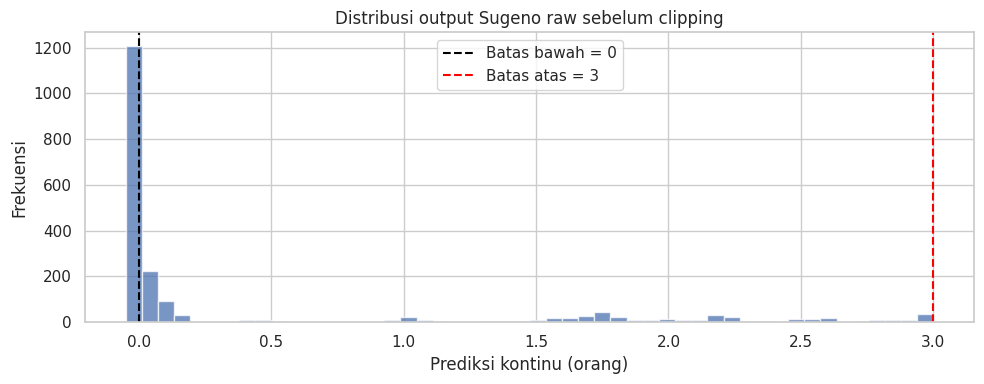

In [43]:
# 30A. Mengurai prediksi di luar rentang fisik
raw_below = test_pred_fuzzy_raw < 0
raw_above = test_pred_fuzzy_raw > 3
raw_excess = np.maximum(0, -test_pred_fuzzy_raw) + np.maximum(0, test_pred_fuzzy_raw - 3)
raw_diagnostic = pd.DataFrame({
    "indikator": [
        "Prediksi di bawah 0",
        "Prediksi di atas 3",
        "Total prediksi di luar rentang",
        "Rata-rata jarak di luar rentang (orang)",
        "Nilai minimum prediksi raw",
        "Nilai maksimum prediksi raw"
    ],
    "nilai": [
        float(raw_below.mean()), float(raw_above.mean()),
        float((raw_below | raw_above).mean()),
        float(raw_excess.mean()),
        float(test_pred_fuzzy_raw.min()), float(test_pred_fuzzy_raw.max())
    ]
})
display(raw_diagnostic)

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(test_pred_fuzzy_raw, bins=50, alpha=0.75)
ax.axvline(0, linestyle="--", color="black", label="Batas bawah = 0")
ax.axvline(3, linestyle="--", color="red", label="Batas atas = 3")
ax.set_title("Distribusi output Sugeno raw sebelum clipping")
ax.set_xlabel("Prediksi kontinu (orang)")
ax.set_ylabel("Frekuensi")
ax.legend()
plt.tight_layout()
plt.show()

if raw_diagnostic.loc[2, "nilai"] > 0.10:
    print(
        "Peringatan interpretasi: lebih dari 10% prediksi kontinu berada di luar "
        "rentang target. Bahas ini sebagai keterbatasan model; jangan hanya "
        "melaporkan metrik setelah clipping."
    )

## 10. Membaca cluster dan aturan yang terbentuk

Setiap cluster menjadi satu aturan Sugeno. Pusat cluster dan kovarians membentuk antecedent; parameter fungsi linear menjadi konsekuen.

Karena antecedent menggunakan region multivariat, interpretasinya bukan selalu kalimat sederhana seperti “CO₂ tinggi AND cahaya rendah”. Interpretasi yang aman adalah: pola input berada dekat dengan region fuzzy tertentu, lalu aturan tersebut memberikan estimasi lokal melalui fungsi linear.

Derajat keanggotaan bukan probabilitas. Nilainya menyatakan tingkat kecocokan relatif suatu observasi terhadap cluster; untuk setiap observasi, membership antar-cluster dijumlahkan menjadi satu.

In [44]:
# 31. Membership matrix, pusat cluster, dan kovarians

U_joint = final_fuzzy_model["cluster"]["U"]
U_antecedent = final_fuzzy_model["U_antecedent_train"]
rule_names = [f"R{i+1}" for i in range(SELECTED_C)]

print("A. Membership product-space [input, target] untuk evaluasi partisi:")
display(pd.DataFrame(
    U_joint[:, :15].T, columns=rule_names
).rename_axis("observasi_development").round(5))

print("B. Membership antecedent input-space yang dipakai WLS dan inferensi:")
display(pd.DataFrame(
    U_antecedent[:15], columns=rule_names
).rename_axis("observasi_development").round(5))

membership_summary = pd.DataFrame({
    "joint_mean_membership": U_joint.mean(axis=1),
    "joint_membership_mass": U_joint.sum(axis=1),
    "antecedent_mean_activation": U_antecedent.mean(axis=0),
    "antecedent_min_activation": U_antecedent.min(axis=0),
    "antecedent_max_activation": U_antecedent.max(axis=0)
}, index=rule_names)
display(membership_summary.round(5))

joint_names = selected_columns + ["target_scaled"]
print("Pusat cluster pada ruang gabungan terstandarisasi:")
display(pd.DataFrame(
    final_fuzzy_model["cluster"]["centers"],
    index=rule_names, columns=joint_names
).round(4))

for i, rule_name in enumerate(rule_names):
    print(f"Kovarians product-space {rule_name}:")
    display(pd.DataFrame(
        final_fuzzy_model["cluster"]["covariances"][i],
        index=joint_names, columns=joint_names
    ).round(4))
    eigvals = np.linalg.eigvalsh(final_fuzzy_model["cluster"]["covariances"][i])
    print(
        "Eigenvalue minimum:", float(eigvals.min()),
        "| condition number:", float(np.linalg.cond(
            final_fuzzy_model["cluster"]["covariances"][i]
        ))
    )

A. Membership product-space [input, target] untuk evaluasi partisi:


,R1,R2,R3,R4
observasi_development,,,,
0,0.00719,0.97839,0.00887,0.00555
1,0.00702,0.97889,0.00867,0.00542
2,0.00702,0.97889,0.00867,0.00542
3,0.01537,0.52203,0.44890,0.01369
4,0.01633,0.96923,0.00520,0.00924
5,0.01624,0.96941,0.00517,0.00918
6,0.00691,0.97923,0.00852,0.00533
7,0.00705,0.97884,0.00869,0.00543
8,0.01613,0.96960,0.00514,0.00912


B. Membership antecedent input-space yang dipakai WLS dan inferensi:


,R1,R2,R3,R4
observasi_development,,,,
0,0.15303,0.84697,0.00000,0.0
1,0.16238,0.83762,0.00000,0.0
2,0.16238,0.83762,0.00000,0.0
3,0.16919,0.77139,0.05942,0.0
4,0.28082,0.71918,0.00000,0.0
5,0.29252,0.70748,0.00000,0.0
6,0.19216,0.80784,0.00000,0.0
7,0.19232,0.80768,0.00000,0.0
8,0.29269,0.70731,0.00000,0.0


,joint_mean_membership,joint_membership_mass,antecedent_mean_activation,antecedent_min_activation,antecedent_max_activation
R1,0.05793,468.40028,0.10445,0.0,1.00000
R2,0.09576,774.24391,0.08098,0.0,0.99903
R3,0.26619,2152.17348,0.24715,0.0,0.99855
R4,0.58011,4690.18233,0.56742,0.0,1.00000


Pusat cluster pada ruang gabungan terstandarisasi:


... (6 outputs left out)

,light_mean_log,co2_log,pir_active_count,target_scaled
light_mean_log,0.0404,0.0664,-0.0000,0.0461
co2_log,0.0664,0.5318,0.0003,0.2204
pir_active_count,-0.0000,0.0003,0.0019,0.0002
target_scaled,0.0461,0.2204,0.0002,0.2001


Eigenvalue minimum: 0.0019312176754862859 | condition number: 337.7499898469896
Kovarians product-space R4:


,light_mean_log,co2_log,pir_active_count,target_scaled
light_mean_log,0.0026,0.0001,0.0000,0.0000
co2_log,0.0001,1.0266,0.0015,0.0002
pir_active_count,0.0000,0.0015,0.0026,0.0000
target_scaled,0.0000,0.0002,0.0000,0.0026


Eigenvalue minimum: 0.002574306578763516 | condition number: 398.7757538018234


### Perhitungan clustering satu observasi: dari jarak ke membership

Tabel berikut mengambil satu pasangan input–target dari development set dan menampilkan jarak kuadratnya ke setiap prototype. Dari jarak tersebut, algoritma menghitung membership menggunakan rumus FCM/GK. Ini membuat proses iteratif tidak hanya terlihat sebagai nama algoritma, tetapi dapat ditelusuri secara numerik.

,rule,distance_squared,membership_recomputed,membership_stored,membership_power_m
0,R1,28.126985,0.007395,0.007395,0.000055
1,R2,0.212729,0.977811,0.977811,0.956114
2,R3,22.838640,0.009108,0.009108,0.000083
3,R4,36.584329,0.005686,0.005686,0.000032


Jumlah membership: 1.0
Selisih maksimum membership hasil hitung ulang: 1.3624234751485886e-07
Pemeriksaan pusat cluster R1, dimensi pertama:
Hasil rumus manual: 1.263738481000476
Pusat dari model  : 1.263738481000476
Selisih absolut   : 0.0


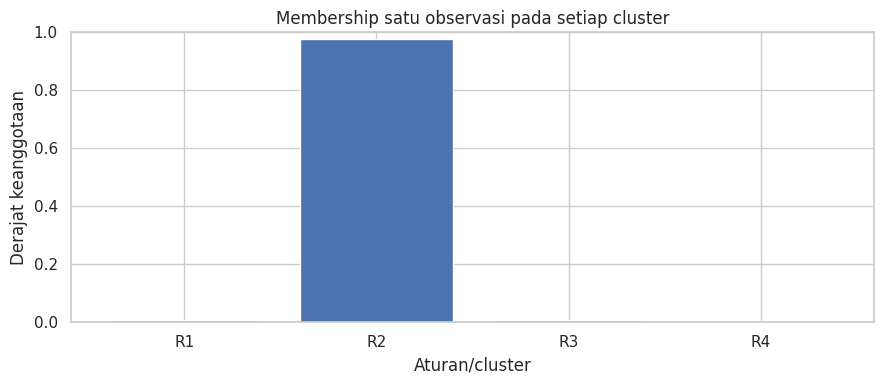

In [45]:
# 31C. Trace numerik satu observasi pada ruang product-space
Z_dev_scaled = np.column_stack([X_dev_scaled, y_dev_scaled])
trace_idx = min(25, len(Z_dev_scaled) - 1)
trace_z = Z_dev_scaled[trace_idx:trace_idx + 1]
cluster_final = final_fuzzy_model["cluster"]

if SELECTED_METHOD == "gk":
    trace_D2 = distances_mahalanobis_squared(
        trace_z, cluster_final["centers"], cluster_final["matrices"]
    )[:, 0]
else:
    trace_D2 = distances_euclidean_squared(
        trace_z, cluster_final["centers"]
    )[:, 0]
trace_U_recomputed = membership_from_distances(
    trace_D2.reshape(-1, 1), m=SELECTED_M
)[:, 0]
trace_U_stored = cluster_final["U"][:, trace_idx]

trace_table = pd.DataFrame({
    "rule": rule_names,
    "distance_squared": trace_D2,
    "membership_recomputed": trace_U_recomputed,
    "membership_stored": trace_U_stored,
    "membership_power_m": trace_U_stored ** SELECTED_M
})
display(trace_table.round(7))
print("Jumlah membership:", float(trace_U_stored.sum()))
print("Selisih maksimum membership hasil hitung ulang:",
      float(np.max(np.abs(trace_U_recomputed - trace_U_stored))))

# Verifikasi satu komponen pusat cluster dari rumus weighted fuzzy mean.
rule_idx_trace = 0
feature_idx_trace = 0
cluster_weights_trace = (
    cluster_final["U"][rule_idx_trace] ** SELECTED_M
) * final_sample_weights
manual_center_component = np.sum(
    cluster_weights_trace * Z_dev_scaled[:, feature_idx_trace]
) / np.sum(cluster_weights_trace)
center_component_model = cluster_final["centers"][rule_idx_trace, feature_idx_trace]
print("Pemeriksaan pusat cluster R1, dimensi pertama:")
print("Hasil rumus manual:", manual_center_component)
print("Pusat dari model  :", center_component_model)
print("Selisih absolut   :", abs(manual_center_component - center_component_model))
assert np.isclose(manual_center_component, center_component_model, atol=1e-7)

plt.figure(figsize=(9, 4))
plt.bar(trace_table["rule"], trace_table["membership_stored"])
plt.ylim(0, 1)
plt.title("Membership satu observasi pada setiap cluster")
plt.xlabel("Aturan/cluster")
plt.ylabel("Derajat keanggotaan")
plt.tight_layout()
plt.show()

### Membaca bentuk cluster dan tingkat tumpang tindih membership

Karena cluster terbentuk pada ruang input–output berdimensi lebih dari dua, visualisasi berikut menggunakan PCA untuk memproyeksikan data training ke dua dimensi. PCA hanya alat visualisasi; ia tidak mengubah model yang dilatih.

Heatmap membership memperlihatkan apakah observasi cenderung memiliki satu aturan dominan atau terbagi di beberapa aturan. Entropy yang tinggi berarti membership lebih tersebar, bukan berarti prediksi pasti salah.

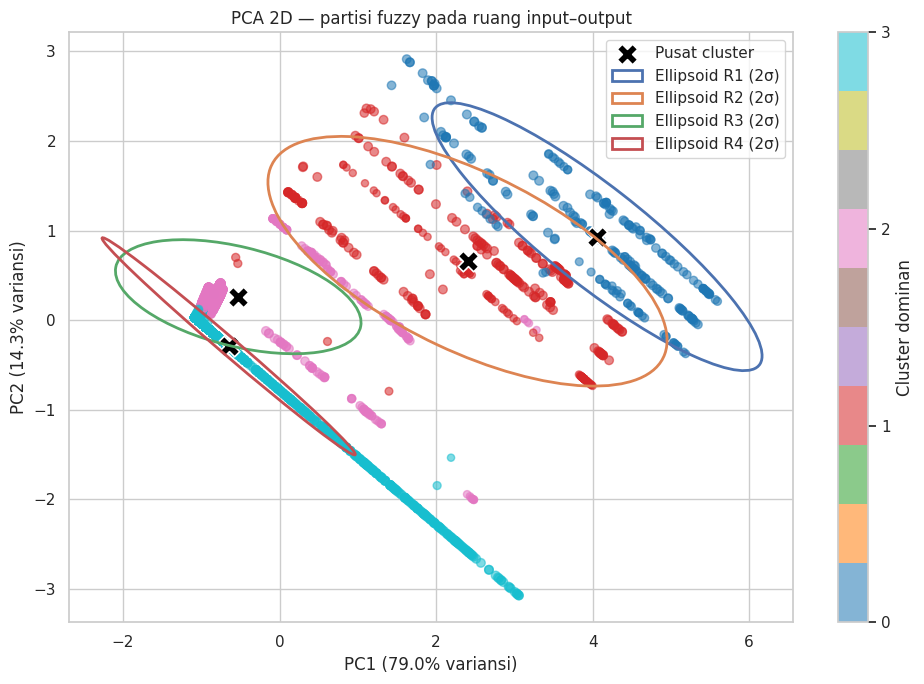

Total variansi yang dijelaskan dua komponen: 93.28 %


In [46]:
# 31A. PCA 2D untuk memvisualisasikan partisi fuzzy product-space
from sklearn.decomposition import PCA
from matplotlib.patches import Ellipse

Z_dev_scaled = np.column_stack([X_dev_scaled, y_dev_scaled])
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
Z_pca = pca_2d.fit_transform(Z_dev_scaled)
centers_pca = pca_2d.transform(final_fuzzy_model["cluster"]["centers"])
dominant_cluster = np.argmax(U_joint, axis=0)
max_membership = U_joint.max(axis=0)

rng_plot = np.random.default_rng(RANDOM_STATE)
plot_n = min(3500, len(Z_pca))
plot_ids = np.sort(rng_plot.choice(len(Z_pca), size=plot_n, replace=False))

plt.figure(figsize=(10, 7))
scatter = plt.scatter(
    Z_pca[plot_ids, 0], Z_pca[plot_ids, 1],
    c=dominant_cluster[plot_ids],
    s=12 + 28 * max_membership[plot_ids],
    alpha=0.55, cmap="tab10"
)
plt.scatter(
    centers_pca[:, 0], centers_pca[:, 1],
    marker="X", s=220, c="black", edgecolor="white", linewidth=1.2,
    label="Pusat cluster"
)

# Ellipse 2-sigma dari covariance cluster yang diproyeksikan ke bidang PCA.
for i in range(SELECTED_C):
    cov_pca = pca_2d.components_ @ final_fuzzy_model["cluster"]["covariances"][i] @ pca_2d.components_.T
    eigvals, eigvecs = np.linalg.eigh((cov_pca + cov_pca.T) / 2.0)
    order_eig = np.argsort(eigvals)[::-1]
    eigvals = np.maximum(eigvals[order_eig], 1e-8)
    eigvecs = eigvecs[:, order_eig]
    angle = np.degrees(np.arctan2(eigvecs[1, 0], eigvecs[0, 0]))
    ellipse = Ellipse(
        xy=centers_pca[i],
        width=4 * np.sqrt(eigvals[0]),
        height=4 * np.sqrt(eigvals[1]),
        angle=angle, fill=False, linewidth=2,
        edgecolor=f"C{i}", label=f"Ellipsoid R{i+1} (2σ)"
    )
    ax = plt.gca()
    ax.add_patch(ellipse)
plt.colorbar(scatter, ticks=list(range(SELECTED_C)), label="Cluster dominan")
plt.title("PCA 2D — partisi fuzzy pada ruang input–output")
plt.xlabel(f"PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% variansi)")
plt.ylabel(f"PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% variansi)")
plt.legend()
plt.tight_layout()
plt.show()

print("Total variansi yang dijelaskan dua komponen:",
      round(float(pca_2d.explained_variance_ratio_.sum() * 100), 2), "%")

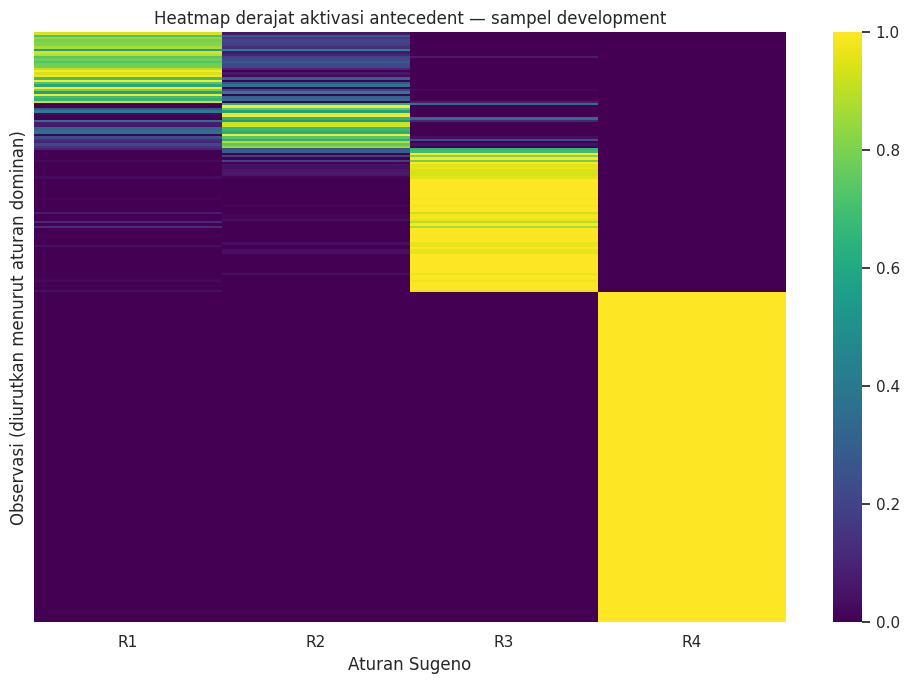

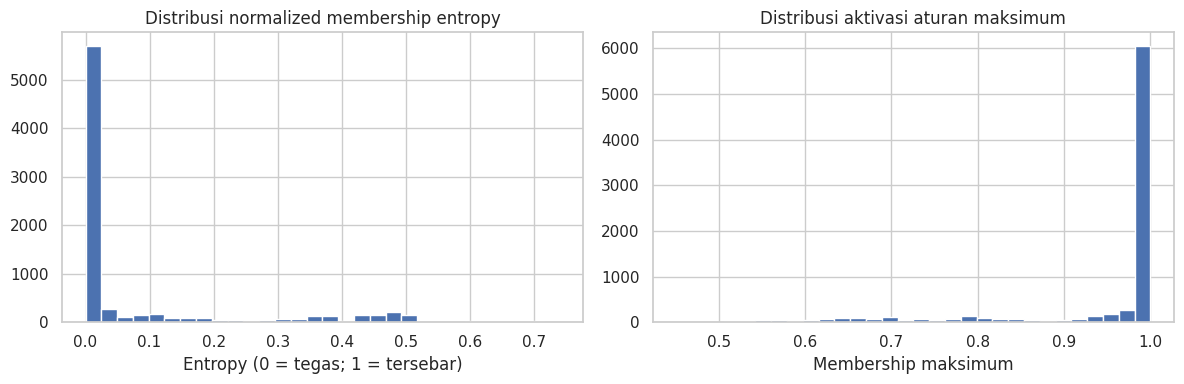

In [47]:
# 31B. Heatmap membership antecedent untuk sampel development
heat_n = min(250, len(U_antecedent))
heat_ids = np.linspace(0, len(U_antecedent)-1, heat_n, dtype=int)
order = np.argsort(np.argmax(U_antecedent[heat_ids], axis=1))
heat_matrix = U_antecedent[heat_ids][order]

plt.figure(figsize=(10, 7))
sns.heatmap(
    heat_matrix, cmap="viridis", vmin=0, vmax=1,
    xticklabels=rule_names, yticklabels=False
)
plt.title("Heatmap derajat aktivasi antecedent — sampel development")
plt.xlabel("Aturan Sugeno")
plt.ylabel("Observasi (diurutkan menurut aturan dominan)")
plt.tight_layout()
plt.show()

entropy = -np.sum(
    U_antecedent * np.log(np.maximum(U_antecedent, 1e-12)), axis=1
) / np.log(SELECTED_C)
max_activation = U_antecedent.max(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(entropy, bins=30)
axes[0].set_title("Distribusi normalized membership entropy")
axes[0].set_xlabel("Entropy (0 = tegas; 1 = tersebar)")
axes[1].hist(max_activation, bins=30)
axes[1].set_title("Distribusi aktivasi aturan maksimum")
axes[1].set_xlabel("Membership maksimum")
plt.tight_layout()
plt.show()

In [48]:
# 32. Mengubah pusat cluster dan koefisien Sugeno ke skala fitur yang dapat dibaca

def consequent_to_original_units(theta_scaled, x_scaler, y_scaler):
    theta_scaled = np.asarray(theta_scaled, dtype=float)
    slopes_scaled = theta_scaled[:-1]
    intercept_scaled = theta_scaled[-1]
    y_mean = float(y_scaler.mean_[0])
    y_scale = float(y_scaler.scale_[0])
    slopes_raw = y_scale * slopes_scaled / x_scaler.scale_
    intercept_raw = y_mean + y_scale * intercept_scaled - np.sum(slopes_raw * x_scaler.center_)
    return slopes_raw, intercept_raw


def inverse_feature_transform(feature_name, value):
    if feature_name in {
        "light_mean_log", "light_std_log",
        "sound_mean_log", "sound_std_log", "co2_log"
    }:
        return float(np.expm1(value))
    return float(value)


centers_x_engineered = x_scaler_final.inverse_transform(final_fuzzy_model["centers_x"])
target_centers_original = y_scaler_final.inverse_transform(
    final_fuzzy_model["cluster"]["centers"][:, -1].reshape(-1, 1)
).ravel()

rule_profile = pd.DataFrame(centers_x_engineered, columns=selected_columns)
rule_profile.insert(0, "rule", rule_names)
rule_profile["cluster_target_center"] = target_centers_original

# Tambahkan kolom dengan satuan sensor yang lebih mudah dibaca.
readable_columns = {}
for feature in selected_columns:
    if feature == "light_mean_log":
        readable_columns["light_mean_lux"] = np.expm1(rule_profile[feature])
    elif feature == "light_std_log":
        readable_columns["light_std_lux"] = np.expm1(rule_profile[feature])
    elif feature == "sound_mean_log":
        readable_columns["sound_mean_volt"] = np.expm1(rule_profile[feature])
    elif feature == "sound_std_log":
        readable_columns["sound_std_volt"] = np.expm1(rule_profile[feature])
    elif feature == "co2_log":
        readable_columns["co2_ppm"] = np.expm1(rule_profile[feature])
    else:
        readable_columns[feature] = rule_profile[feature].astype(float)
for name, values in readable_columns.items():
    rule_profile[name] = values

consequent_rows = []
for i, theta in enumerate(final_fuzzy_model["consequents"]):
    slopes, intercept = consequent_to_original_units(theta, x_scaler_final, y_scaler_final)
    row = {"rule": rule_names[i], "intercept": intercept}
    row.update(dict(zip(selected_columns, slopes)))
    consequent_rows.append(row)
rule_consequents = pd.DataFrame(consequent_rows)

print("Profil pusat cluster — kolom *_log adalah skala log; kolom satuan asli ditambahkan bila relevan:")
display(rule_profile.round(4))
print("Koefisien consequent linear (terhadap fitur hasil feature engineering):")
display(rule_consequents.round(5))

# Deskripsi relatif cluster berdasarkan sebaran fitur development; ini label naratif, bukan MF tambahan.
descriptions = []
for i, row in enumerate(centers_x_engineered):
    pieces = []
    for j, feature in enumerate(selected_columns):
        q_low = X_dev_raw[feature].quantile(1/3)
        q_high = X_dev_raw[feature].quantile(2/3)
        value = row[j]
        if feature == "pir_active_count":
            label = {0: "tidak ada PIR aktif", 1: "satu PIR aktif", 2: "dua PIR aktif"}.get(int(round(value)), "PIR campuran")
        else:
            label = "relatif rendah" if value <= q_low else ("relatif tinggi" if value >= q_high else "relatif sedang")
        pieces.append(f"{feature}: {label}")
    descriptions.append("; ".join(pieces))
rule_profile["profil_deskriptif_relatively"] = descriptions
print("Profil deskriptif aturan (berdasarkan kuantil development, bukan label linguistik formal):")
display(rule_profile[["rule", "profil_deskriptif_relatively", "cluster_target_center"]])

# Tabel rule base untuk laporan: IF x berada pada region fuzzy R_i THEN consequent linear.
rule_base_rows = []
for i, row in rule_consequents.iterrows():
    terms = [f"({row[feature]:+.5f})*{feature}" for feature in selected_columns]
    consequent_expression = f"{row['intercept']:+.5f} " + " ".join(terms)
    rule_base_rows.append({
        "rule": row["rule"],
        "antecedent": f"x berada pada region fuzzy multivariat {row['rule']}",
        "profil_deskriptif": descriptions[i],
        "consequent_linear": f"f_{row['rule']}(x) = {consequent_expression}"
    })
rule_base_table = pd.DataFrame(rule_base_rows)
print("Rule base First-Order Sugeno (identitas cluster + profil + consequent):")
display(rule_base_table)

Profil pusat cluster — kolom *_log adalah skala log; kolom satuan asli ditambahkan bila relevan:


,rule,light_mean_log,co2_log,pir_active_count,cluster_target_center,light_mean_lux,co2_ppm
0,R1,4.3191,6.7233,1.2594,2.9994,74.1219,830.5442
1,R2,4.5131,6.4519,1.1190,1.7266,90.2072,632.8820
2,R3,3.1397,5.9365,0.0002,0.1207,22.0958,377.6072
3,R4,0.0137,5.9801,0.0009,0.0001,0.0138,394.4667


Koefisien consequent linear (terhadap fitur hasil feature engineering):


,rule,intercept,light_mean_log,co2_log,pir_active_count
0,R1,-1.65145,0.14573,0.44891,0.4103
1,R2,-8.87599,1.21774,0.78083,0.0951
2,R3,-12.13550,0.05910,2.04050,0.0000
3,R4,0.00000,-0.00000,-0.00000,-0.0000


Profil deskriptif aturan (berdasarkan kuantil development, bukan label linguistik formal):


,rule,profil_deskriptif_relatively,cluster_target_center
0,R1,light_mean_log: relatif tinggi; co2_log: relat...,2.999443
1,R2,light_mean_log: relatif tinggi; co2_log: relat...,1.726588
2,R3,light_mean_log: relatif tinggi; co2_log: relat...,0.120680
3,R4,light_mean_log: relatif sedang; co2_log: relat...,0.000112


Rule base First-Order Sugeno (identitas cluster + profil + consequent):


,rule,antecedent,profil_deskriptif,consequent_linear
0,R1,x berada pada region fuzzy multivariat R1,light_mean_log: relatif tinggi; co2_log: relat...,f_R1(x) = -1.65145 (+0.14573)*light_mean_log (...
1,R2,x berada pada region fuzzy multivariat R2,light_mean_log: relatif tinggi; co2_log: relat...,f_R2(x) = -8.87599 (+1.21774)*light_mean_log (...
2,R3,x berada pada region fuzzy multivariat R3,light_mean_log: relatif tinggi; co2_log: relat...,f_R3(x) = -12.13550 (+0.05910)*light_mean_log ...
3,R4,x berada pada region fuzzy multivariat R4,light_mean_log: relatif sedang; co2_log: relat...,f_R4(x) = +0.00000 (-0.00000)*light_mean_log (...


### Audit estimasi consequent: menghitung ulang Weighted Ridge Least Squares untuk seluruh aturan

Untuk setiap aturan, consequent berbentuk \(f_i(x)=b_i+a_i^Tx\). Parameter diperoleh dari matriks desain \(\Phi=[X,1]\) dan bobot \(w_{ik}=u_{ik}^{m}\times s_k\), dengan \(s_k\) bobot sampel (none atau sqrt-balanced). Intercept tidak dikenai penalti ridge.

Cell berikut menghitung ulang solusi *augmented weighted least squares* untuk **setiap aturan**, lalu membandingkannya dengan koefisien yang disimpan model. Selain selisih koefisien, audit menampilkan effective sample size, rank sistem augmented, singular value minimum, condition number normal matrix, dan condition number augmented design.

Condition number normal matrix tetap berguna sebagai indikator sensitivitas fitur, tetapi model diselesaikan melalui augmented least squares. Karena itu, condition number normal matrix bukan bukti bahwa solver secara langsung menginvers matriks tersebut.

Audit ringkasan untuk seluruh aturan:


,rule,effective_weight_sum,effective_sample_size,augmented_design_rank,expected_rank,minimum_singular_value_augmented,condition_number_augmented_design,condition_number_normal_matrix,maximum_absolute_parameter_difference,solver
0,R1,612.663645,916.130629,4,4,4.251526,23.296234,5.427145e+02,0.0,augmented_lstsq
1,R2,385.260565,641.760822,4,4,1.279696,40.141054,1.611304e+03,0.0,augmented_lstsq
2,R3,1892.369411,2018.975972,4,4,0.010000,5804.899712,3.369686e+07,0.0,augmented_lstsq
3,R4,4584.045525,4586.580001,4,4,0.010000,8341.174775,6.957520e+07,0.0,augmented_lstsq


Audit parameter per aturan:


,rule,parameter,theta_manual,theta_model,absolute_difference
0,R1,light_mean_log,0.563899,0.563899,0.0
1,R1,co2_log,0.125818,0.125818,0.0
2,R1,pir_active_count,0.464515,0.464515,0.0
3,R1,intercept,0.678883,0.678883,0.0
4,R2,light_mean_log,4.711896,4.711896,0.0
5,R2,co2_log,0.218848,0.218848,0.0
6,R2,pir_active_count,0.107669,0.107669,0.0
7,R2,intercept,-5.287416,-5.287416,0.0
8,R3,light_mean_log,0.228685,0.228685,0.0
9,R3,co2_log,0.571906,0.571906,0.0


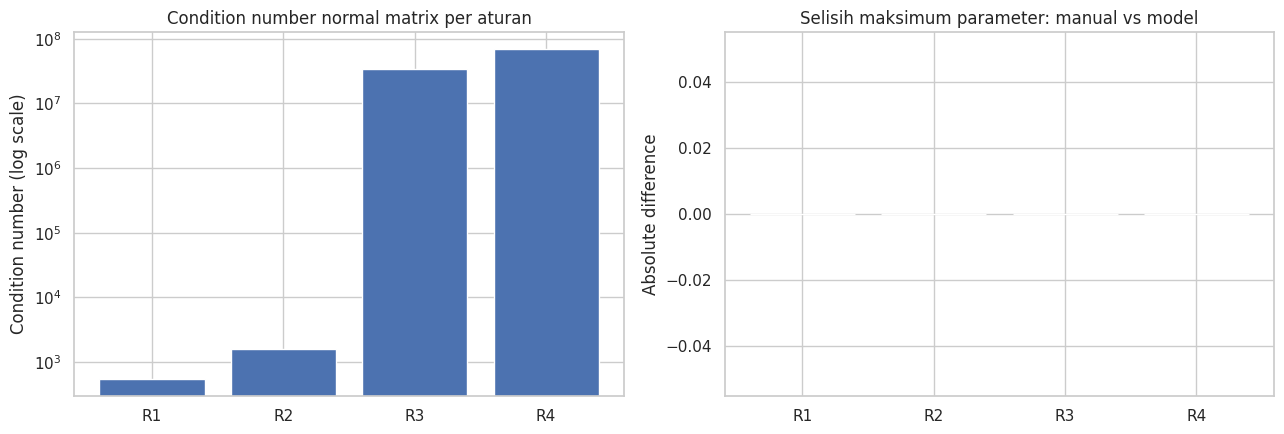

LULUS: semua consequent dapat direproduksi dengan augmented WLS dan selisih parameter berada dalam toleransi numerik. Condition number tinggi tetap perlu dibahas sebagai indikasi sensitivitas, bukan disembunyikan.


In [49]:
# 32A. Audit numerik augmented Weighted Ridge Least Squares untuk seluruh aturan
Phi_dev = np.column_stack([X_dev_scaled, np.ones(len(X_dev_scaled))])
R_penalty = np.eye(Phi_dev.shape[1]) * SELECTED_RIDGE_ALPHA
R_penalty[-1, -1] = 0.0  # intercept tidak dikenai penalti
penalty_sqrt = np.diag(np.sqrt(np.diag(R_penalty)))

wls_audit_summary_rows = []
wls_audit_coefficient_rows = []
manual_theta_all = []

for rule_audit in range(SELECTED_C):
    weights_audit = (
        final_fuzzy_model["U_antecedent_train"][:, rule_audit] ** SELECTED_M
    ) * final_sample_weights
    sqrt_weights_audit = np.sqrt(np.maximum(weights_audit, 0.0))
    Phi_weighted_audit = Phi_dev * sqrt_weights_audit[:, None]
    y_weighted_audit = y_dev_scaled * sqrt_weights_audit

    augmented_design_audit = np.vstack([
        Phi_weighted_audit,
        penalty_sqrt
    ])
    augmented_target_audit = np.concatenate([
        y_weighted_audit,
        np.zeros(Phi_dev.shape[1], dtype=float)
    ])

    theta_manual, residuals_audit, rank_audit, singular_values_audit = np.linalg.lstsq(
        augmented_design_audit,
        augmented_target_audit,
        rcond=None
    )
    theta_model = final_fuzzy_model["consequents"][rule_audit]
    parameter_differences = np.abs(theta_manual - theta_model)
    manual_theta_all.append(theta_manual)

    normal_matrix_audit = (
        Phi_weighted_audit.T @ Phi_weighted_audit + R_penalty
    )
    effective_sample_size = float(
        weights_audit.sum() ** 2 / np.sum(weights_audit ** 2)
    )

    wls_audit_summary_rows.append({
        "rule": f"R{rule_audit + 1}",
        "effective_weight_sum": float(weights_audit.sum()),
        "effective_sample_size": effective_sample_size,
        "augmented_design_rank": int(rank_audit),
        "expected_rank": int(Phi_dev.shape[1]),
        "minimum_singular_value_augmented": float(singular_values_audit.min()),
        "condition_number_augmented_design": float(np.linalg.cond(augmented_design_audit)),
        "condition_number_normal_matrix": float(np.linalg.cond(normal_matrix_audit)),
        "maximum_absolute_parameter_difference": float(parameter_differences.max()),
        "solver": "augmented_lstsq"
    })

    for parameter_name, manual_value, model_value, difference in zip(
        selected_columns + ["intercept"],
        theta_manual, theta_model, parameter_differences
    ):
        wls_audit_coefficient_rows.append({
            "rule": f"R{rule_audit + 1}",
            "parameter": parameter_name,
            "theta_manual": float(manual_value),
            "theta_model": float(model_value),
            "absolute_difference": float(difference)
        })

wls_audit_summary = pd.DataFrame(wls_audit_summary_rows)
wls_audit_coefficients = pd.DataFrame(wls_audit_coefficient_rows)
manual_theta_all = np.vstack(manual_theta_all)

print("Audit ringkasan untuk seluruh aturan:")
display(wls_audit_summary.round(8))
print("Audit parameter per aturan:")
display(wls_audit_coefficients.round(10))

# Verifikasi bahwa perhitungan ulang menghasilkan semua consequent yang sama.
assert manual_theta_all.shape == final_fuzzy_model["consequents"].shape
assert np.allclose(
    manual_theta_all,
    final_fuzzy_model["consequents"],
    atol=1e-7,
    rtol=1e-7
), "Audit WLS tidak cocok untuk setidaknya satu aturan."
assert (wls_audit_summary["augmented_design_rank"] == wls_audit_summary["expected_rank"]).all(), (
    "Ada sistem augmented yang tidak full column rank. Periksa fitur atau regularisasi."
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(
    wls_audit_summary["rule"],
    wls_audit_summary["condition_number_normal_matrix"]
)
axes[0].set_yscale("log")
axes[0].set_title("Condition number normal matrix per aturan")
axes[0].set_ylabel("Condition number (log scale)")
axes[1].bar(
    wls_audit_summary["rule"],
    wls_audit_summary["maximum_absolute_parameter_difference"]
)
axes[1].set_title("Selisih maksimum parameter: manual vs model")
axes[1].set_ylabel("Absolute difference")
plt.tight_layout()
plt.show()

print(
    "LULUS: semua consequent dapat direproduksi dengan augmented WLS dan "
    "selisih parameter berada dalam toleransi numerik. Condition number tinggi "
    "tetap perlu dibahas sebagai indikasi sensitivitas, bukan disembunyikan."
)

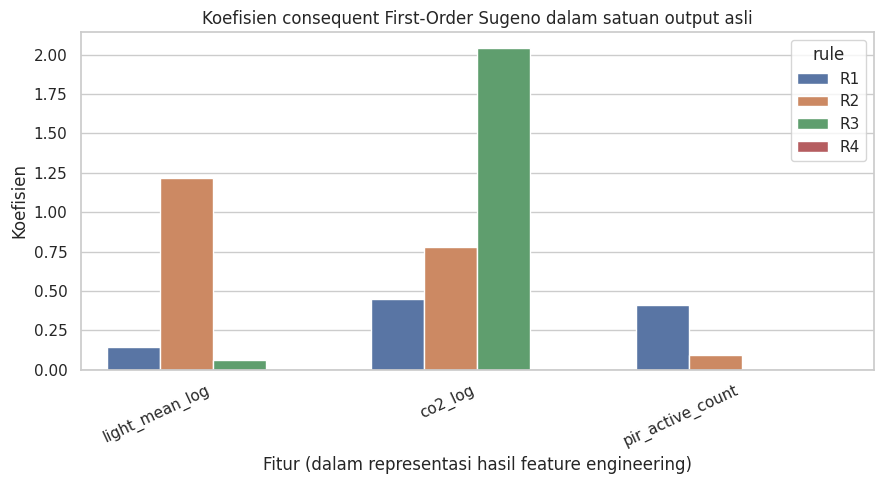

Koefisien berlaku pada fitur yang telah ditransformasi dan diskalakan. Interpretasi satu koefisien harus mempertimbangkan fitur lain dalam fungsi linear.


In [50]:
# 32A. Visualisasi koefisien consequent linear
coef_long = rule_consequents.melt(
    id_vars=["rule"], value_vars=selected_columns,
    var_name="fitur", value_name="koefisien"
)
plt.figure(figsize=(max(9, len(selected_columns) * 1.2), 5))
sns.barplot(data=coef_long, x="fitur", y="koefisien", hue="rule")
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Koefisien consequent First-Order Sugeno dalam satuan output asli")
plt.xlabel("Fitur (dalam representasi hasil feature engineering)")
plt.ylabel("Koefisien")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

print(
    "Koefisien berlaku pada fitur yang telah ditransformasi dan diskalakan. "
    "Interpretasi satu koefisien harus mempertimbangkan fitur lain dalam fungsi linear."
)

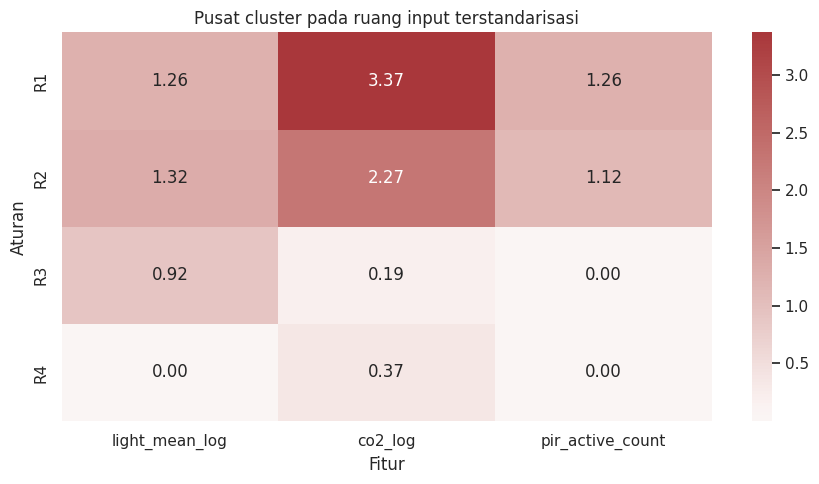

In [51]:
# 33. Visualisasi pusat cluster

profile_scaled = pd.DataFrame(
    final_fuzzy_model["centers_x"],
    columns=selected_columns,
    index=rule_names
)

plt.figure(figsize=(max(9, len(selected_columns) * 1.2), 5))
sns.heatmap(
    profile_scaled, annot=True, fmt=".2f",
    cmap="vlag", center=0
)
plt.title("Pusat cluster pada ruang input terstandarisasi")
plt.xlabel("Fitur")
plt.ylabel("Aturan")
plt.tight_layout()
plt.show()

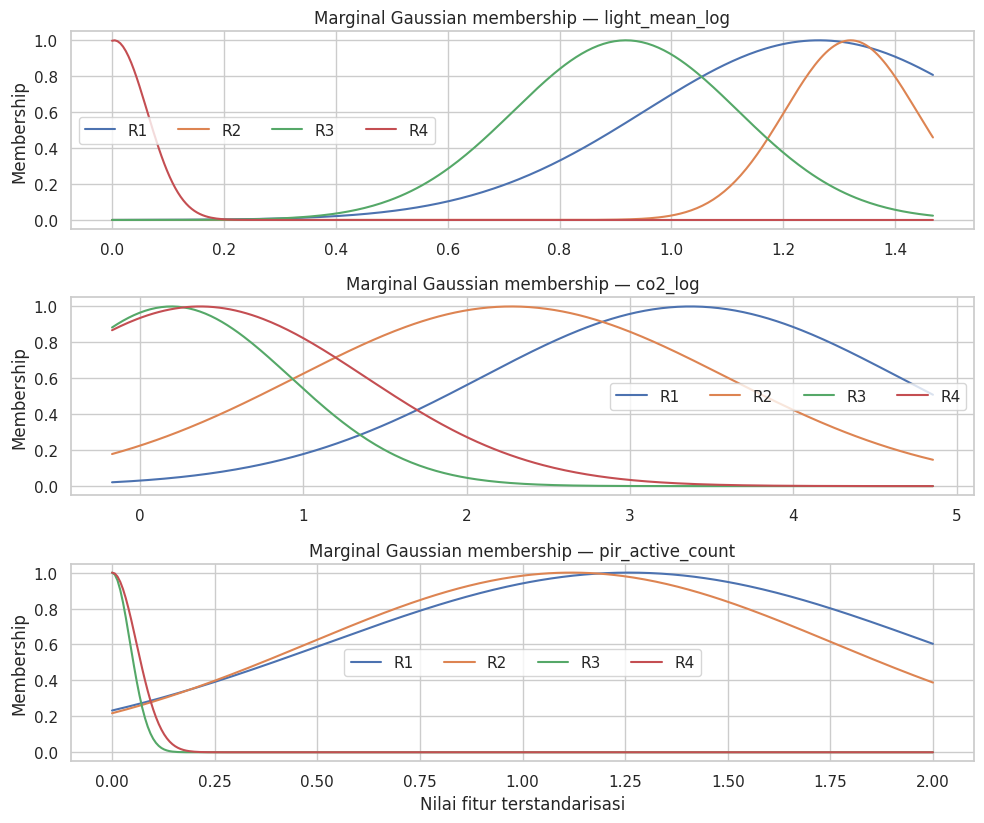

Kurva ini adalah tampilan marginal per fitur. Inferensi model tetap menggunakan kovarians multivariat penuh.


In [52]:
# 34. Melihat membership Gaussian marginal untuk beberapa fitur

selected_for_plot = [
    col for col in selected_columns
    if col in [
        "light_mean_log", "co2_log", "pir_active_count",
        "temp_mean", "sound_mean_log"
    ]
]

cov_x = final_fuzzy_model["covariances_x"]
centers_x = final_fuzzy_model["centers_x"]

fig, axes = plt.subplots(
    len(selected_for_plot), 1,
    figsize=(10, max(3, 2.8 * len(selected_for_plot))),
    squeeze=False
)

for ax, feature in zip(axes[:, 0], selected_for_plot):
    j = selected_columns.index(feature)
    center_scaled = centers_x[:, j]
    sigma_scaled = np.sqrt(np.maximum(cov_x[:, j, j], 1e-8))

    x_min = np.quantile(X_dev_scaled[:, j], 0.01)
    x_max = np.quantile(X_dev_scaled[:, j], 0.99)
    grid = np.linspace(x_min, x_max, 300)

    for i in range(SELECTED_C):
        membership = np.exp(
            -0.5 * ((grid - center_scaled[i]) / sigma_scaled[i]) ** 2
        )
        ax.plot(grid, membership, label=rule_names[i])

    ax.set_title(f"Marginal Gaussian membership — {feature}")
    ax.set_ylabel("Membership")
    ax.legend(ncol=min(SELECTED_C, 5))

plt.xlabel("Nilai fitur terstandarisasi")
plt.tight_layout()
plt.show()

print(
    "Kurva ini adalah tampilan marginal per fitur. "
    "Inferensi model tetap menggunakan kovarians multivariat penuh."
)

Target aktual: 1 orang
Langkah inferensi:


,urutan,nilai
0,1. Input hasil feature engineering,"{'light_mean_log': 4.178226046202803, 'co2_log..."
1,2. Setelah scaling,"[1.22252, 0.32246, 2.0]"
2,3. Firing strength R1...RC,"[0.05131, 0.94869, 0.0, 0.0]"
3,4. Local output tiap aturan,"[2.45743, 1.06274, 0.29061, -0.0]"
4,5. Kontribusi berbobot,"[0.12608, 1.00821, 0.0, -0.0]"
5,6. Output Sugeno mentah,1.1343
6,7. Setelah batas fisik,1.1343
7,8. Jumlah orang final,1


,rule,normalized_firing_strength,local_rule_output,weighted_contribution
1,R2,0.94869,1.06274,1.00821
0,R1,0.05131,2.45743,0.12608
2,R3,0.00000,0.29061,0.00000
3,R4,0.00000,-0.00000,-0.00000


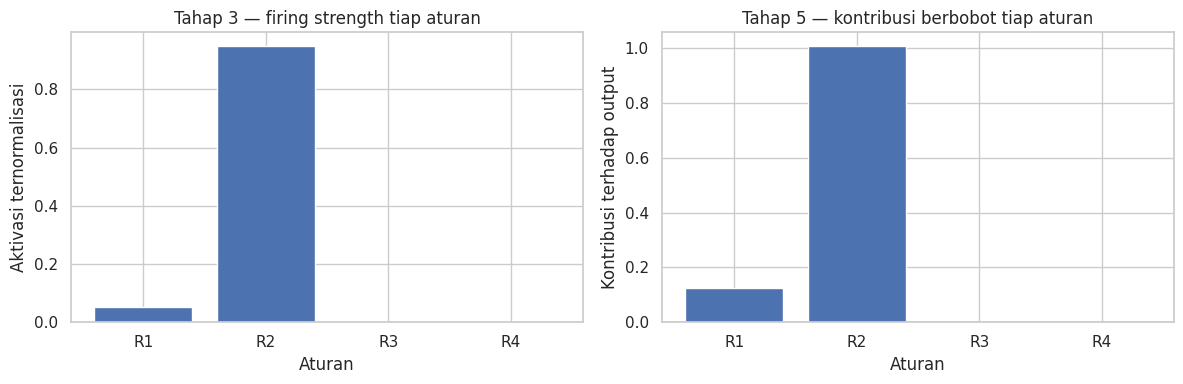

Output Sugeno mentah      = 1.13430
Output setelah clipping  = 1.13430
Estimasi jumlah penghuni = 1 orang
Jumlah penghuni aktual   = 1 orang


In [53]:
# 35. Menelusuri satu inferensi Sugeno langkah demi langkah

sample_position = min(10, len(X_test_scaled) - 1)
sample_x_raw_features = X_test_raw.iloc[sample_position]
sample_x_imputed = imputer_final.transform(
    X_test_raw.iloc[[sample_position]]
)
sample_x_scaled = x_scaler_final.transform(sample_x_imputed)

sample_pred_scaled, sample_firing, sample_local_scaled = predict_tsk_model(
    final_fuzzy_model, sample_x_scaled
)
sample_pred_raw = float(y_scaler_final.inverse_transform(
    sample_pred_scaled.reshape(-1, 1)
)[0, 0])
sample_pred_bounded = float(bound_occupancy_prediction([sample_pred_raw])[0])
sample_pred_count = int(to_count_prediction([sample_pred_raw])[0])
sample_actual = int(y_test_array[sample_position])

local_outputs_original = y_scaler_final.inverse_transform(
    sample_local_scaled.reshape(-1, 1)
).reshape(1, -1)[0]
contributions = sample_firing[0] * local_outputs_original

step_table = pd.DataFrame({
    "urutan": ["1. Input hasil feature engineering", "2. Setelah scaling", "3. Firing strength R1...RC", "4. Local output tiap aturan", "5. Kontribusi berbobot", "6. Output Sugeno mentah", "7. Setelah batas fisik", "8. Jumlah orang final"],
    "nilai": [
        sample_x_raw_features.to_dict(),
        np.round(sample_x_scaled[0], 5).tolist(),
        np.round(sample_firing[0], 5).tolist(),
        np.round(local_outputs_original, 5).tolist(),
        np.round(contributions, 5).tolist(),
        round(sample_pred_raw, 5),
        round(sample_pred_bounded, 5),
        sample_pred_count
    ]
})
print("Target aktual:", sample_actual, "orang")
print("Langkah inferensi:")
display(step_table)

activation_table = pd.DataFrame({
    "rule": rule_names,
    "normalized_firing_strength": sample_firing[0],
    "local_rule_output": local_outputs_original,
    "weighted_contribution": contributions
}).sort_values("normalized_firing_strength", ascending=False)
display(activation_table.round(5))

assert np.isclose(contributions.sum(), sample_pred_raw, atol=1e-6)
assert np.isclose(sample_firing.sum(), 1.0, atol=1e-8)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(rule_names, sample_firing[0])
axes[0].set_title("Tahap 3 — firing strength tiap aturan")
axes[0].set_xlabel("Aturan")
axes[0].set_ylabel("Aktivasi ternormalisasi")
axes[1].bar(rule_names, contributions)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Tahap 5 — kontribusi berbobot tiap aturan")
axes[1].set_xlabel("Aturan")
axes[1].set_ylabel("Kontribusi terhadap output")
plt.tight_layout()
plt.show()

print(f"Output Sugeno mentah      = {sample_pred_raw:.5f}")
print(f"Output setelah clipping  = {sample_pred_bounded:.5f}")
print(f"Estimasi jumlah penghuni = {sample_pred_count} orang")
print(f"Jumlah penghuni aktual   = {sample_actual} orang")

## 11. Menyimpan hasil untuk laporan dan GUI

Bagian ini menyimpan:
- metrik final,
- prediksi test,
- hasil pencarian konfigurasi dan pergeseran validation–test,
- audit WLS seluruh aturan,
- profil pusat cluster,
- koefisien konsekuen Sugeno,
- bundle model beserta imputer dan scaler.

Untuk GUI, input mentah harus diproses dengan rekayasa fitur yang sama seperti notebook: mean/std sensor S1–S4, `log1p` pada fitur positif yang dipilih, lalu imputer dan scaler yang sudah tersimpan.

In [54]:
# 37. Menyimpan tabel hasil eksperimen

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

test_result_df.to_csv(OUTPUT_DIR / "test_predictions_fuzzy_sugeno.csv", index=False)
search_results.to_csv(OUTPUT_DIR / "validation_model_search.csv", index=False)
refined_results.to_csv(OUTPUT_DIR / "validation_ridge_refinement.csv", index=False)
final_results.to_csv(OUTPUT_DIR / "final_test_metrics.csv")
raw_diagnostic.to_csv(OUTPUT_DIR / "raw_output_range_diagnostics.csv", index=False)
rule_profile.to_csv(OUTPUT_DIR / "rule_cluster_profiles.csv", index=False)
rule_consequents.to_csv(OUTPUT_DIR / "rule_consequents.csv", index=False)
rule_base_table.to_csv(OUTPUT_DIR / "rule_base_first_order_sugeno.csv", index=False)
split_counts.to_csv(OUTPUT_DIR / "split_class_counts.csv")
adjacent_block_df.to_csv(OUTPUT_DIR / "adjacent_block_diagnostic.csv", index=False)
validation_test_gap.to_csv(OUTPUT_DIR / "validation_test_performance_shift.csv", index=False)
wls_audit_summary.to_csv(OUTPUT_DIR / "wls_audit_all_rules_summary.csv", index=False)
wls_audit_coefficients.to_csv(OUTPUT_DIR / "wls_audit_all_rules_coefficients.csv", index=False)

print("Hasil tersimpan di:", OUTPUT_DIR.resolve())

Hasil tersimpan di: /kaggle/working/outputs


In [55]:
# 38. Mengekspor bundle model untuk Streamlit

dev_rows = np.r_[train_idx, val_idx]
raw_sensor_defaults = {
    col: float(df.iloc[dev_rows][col].median())
    for col in sensor_columns
}

model_bundle = {
    "project_name": "Room Occupancy Estimation — Fuzzy First-Order Sugeno",
    "dataset_source": "UCI Room Occupancy Estimation, DOI 10.24432/C5P605",
    "selected_feature_set": SELECTED_FEATURE_SET,
    "selected_method": SELECTED_METHOD,
    "n_rules": SELECTED_C,
    "weight_mode": SELECTED_WEIGHT_MODE,
    "m": SELECTED_M,
    "ridge_alpha": SELECTED_RIDGE_ALPHA,
    "feature_names": selected_columns,
    "raw_sensor_defaults": raw_sensor_defaults,
    "feature_ranges_1_99": {
        col: [float(X_dev_raw[col].quantile(0.01)), float(X_dev_raw[col].quantile(0.99))]
        for col in selected_columns
    },
    "imputer": imputer_final,
    "x_scaler": x_scaler_final,
    "y_scaler": y_scaler_final,
    "centers_x": final_fuzzy_model["centers_x"],
    "covariances_x": final_fuzzy_model["covariances_x"],
    "consequents_scaled": final_fuzzy_model["consequents"],
    "rule_profile": rule_profile,
    "rule_consequents": rule_consequents,
    "rule_base_table": rule_base_table,
    "target_range": [0, 3],
    "antecedent_membership": "normalized ellipsoidal Gaussian from projected cluster covariance",
    "consequent_estimation": "Augmented Weighted Ridge Least Squares using the same input-space antecedent memberships as inference",
    "wls_solver": "augmented_lstsq",
    "selection_metric_primary": "validation_MAE_bounded",
    "selection_secondary_metrics": ["validation_Macro_F1", "validation_Balanced_Accuracy", "validation_Out_of_range_rate_raw", "validation_MAE_raw", "fewer_rules_as_tiebreaker"],
    "evaluation_protocol": "blocked_stratified_internal_holdout; not future forecasting",
    "non_fuzzy_models_role": "optional supplementary benchmarks, not part of the fuzzy system",
    "convergence": {
        "tolerance": CONVERGENCE_TOL,
        "iterations": final_fuzzy_model["cluster"]["iterations"],
        "final_consistency_delta": final_fuzzy_model["cluster"]["delta"],
        "n_init_converged": final_fuzzy_model["cluster"]["n_init_converged"],
        "n_init_total": final_fuzzy_model["cluster"]["n_init_total"],
        "partition_ari_mean": final_fuzzy_model["cluster"]["partition_ari_mean"],
        "partition_ari_min": final_fuzzy_model["cluster"]["partition_ari_min"]
    }
}

joblib.dump(
    model_bundle,
    OUTPUT_DIR / "room_occupancy_fuzzy_sugeno_bundle.joblib"
)
print(
    "Bundle model tersimpan:",
    (OUTPUT_DIR / "room_occupancy_fuzzy_sugeno_bundle.joblib").resolve()
)

Bundle model tersimpan: /kaggle/working/outputs/room_occupancy_fuzzy_sugeno_bundle.joblib


## 13. Menyusun pembahasan hasil untuk laporan

Gunakan output aktual notebook; jangan mengisi angka dengan perkiraan.

### A. Dataset dan EDA
- Jelaskan tujuh node sensor dan mengapa temperatur, cahaya, serta suara memiliki empat kolom.
- Laporkan distribusi target, missing values, duplikasi, interval waktu, dan sesi pengukuran.
- Jelaskan bahwa distribusi non-normal tidak otomatis menggugurkan FCM/GK; clustering berbasis jarak tidak mensyaratkan setiap fitur normal.
- Bahas outlier sebagai kandidat pemeriksaan, bukan otomatis dihapus.
- Jelaskan korelasi positif/negatif sebagai asosiasi, bukan sebab-akibat.

### B. Feature engineering dan preprocessing
- Bandingkan fitur compact dan extended berdasarkan validation set.
- Jelaskan agregasi mean/std sensor S1–S4 dan transformasi `log1p` untuk fitur positif yang skewed.
- Jelaskan alasan RobustScaler: perbedaan satuan dan ketahanan relatif terhadap nilai ekstrem.
- Tegaskan bahwa imputer dan scaler hanya di-fit pada train ketika pencarian konfigurasi dilakukan.

### C. Desain evaluasi dan pergeseran validation–test
- Jelaskan blocked stratified holdout dan alasan split kronologis murni tidak memuat semua kelas pada setiap subset.
- Laporkan jumlah serta proporsi pasangan blok bersebelahan lintas subset. Tegaskan bahwa blok tidak overlap, tetapi ketergantungan temporal antar-blok masih mungkin tersisa.
- Bahas tabel validation–test performance shift. Validation adalah data seleksi hyperparameter sehingga dapat optimistis; test adalah hasil evaluasi utama. Perbandingan bukan generalization gap murni karena model final dilatih ulang pada train+validation.
- Jangan menyebut protokol ini forecasting atau future holdout.

### D. Clustering fuzzy
- Laporkan metode, jumlah cluster, fuzzifier, objective, iterasi, convergence delta, jumlah inisialisasi konvergen, dan massa efektif cluster. Jelaskan bahwa konfigurasi hanya eligible bila memenuhi multi-start convergence gate.
- Sajikan pusat cluster, kovarians, membership product-space, dan PCA.
- Bandingkan FCM (Euclidean) dengan GK (metrik kovarians adaptif).
- Jelaskan FPC, PE, MPC, dan Xie–Beni sebagai indeks partisi; jangan menyamakan indeks partisi dengan akurasi prediksi.

### E. Pembentukan aturan dan estimasi parameter
- Setiap cluster menjadi satu aturan First-Order Sugeno.
- Antecedent berasal dari proyeksi pusat dan blok kovarians cluster ke ruang input. R1, R2, dan seterusnya adalah identitas region multivariat, bukan label linguistik satu dimensi.
- Membership antecedent yang sama digunakan untuk menghitung firing strength dan membobot estimasi consequent.
- Consequent linear diestimasi dengan augmented Weighted Ridge Least Squares.
- Sajikan audit WLS untuk seluruh aturan: effective sample size, rank, singular value, condition number, dan selisih koefisien hasil hitung ulang. Condition number tinggi tetap dibahas sebagai potensi sensitivitas.
- Tunjukkan satu contoh inferensi lengkap dari input sampai output akhir.

### F. Evaluasi dan interpretasi
- Laporkan MAE/RMSE raw dan bounded, exact count accuracy, Macro F1, balanced accuracy, confusion matrix, dan support setiap kelas.
- Laporkan raw out-of-range rate, arah pelanggaran (di bawah 0 atau di atas 3), dan rata-rata jarak di luar rentang agar clipping tidak menyembunyikan perilaku model.
- Dummy Mean dan Random Forest adalah **pembanding tambahan**, bukan metode utama dan bukan kewajiban eksplisit tugas. Dummy menunjukkan baseline konstan; Random Forest memberi konteks benchmark non-fuzzy.
- Jika Random Forest lebih baik, nyatakan apa adanya. Karena Random Forest tidak dituning khusus, sebut sebagai benchmark dengan konfigurasi yang digunakan, bukan model optimal.
- Jika ingin laporan ringkas, tampilkan baseline dalam satu tabel dan fokuskan narasi pada fuzzy model.
- Jangan membandingkan angka dengan paper occupancy secara langsung jika protokol split dan fitur berbeda.

### G. Keterbatasan
- Dataset satu ruangan eksperimen; validasi eksternal masih diperlukan.
- Target kelas minoritas memiliki support lebih kecil; metrik per kelas harus dibaca bersama support.
- Blocked stratified holdout bukan pengujian masa depan murni; pasangan blok bersebelahan lintas subset menunjukkan ketergantungan temporal masih mungkin tersisa.
- Antecedent multivariat lebih sulit diterjemahkan menjadi label linguistik satu dimensi.
- Fuzzy model linear lokal dapat kalah akurasi dari model non-fuzzy yang lebih fleksibel.

## 15. Referensi

### Dataset dan studi kasus

1. Singh, A., & Chaudhari, S. (2018). *Room Occupancy Estimation* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5P605.
2. Singh, A. P., Jain, V., Chaudhari, S., Kraemer, F., Werner, S., & Garg, V. (2018). Machine learning-based occupancy estimation using multivariate sensor nodes. *2018 IEEE Globecom Workshops*. https://doi.org/10.1109/GLOCOMW.2018.8644432.

### Himpunan fuzzy, operator, dan fuzzy clustering

3. Zadeh, L. A. (1965). Fuzzy sets. *Information and Control, 8*(3), 338–353. https://doi.org/10.1016/S0019-9958(65)90241-X.
4. Bezdek, J. C. (1981). *Pattern Recognition with Fuzzy Objective Function Algorithms*. Plenum Press.
5. Luthfi, E. T. (2007). Fuzzy C-Means untuk clustering data (Studi kasus: Data performance mengajar dosen). *Seminar Nasional Teknologi 2007 (SNT 2007)*, Yogyakarta.
6. Gustafson, D. E., & Kessel, W. C. (1978). Fuzzy clustering with a fuzzy covariance matrix. *Proceedings of the 1978 IEEE Conference on Decision and Control*, 761–766. https://doi.org/10.1109/CDC.1978.268028.

### Fuzzy model dan estimasi parameter

8. Takagi, T., & Sugeno, M. (1985). Fuzzy identification of systems and its applications to modeling and control. *IEEE Transactions on Systems, Man, and Cybernetics, 15*(1), 116–132. https://doi.org/10.1109/TSMC.1985.6313399.
9. Gómez-Skarmeta, A. F., Delgado, M., & Vila, M. A. (1999). About the use of fuzzy clustering techniques for fuzzy model identification. *Fuzzy Sets and Systems, 106*(2), 179–188. https://doi.org/10.1016/S0165-0114(97)00276-5.